# Pipeline complet — IA explicable et multimodale pour l'aide au diagnostic du cancer de la peau

Exécution sur Kaggle des 6 étapes du projet, dans l'ordre :
**01** exploration et découpage · **02** baselines · **03** DermLIP · **04** concepts · **05** fusion et test final · **06** explicabilité.

**Réglages du notebook** : accélérateur **GPU**, **Internet activé** (installation d'`open_clip_torch`, poids ViT ImageNet et DermLIP).
Toutes les sorties (figures, tableaux, modèle final) sont écrites dans `/kaggle/working` et téléchargeables dans l'onglet *Output*.

In [1]:
# Installation spécifique à Kaggle : reproduit l'arborescence du projet dans /kaggle/working
import os, subprocess, sys
from pathlib import Path

WORK = Path("/kaggle/working")
os.chdir(WORK)
meta = next(Path("/kaggle/input").rglob("metadata.csv"))
data_dir = meta.parent
proj_data = WORK / "zr7vgbcyr2-1"
proj_data.mkdir(exist_ok=True)
if not (proj_data / "metadata.csv").exists():
    (proj_data / "metadata.csv").symlink_to(meta)
img_src = data_dir / "images" if (data_dir / "images").exists() else data_dir
if not (proj_data / "images").exists():
    (proj_data / "images").symlink_to(img_src, target_is_directory=True)
n_png = sum(1 for _ in (proj_data / "images").rglob("*.png"))
print("Données :", data_dir, "| images PNG trouvées :", n_png)
assert n_png == 2298, "nombre d'images inattendu"

(WORK / "configs").mkdir(exist_ok=True)
(WORK / "configs" / "concepts.yaml").write_text(r'''# Vocabulaire de concepts cliniques utilisé par le notebook 04 (score de concepts DermLIP).
#
# Chaque concept est décrit par plusieurs formulations en anglais (langue d'entraînement de DermLIP) ;
# leurs plongements sont moyennés. Le score d'une image = similarité avec le concept
# moins similarité avec les phrases de référence neutres.
#
# Champs :
#   name            identifiant (sans espace)
#   label_fr        libellé affiché dans les explications
#   group           famille du concept (forme, surface, couleur, vaisseaux, contexte, artefact)
#   expected        diagnostics où le concept est attendu (sert seulement à vérifier la cohérence, jamais à sélectionner)
#   related_symptom symptôme clinique de PAD-UFES-20 lié au concept (contrôle de validité), ou null
#   artefact        true = concept de surveillance (biais), jamais utilisé comme variable du modèle
#   prompts         formulations du concept

reference_prompts:
  - "a clinical photo of skin."
  - "a close-up photo of a skin lesion."
  - "a smartphone photo of the skin."

concepts:
  - name: pearly_translucent
    label_fr: "aspect perlé ou translucide"
    group: surface
    expected: [BCC]
    related_symptom: null
    prompts:
      - "a pearly translucent skin lesion"
      - "a shiny pearly papule on the skin"
      - "a translucent nodule with a pearly rolled border"

  - name: telangiectasia
    label_fr: "petits vaisseaux visibles (télangiectasies)"
    group: vaisseaux
    expected: [BCC]
    related_symptom: null
    prompts:
      - "a skin lesion with visible thin blood vessels"
      - "arborizing red vessels on a skin lesion"
      - "telangiectasia on the surface of a lesion"

  - name: ulceration
    label_fr: "ulcération"
    group: surface
    expected: [BCC, SCC]
    related_symptom: bleed
    prompts:
      - "an ulcerated skin lesion"
      - "a skin lesion with an open ulcer"
      - "an ulcer in the center of a skin tumor"

  - name: crust
    label_fr: "croûte"
    group: surface
    expected: [SCC, BCC]
    related_symptom: bleed
    prompts:
      - "a skin lesion covered with a crust"
      - "a crusted skin lesion"
      - "a scab on top of a skin lesion"

  - name: bleeding
    label_fr: "saignement"
    group: surface
    expected: [BCC, SCC]
    related_symptom: bleed
    prompts:
      - "a bleeding skin lesion"
      - "a skin lesion with fresh blood"
      - "a friable lesion that bleeds easily"

  - name: scale
    label_fr: "squames (surface rugueuse)"
    group: surface
    expected: [ACK, SCC]
    related_symptom: null
    prompts:
      - "a rough scaly patch of skin"
      - "a skin lesion with white scales"
      - "a dry scaly keratotic lesion"

  - name: hyperkeratosis
    label_fr: "hyperkératose (corne cutanée)"
    group: surface
    expected: [SCC]
    related_symptom: null
    prompts:
      - "a thick hyperkeratotic skin lesion"
      - "a horn-like keratin growth on the skin"
      - "a cutaneous horn"

  - name: erythema
    label_fr: "rougeur (érythème)"
    group: couleur
    expected: [ACK, SCC, BCC]
    related_symptom: null
    prompts:
      - "a red erythematous skin patch"
      - "a pink red lesion on the skin"
      - "redness and inflammation of the skin"

  - name: nodule
    label_fr: "nodule surélevé"
    group: forme
    expected: [BCC, SCC]
    related_symptom: elevation
    prompts:
      - "a raised firm nodule on the skin"
      - "a dome-shaped skin nodule"
      - "an elevated round tumor on the skin"

  - name: flat_patch
    label_fr: "tache plane"
    group: forme
    expected: [ACK, NEV]
    related_symptom: elevation
    prompts:
      - "a flat patch on the skin"
      - "a flat macule that is not raised"
      - "a flat discolored spot on the skin"

  - name: brown_uniform
    label_fr: "pigmentation brune uniforme"
    group: couleur
    expected: [NEV, SEK]
    related_symptom: null
    prompts:
      - "a uniformly brown pigmented lesion"
      - "an evenly colored brown mole"
      - "a light brown spot with a single color"

  - name: dark_pigmentation
    label_fr: "pigmentation très foncée"
    group: couleur
    expected: [MEL, SEK]
    related_symptom: null
    prompts:
      - "a very dark black pigmented lesion"
      - "a black skin lesion"
      - "a dark brown to black spot on the skin"

  - name: multicolor
    label_fr: "plusieurs couleurs"
    group: couleur
    expected: [MEL]
    related_symptom: changed
    prompts:
      - "a lesion with multiple colors brown black and blue"
      - "a variegated pigmented lesion"
      - "an irregularly colored mole"

  - name: irregular_border
    label_fr: "bords irréguliers, asymétrie"
    group: forme
    expected: [MEL, BCC]
    related_symptom: changed
    prompts:
      - "a lesion with irregular jagged borders"
      - "an asymmetric lesion with an irregular edge"
      - "a pigmented lesion with poorly defined borders"

  - name: regular_border
    label_fr: "bords réguliers, forme symétrique"
    group: forme
    expected: [NEV]
    related_symptom: null
    prompts:
      - "a small round symmetric lesion with a smooth regular border"
      - "a symmetric oval mole"
      - "a well circumscribed round lesion"

  - name: stuck_on
    label_fr: "aspect « posé » cireux"
    group: surface
    expected: [SEK]
    related_symptom: null
    prompts:
      - "a waxy stuck-on lesion"
      - "a lesion that looks pasted on the skin"
      - "a stuck-on warty plaque"

  - name: verrucous
    label_fr: "surface verruqueuse"
    group: surface
    expected: [SEK]
    related_symptom: null
    prompts:
      - "a warty verrucous surface"
      - "a lesion with a rough cerebriform surface"
      - "a papillomatous wart-like lesion"

  - name: sun_damage
    label_fr: "peau abîmée par le soleil"
    group: contexte
    expected: [ACK, BCC, SCC]
    related_symptom: null
    prompts:
      - "sun damaged skin with freckles and wrinkles"
      - "photodamaged skin of an elderly person"
      - "chronically sun exposed skin"

  - name: skin_marker_ink
    label_fr: "marque de stylo chirurgical"
    group: artefact
    artefact: true
    expected: []
    related_symptom: null
    prompts:
      - "a skin lesion marked with a surgical skin marker pen"
      - "blue ink drawn around a skin lesion"
      - "pen marks on the skin"
''', encoding="utf8")

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=True)
import torch
print("GPU :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "aucun")

Données : /kaggle/input/datasets/mohamedelaazzaoui/datasetconcer | images PNG trouvées : 2298
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.1 MB/s eta 0:00:00
GPU : Tesla T4


**Accès à DermLIP** : le modèle `redlessone/DermLIP_ViT-B-16` est à accès conditionnel sur Hugging Face (licence CC BY-NC-ND 4.0).
Prérequis : accepter ses conditions sur huggingface.co avec votre compte, créer un jeton en lecture, puis l'ajouter dans Kaggle (*Add-ons → Secrets*) sous le nom `HF_TOKEN` (ou `claudJeton`) et l'activer pour ce notebook.

In [2]:
import os
try:
    from kaggle_secrets import UserSecretsClient
    secrets = UserSecretsClient()
    for label in ("HF_TOKEN", "claudJeton"):          # noms de secret acceptés
        try:
            os.environ["HF_TOKEN"] = secrets.get_secret(label)
            print(f"Jeton Hugging Face chargé depuis le secret Kaggle « {label} ».")
            break
        except Exception:
            continue
    else:
        raise KeyError("aucun secret trouvé")
except Exception as e:
    raise RuntimeError("Secret Hugging Face introuvable : ajoutez-le dans Add-ons → Secrets et cochez-le (voir cellule précédente).") from e

Jeton Hugging Face chargé depuis le secret Kaggle « claudJeton ».


---
# PARTIE 01 — Exploration et préparation

# 01 — Exploration et préparation de PAD-UFES-20

**Objectifs**
1. Vérifier l'intégrité du dataset (images ↔ CSV, doublons).
2. Créer la cible binaire : cancer (BCC, SCC, MEL) / non-cancer (ACK, NEV, SEK).
3. Analyser les valeurs manquantes et détecter les raccourcis.
4. Choisir les variables cliniques du modèle.
5. Découper les données par patient (test + 5 plis) et sauvegarder `data/processed/splits.csv`.

**Sorties** : `data/processed/splits.csv` et 3 figures dans `outputs/figures/`.

## 1. Imports et constantes

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

SEED = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "zr7vgbcyr2-1"
CSV_PATH = DATA_DIR / "metadata.csv"
IMG_DIR = DATA_DIR / "images"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

CANCER_CLASSES = {"BCC", "SCC", "MEL"}
print("Racine du projet :", ROOT)

Racine du projet : /kaggle/working


## 2. Chargement et contrôles d'intégrité

Les valeurs `UNK` du CSV sont lues comme manquantes (`NaN`). Les images sont réparties dans 3 sous-dossiers : on construit un index `img_id → chemin`.

In [4]:
df = pd.read_csv(CSV_PATH, na_values=["UNK"])
print("Dimensions :", df.shape)
print("img_id dupliqués :", df["img_id"].duplicated().sum())
print("Patients :", df["patient_id"].nunique(), "| lésions (patient, lésion) :",
      df[["patient_id", "lesion_id"]].drop_duplicates().shape[0])

img_paths = {p.name: p for p in IMG_DIR.rglob("*.png")}
missing_imgs = set(df["img_id"]) - set(img_paths)
extra_imgs = set(img_paths) - set(df["img_id"])
print("Images trouvées :", len(img_paths), "| sans image :", len(missing_imgs),
      "| sans ligne CSV :", len(extra_imgs))
assert not missing_imgs and not extra_imgs, "incohérence entre images et CSV"

df["img_path"] = df["img_id"].map(lambda i: img_paths[i].relative_to(ROOT).as_posix())
print(df.iloc[11])

Dimensions : (2298, 26)
img_id dupliqués : 0
Patients : 1373 | lésions (patient, lésion) : 1891
Images trouvées : 2298 | sans image : 0 | sans ligne CSV : 0
patient_id                                                       PAT_967
lesion_id                                                           1827
smoke                                                              False
drink                                                              False
background_father                                              POMERANIA
background_mother                                              POMERANIA
age                                                                   34
pesticide                                                           True
gender                                                            FEMALE
skin_cancer_history                                                 True
cancer_history                                                     False
has_piped_water                         

## 3. Création de la cible binaire

In [5]:
df["label"] = df["diagnostic"].isin(CANCER_CLASSES).astype(int)
print(df["label"].value_counts())
print(pd.crosstab(df["diagnostic"], df["label"]))

label
0    1209
1    1089
Name: count, dtype: int64
label         0    1
diagnostic          
ACK         730    0
BCC           0  845
MEL           0   52
NEV         244    0
SCC           0  192
SEK         235    0


## 4. Distribution des classes

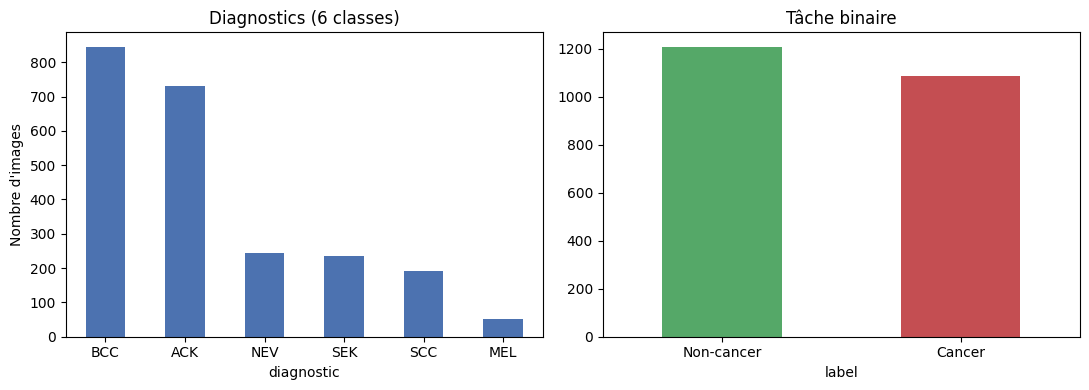

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["diagnostic"].value_counts().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Diagnostics (6 classes)")
axes[0].set_ylabel("Nombre d'images")
df["label"].map({0: "Non-cancer", 1: "Cancer"}).value_counts().plot.bar(
    ax=axes[1], color=["#55A868", "#C44E52"])
axes[1].set_title("Tâche binaire")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "01_distribution_classes.png", dpi=150)
plt.show()

## 5. Valeurs manquantes

In [7]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print((missing / len(df) * 100).round(1).astype(str) + " %")

background_father      39.7 %
background_mother      39.4 %
smoke                  35.0 %
drink                  35.0 %
pesticide              35.0 %
gender                 35.0 %
skin_cancer_history    35.0 %
cancer_history         35.0 %
has_piped_water        35.0 %
has_sewage_system      35.0 %
fitspatrick            35.0 %
diameter_1             35.0 %
diameter_2             35.0 %
grew                   17.5 %
changed                17.2 %
hurt                    0.4 %
itch                    0.3 %
bleed                   0.3 %
elevation               0.1 %
dtype: object


## 6. Détection d'un raccourci

Les 9 colonnes du profil patient sont vides sur les mêmes 804 lignes. On vérifie si cette absence dépend du diagnostic : si oui, le modèle pourrait prédire le cancer à partir du simple fait que le profil est vide.

In [8]:
PROFILE_COLS = ["smoke", "drink", "pesticide", "gender", "skin_cancer_history",
                "cancer_history", "fitspatrick", "diameter_1", "diameter_2"]
profile_missing = df[PROFILE_COLS].isna().any(axis=1)
print("Lignes sans profil :", profile_missing.sum())
print("Toutes les colonnes du profil vides ensemble :",
      (df[PROFILE_COLS].isna().all(axis=1) == profile_missing).all())

table = (df.assign(profile_missing=profile_missing)
           .groupby("diagnostic")["profile_missing"].mean().mul(100).round(1))
print("\n% de lignes sans profil par diagnostic :\n", table)

auc_shortcut = roc_auc_score(df["label"], (~profile_missing).astype(int))
print(f"\nAUC de la règle « profil complet => cancer » : {auc_shortcut:.3f}")

grew_missing = (df.groupby("diagnostic")["grew"]
                  .apply(lambda s: s.isna().mean() * 100).round(1))
print("\n% de `grew` manquant par diagnostic :\n", grew_missing)

Lignes sans profil : 804
Toutes les colonnes du profil vides ensemble : True

% de lignes sans profil par diagnostic :
 diagnostic
ACK    61.2
BCC     0.0
MEL     0.0
NEV    69.3
SCC     0.0
SEK    80.0
Name: profile_missing, dtype: float64

AUC de la règle « profil complet => cancer » : 0.833

% de `grew` manquant par diagnostic :
 diagnostic
ACK     0.8
BCC    31.5
MEL    21.2
NEV    14.8
SCC    39.1
SEK     3.4
Name: grew, dtype: float64


**Conclusion** : aucun cancer n'a un profil vide, contre 61 à 80 % des non-cancers. Une règle triviale atteint une AUC d'environ 0,83 sans regarder l'image : les variables du profil sont un **raccourci** et sont exclues du modèle. Pour la même raison, on ne crée pas d'indicateur de valeur manquante pour `grew` et `changed`.

## 7. Variables retenues et exclues

In [9]:
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS

EXCLUDED = {
    "raccourci (profil manquant)": PROFILE_COLS,
    "fuite (révèle le diagnostic)": ["biopsed"],
    "faible intérêt clinique / biais social": ["has_piped_water", "has_sewage_system",
                                              "background_father", "background_mother"],
}
print("Variables retenues :", FEATURES)
for reason, cols in EXCLUDED.items():
    print(f"Exclues ({reason}) :", cols)

print("\nManquants restants dans les variables retenues :")
print(df[FEATURES].isna().sum()[lambda s: s > 0])

Variables retenues : ['age', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'region']
Exclues (raccourci (profil manquant)) : ['smoke', 'drink', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'fitspatrick', 'diameter_1', 'diameter_2']
Exclues (fuite (révèle le diagnostic)) : ['biopsed']
Exclues (faible intérêt clinique / biais social) : ['has_piped_water', 'has_sewage_system', 'background_father', 'background_mother']

Manquants restants dans les variables retenues :
itch           6
grew         402
hurt          10
changed      396
bleed          6
elevation      2
dtype: int64


Les quelques manquants restants (`grew`, `changed`, et quelques symptômes) seront imputés **au moment de l'entraînement**, avec des valeurs apprises sur chaque pli d'entraînement uniquement (`src/data/preprocessing.py`), pour éviter toute fuite.

## 8. Analyse des variables retenues

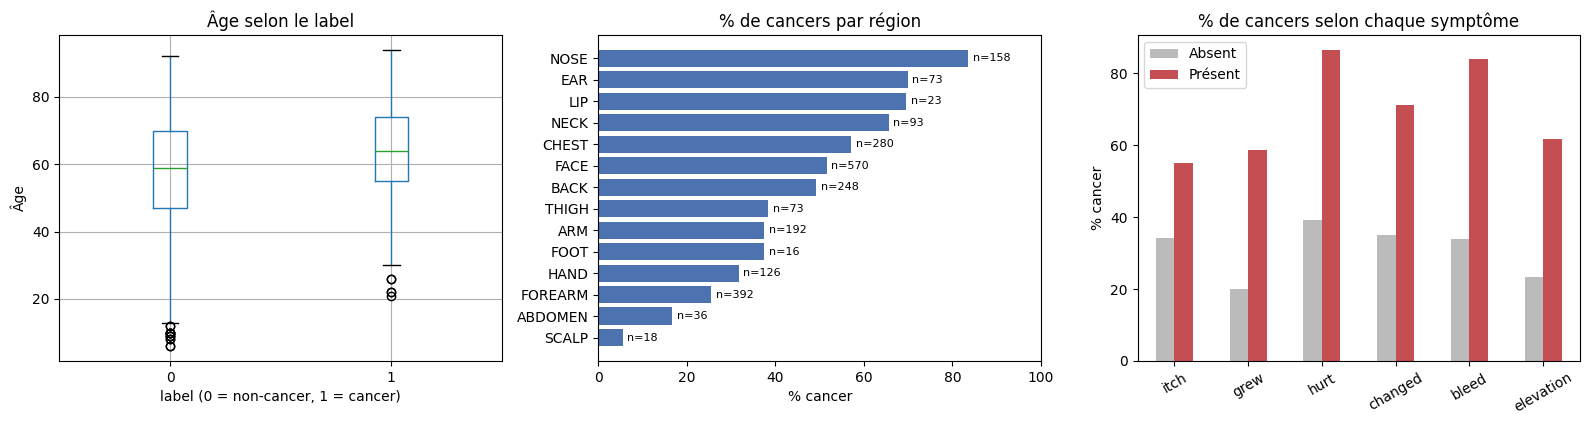

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

df.boxplot(column="age", by="label", ax=axes[0])
axes[0].set_title("Âge selon le label")
axes[0].set_xlabel("label (0 = non-cancer, 1 = cancer)")
axes[0].set_ylabel("Âge")

region = df.groupby("region")["label"].agg(["mean", "size"]).sort_values("mean")
axes[1].barh(region.index, region["mean"] * 100, color="#4C72B0")
axes[1].set_title("% de cancers par région")
axes[1].set_xlabel("% cancer")
axes[1].set_xlim(0, 100)
for i, (pct, n) in enumerate(zip(region["mean"] * 100, region["size"])):
    axes[1].text(pct + 1, i, f"n={n}", va="center", fontsize=8)

sympt = pd.DataFrame({c: df.groupby(c)["label"].mean() * 100 for c in BOOL_COLS}).T
sympt = sympt.rename(columns={False: "Absent", True: "Présent"})
sympt[["Absent", "Présent"]].plot.bar(ax=axes[2], color=["#BBBBBB", "#C44E52"])
axes[2].set_title("% de cancers selon chaque symptôme")
axes[2].set_ylabel("% cancer")
axes[2].tick_params(axis="x", rotation=30)

plt.suptitle("")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_variables_retenues.png", dpi=150)
plt.show()

## 9. Contrôle des images

Modes couleur (échantillon de 300) : {'RGBA': 200, 'RGB': 100}
Taille min : (147, 147) | taille max : (2683, 2683) | tailles distinctes : 266


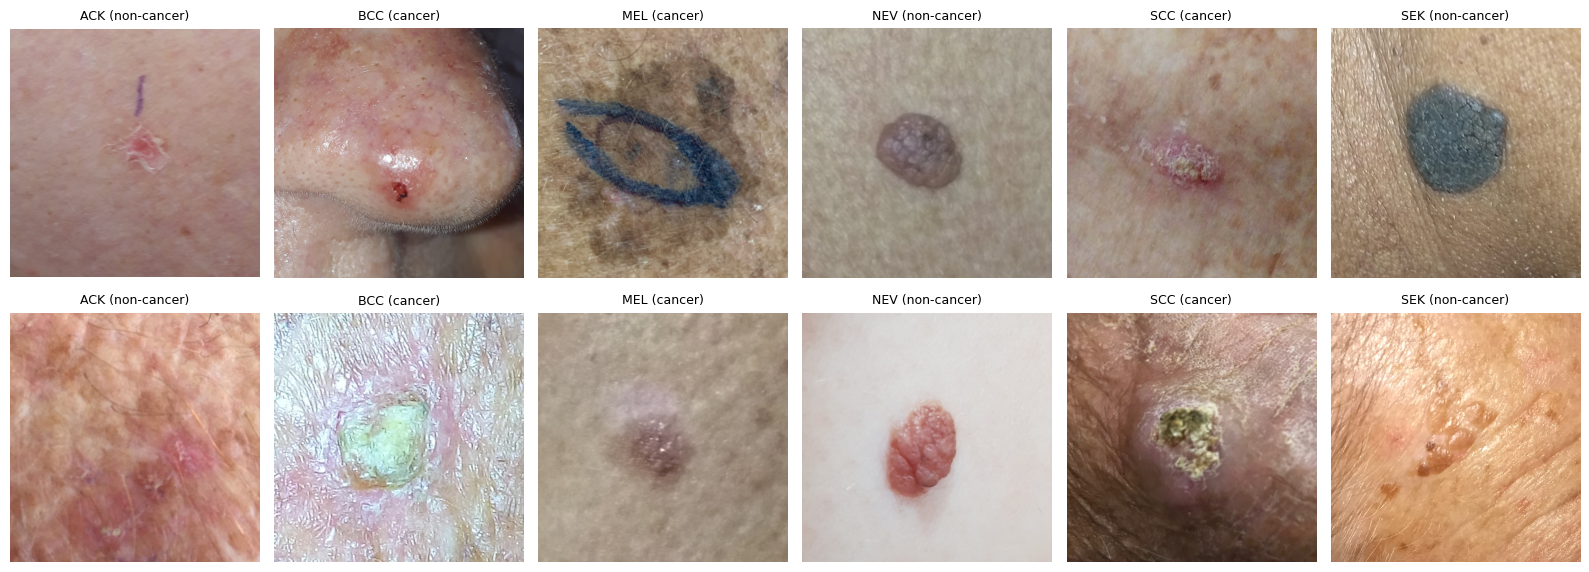

In [11]:
sample = df.sample(300, random_state=SEED)
sizes, modes = [], []
for p in sample["img_path"]:
    with Image.open(ROOT / p) as im:
        sizes.append(im.size)
        modes.append(im.mode)
sizes, modes = pd.Series(sizes), pd.Series(modes)
print("Modes couleur (échantillon de 300) :", modes.value_counts().to_dict())
print("Taille min :", min(sizes), "| taille max :", max(sizes),
      "| tailles distinctes :", sizes.nunique())

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for j, diag in enumerate(sorted(df["diagnostic"].unique())):
    rows = df[df["diagnostic"] == diag].sample(2, random_state=SEED)
    for i, (_, r) in enumerate(rows.iterrows()):
        ax = axes[i, j]
        with Image.open(ROOT / r["img_path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{diag} ({'cancer' if r['label'] else 'non-cancer'})", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_exemples_images.png", dpi=120)
plt.show()

**Conclusion** : une partie des images est en RGBA (4 canaux) et les tailles varient fortement. Le `Dataset` PyTorch devra convertir en RGB et redimensionner (224 × 224).

**Point de vigilance** : certaines lésions portent des **marques de stylo dermographique** (tracées avant une exérèse chirurgicale). Comme les lésions opérées sont souvent des cancers, le modèle pourrait apprendre à reconnaître l'encre plutôt que la lésion. À contrôler avec Grad-CAM (les cartes ne doivent pas se concentrer sur les traits d'encre) et en comparant les performances sur les images avec et sans marquage.

## 10. Découpage par patient

- Un ensemble de **test** (≈ 14 %) mis de côté jusqu'à l'évaluation finale.
- Le reste découpé en **5 plis** pour la validation croisée.
- Groupement par `patient_id` : aucun patient dans deux ensembles.
- Stratification sur les 6 diagnostics : les mélanomes (52 cas) sont présents partout.

In [12]:
df["split"] = "train"
df["fold"] = -1

outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
_, test_idx = next(outer.split(df, df["diagnostic"], groups=df["patient_id"]))
df.loc[test_idx, "split"] = "test"
print(df)
dev = df[df["split"] == "train"]
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (_, val_idx) in enumerate(inner.split(dev, dev["diagnostic"], groups=dev["patient_id"])):
    df.loc[dev.index[val_idx], "fold"] = k

     patient_id  lesion_id  smoke  drink background_father background_mother  \
0      PAT_1516       1765    NaN    NaN               NaN               NaN   
1        PAT_46        881  False  False         POMERANIA         POMERANIA   
2      PAT_1545       1867    NaN    NaN               NaN               NaN   
3      PAT_1989       4061    NaN    NaN               NaN               NaN   
4       PAT_684       1302  False   True         POMERANIA         POMERANIA   
...         ...        ...    ...    ...               ...               ...   
2293   PAT_1708       3156    NaN    NaN               NaN               NaN   
2294     PAT_46        880  False  False         POMERANIA         POMERANIA   
2295   PAT_1343       1217    NaN    NaN               NaN               NaN   
2296    PAT_326        690  False  False         POMERANIA         POMERANIA   
2297   PAT_1714       3189    NaN    NaN               NaN               NaN   

      age pesticide  gender skin_cancer

## 11. Vérifications du découpage

In [13]:
test_patients = set(df.loc[df["split"] == "test", "patient_id"])
dev_patients = set(df.loc[df["split"] == "train", "patient_id"])
assert not (test_patients & dev_patients), "patient commun entre test et train"

for k in range(5):
    p_k = set(df.loc[df["fold"] == k, "patient_id"])
    p_other = set(df.loc[(df["fold"] != k) & (df["split"] == "train"), "patient_id"])
    assert not (p_k & p_other), f"patient commun dans le pli {k}"
assert (df.loc[df["split"] == "train", "fold"] >= 0).all()
assert (df.loc[df["split"] == "test", "fold"] == -1).all()

groupe = np.where(df["split"] == "test", "test", "pli " + df["fold"].astype(str))
summary = (df.assign(groupe=groupe)
             .groupby("groupe")
             .agg(images=("img_id", "size"), patients=("patient_id", "nunique"),
                  pct_cancer=("label", lambda s: round(s.mean() * 100, 1))))
print(summary)
print(pd.crosstab(groupe, df["diagnostic"]))
print("OK : aucun patient commun entre test et plis, ni entre plis")

        images  patients  pct_cancer
groupe                              
pli 0      390       235        47.4
pli 1      372       235        43.3
pli 2      392       237        48.7
pli 3      391       236        48.6
pli 4      395       233        44.6
test       358       197        52.0
diagnostic  ACK  BCC  MEL  NEV  SCC  SEK
row_0                                   
pli 0       133  135    9   43   41   29
pli 1       134  117    3   38   41   39
pli 2       107  151    4   36   36   58
pli 3       129  159   13   39   18   33
pli 4       127  139   16   49   21   43
test        100  144    7   39   35   33
OK : aucun patient commun entre test et plis, ni entre plis


## 12. Sauvegarde

In [14]:
SPLIT_COLS = ["img_id", "patient_id", "lesion_id", "diagnostic", "label", "split", "fold", "img_path"]
df[SPLIT_COLS].to_csv(PROCESSED_DIR / "splits.csv", index=False)
print("Enregistré :", PROCESSED_DIR / "splits.csv", "|", len(df), "lignes")
pd.read_csv(PROCESSED_DIR / "splits.csv").head()

Enregistré : /kaggle/working/data/processed/splits.csv | 2298 lignes


,img_id,patient_id,lesion_id,diagnostic,label,split,fold,img_path
0,PAT_1516_1765_530.png,PAT_1516,1765,NEV,0,train,0,zr7vgbcyr2-1/images/imgs_part_3/imgs_part_3/PA...
1,PAT_46_881_939.png,PAT_46,881,BCC,1,train,4,zr7vgbcyr2-1/images/imgs_part_1/imgs_part_1/PA...
2,PAT_1545_1867_547.png,PAT_1545,1867,ACK,0,train,0,zr7vgbcyr2-1/images/imgs_part_3/imgs_part_3/PA...
3,PAT_1989_4061_934.png,PAT_1989,4061,ACK,0,train,0,zr7vgbcyr2-1/images/imgs_part_3/imgs_part_3/PA...
4,PAT_684_1302_588.png,PAT_684,1302,BCC,1,train,1,zr7vgbcyr2-1/images/imgs_part_2/imgs_part_2/PA...


## Conclusion

- Dataset complet : 2 298 images, 1 373 patients, aucune image manquante.
- Cible binaire équilibrée : 1 089 cancers (47 %) / 1 209 non-cancers.
- Raccourci détecté : profil patient absent pour 0 % des cancers et 61–80 % des non-cancers (AUC ≈ 0,83 sans image) → variables du profil exclues.
- Variables retenues : âge, région, 6 symptômes (`itch`, `grew`, `hurt`, `changed`, `bleed`, `elevation`).
- Images : conversion RGB et redimensionnement nécessaires.
- Vigilance : marques de stylo sur certaines lésions, risque de second raccourci à vérifier avec Grad-CAM.
- `splits.csv` : un ensemble de test + 5 plis groupés par patient, réutilisés par tous les notebooks suivants.

**Étape suivante** : `02_baselines.ipynb`.

---
# PARTIE 02 — Baselines

# 02 — Baselines

**Objectif** : mesurer ce que vaut chaque modalité **seule**, avant toute fusion. Ces chiffres servent de référence : le modèle multimodal final (notebook 05) devra faire mieux.

| ID | Expérience | Question |
|---|---|---|
| E0 | Modèle naïf (hasard stratifié) | Quel est le plancher ? |
| E1a | Clinique seule — régression logistique | Que valent les symptômes, avec un modèle interprétable ? |
| E1b | Clinique seule — gradient boosting | Un modèle non linéaire fait-il mieux ? |
| E2 | Image seule — ViT-B/16 ImageNet gelé + régression logistique | Que vaut l'image avec un encodeur générique ? |

**Protocole (identique pour toutes les expériences)**
- Données : ensemble `train` de `splits.csv` (1 969 images), **5 plis groupés par patient** créés dans le notebook 01.
- L'ensemble `test` n'est **pas utilisé** ici : il est réservé à l'évaluation finale.
- Tout prétraitement (imputation, encodage, standardisation) est appris **dans chaque pli d'entraînement** grâce à un `Pipeline` scikit-learn : aucune information du pli de validation ne fuit.
- Métrique principale : **AUC** (indépendante du seuil). Métriques secondaires au seuil 0,5 : exactitude équilibrée, sensibilité, spécificité, F1.
- Résultat rapporté : moyenne ± écart-type sur les 5 plis.

## 1. Imports et constantes

In [15]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_FOLDS = 5

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "zr7vgbcyr2-1" / "metadata.csv"
SPLITS_PATH = ROOT / "data" / "processed" / "splits.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# variables retenues dans le notebook 01 (le profil patient est exclu : raccourci)
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS

## 2. Chargement des données et du découpage

In [16]:
splits = pd.read_csv(SPLITS_PATH)
meta = pd.read_csv(CSV_PATH, na_values=["UNK"])

df = splits.merge(meta[["img_id"] + FEATURES], on="img_id", how="left", validate="one_to_one")
for c in BOOL_COLS:                                   # True / False / NaN -> 1.0 / 0.0 / NaN
    df[c] = df[c].map({True: 1.0, False: 0.0, "True": 1.0, "False": 0.0})

dev = df[df["split"] == "train"].reset_index(drop=True)
X_dev, y_dev, folds = dev[FEATURES], dev["label"].to_numpy(), dev["fold"].to_numpy()

print("Images de développement :", len(dev), "| patients :", dev["patient_id"].nunique())
print("Images par pli :", np.bincount(folds))
print("Manquants dans les variables :", X_dev.isna().sum()[lambda s: s > 0].to_dict())
assert set(folds) == set(range(N_FOLDS))

Images de développement : 1940 | patients : 1176
Images par pli : [390 372 392 391 395]
Manquants dans les variables : {'itch': 5, 'grew': 339, 'hurt': 9, 'changed': 335, 'bleed': 6, 'elevation': 2}


## 3. Fonction d'évaluation commune

`cross_validate` entraîne un modèle neuf sur 4 plis, l'évalue sur le 5ᵉ, et recommence 5 fois. Elle renvoie les métriques par pli et les prédictions « hors pli » (chaque image est prédite par un modèle qui ne l'a jamais vue).

In [17]:
def metrics_at(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y_true, proba),
        "Exactitude équilibrée": balanced_accuracy_score(y_true, y_pred),
        "Sensibilité": recall_score(y_true, y_pred, pos_label=1),
        "Spécificité": recall_score(y_true, y_pred, pos_label=0),
        "F1": f1_score(y_true, y_pred),
    }


def cross_validate(make_model, X, y, folds):
    oof = np.zeros(len(y))
    rows = []
    for k in range(N_FOLDS):
        tr, va = folds != k, folds == k
        model = make_model()
        model.fit(X[tr], y[tr])
        oof[va] = model.predict_proba(X[va])[:, 1]
        rows.append({"pli": k, **metrics_at(y[va], oof[va])})
    return pd.DataFrame(rows), oof


def summarize(name, per_fold):
    m = per_fold.drop(columns="pli")
    return {"Expérience": name, **{c: f"{m[c].mean():.3f} ± {m[c].std():.3f}" for c in m.columns}}


results, oof_preds = [], {}

## 4. E0 — Modèle naïf (plancher)

In [18]:
make_dummy = lambda: DummyClassifier(strategy="stratified", random_state=SEED)
per_fold, oof_preds["E0 Naïf"] = cross_validate(make_dummy, X_dev, y_dev, folds)
results.append(summarize("E0 Naïf", per_fold))
results[-1]

{'Expérience': 'E0 Naïf',
 'AUC': '0.503 ± 0.018',
 'Exactitude équilibrée': '0.503 ± 0.018',
 'Sensibilité': '0.471 ± 0.021',
 'Spécificité': '0.534 ± 0.015',
 'F1': '0.469 ± 0.019'}

## 5. E1 — Clinique seule

Prétraitement appris dans chaque pli :
- `age` : imputation par la médiane puis standardisation ;
- symptômes : imputation par la valeur la plus fréquente ;
- `region` : encodage one-hot (une région absente de l'entraînement est ignorée).

In [19]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUM_COLS),
        ("bool", SimpleImputer(strategy="most_frequent"), BOOL_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])


def make_logreg():
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])


def make_hgb():
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", HistGradientBoostingClassifier(class_weight="balanced", max_depth=3,
                                                            learning_rate=0.05, max_iter=300,
                                                            random_state=SEED))])


for name, factory in [("E1a Clinique – logistique", make_logreg),
                      ("E1b Clinique – boosting", make_hgb)]:
    per_fold, oof_preds[name] = cross_validate(factory, X_dev, y_dev, folds)
    results.append(summarize(name, per_fold))
    print(name); print(per_fold.round(3).to_string(index=False)); print()

E1a Clinique – logistique
 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.844                  0.763        0.746        0.780 0.750
   1 0.820                  0.745        0.727        0.763 0.713
   2 0.818                  0.716        0.675        0.756 0.699
   3 0.860                  0.774        0.753        0.796 0.765
   4 0.867                  0.767        0.716        0.817 0.737

E1b Clinique – boosting
 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.853                  0.770        0.789        0.751 0.764
   1 0.828                  0.742        0.702        0.782 0.706
   2 0.829                  0.747        0.723        0.771 0.736
   3 0.853                  0.786        0.811        0.761 0.786
   4 0.866                  0.794        0.784        0.804 0.773



### Interprétation du modèle logistique

Les coefficients indiquent l'effet de chaque variable sur la probabilité de cancer (modèle ajusté sur toutes les données de développement, à titre descriptif uniquement). Un rapport de cotes > 1 augmente le risque.

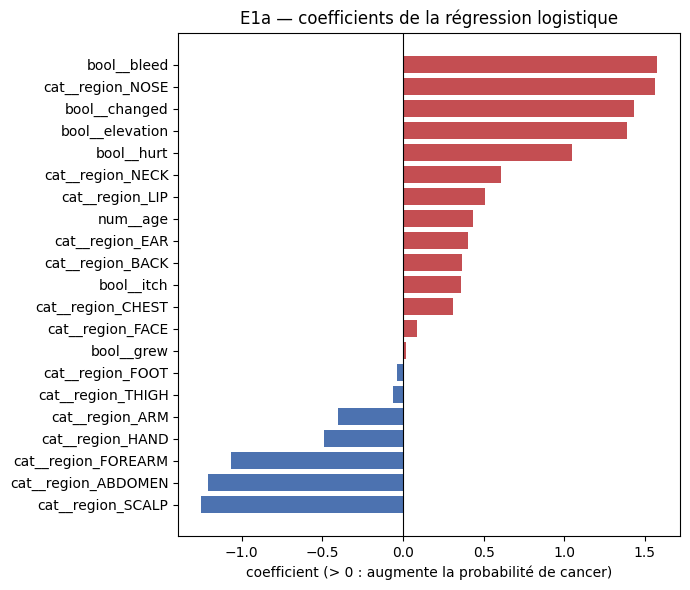

,variable,coefficient,rapport de cotes
0,num__age,0.433,1.541
16,cat__region_LIP,0.509,1.663
17,cat__region_NECK,0.611,1.842
3,bool__hurt,1.046,2.845
6,bool__elevation,1.388,4.005
4,bool__changed,1.433,4.193
18,cat__region_NOSE,1.564,4.779
5,bool__bleed,1.577,4.840


In [20]:
full = make_logreg().fit(X_dev, y_dev)
names = full.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"variable": names, "coefficient": full.named_steps["clf"].coef_[0]})
coefs["rapport de cotes"] = np.exp(coefs["coefficient"])
coefs = coefs.sort_values("coefficient")

plt.figure(figsize=(7, 6))
plt.barh(coefs["variable"], coefs["coefficient"],
         color=np.where(coefs["coefficient"] > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, color="black", lw=0.8)
plt.title("E1a — coefficients de la régression logistique")
plt.xlabel("coefficient (> 0 : augmente la probabilité de cancer)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_coefficients_logistique.png", dpi=150)
plt.show()
coefs.round(3).tail(8)

## 6. E2 — Image seule (encodeur ImageNet gelé)

On utilise un **ViT-B/16 préentraîné sur ImageNet**, même architecture que DermLIP-B/16 : la comparaison du notebook 03 sera donc équitable. L'encodeur est **gelé** : on extrait une fois un vecteur de 768 valeurs par image, puis on entraîne une régression logistique (« sonde linéaire ») dans chaque pli.

*L'ajustement fin de l'encodeur demande un GPU ; il sera fait plus tard sur Colab. La sonde linéaire est le protocole standard pour comparer des encodeurs.*

Les caractéristiques sont mises en cache dans `data/processed/` : l'extraction (quelques minutes sur CPU) n'est faite qu'une fois.

> **Attention** : la première exécution de la cellule suivante **télécharge les poids** `vit_b_16-c867db91.pth` (≈ 330 Mo) depuis le site officiel PyTorch (`download.pytorch.org`), puis extrait les caractéristiques des 2 298 images (≈ 5 à 15 min sur CPU). Sur Colab avec GPU, l'extraction prend moins d'une minute.

In [21]:
import torch
from PIL import Image
from torchvision.models import ViT_B_16_Weights, vit_b_16

FEAT_PATH = PROCESSED_DIR / "features_imagenet_vitb16.npy"
IDS_PATH = PROCESSED_DIR / "features_imagenet_vitb16_ids.csv"

if FEAT_PATH.exists() and IDS_PATH.exists():
    feats = np.load(FEAT_PATH)
    feat_ids = pd.read_csv(IDS_PATH)["img_id"].tolist()
    print("Caractéristiques chargées depuis le cache :", feats.shape)
else:
    torch.manual_seed(SEED)
    torch.set_num_threads(max(1, torch.get_num_threads()))
    weights = ViT_B_16_Weights.IMAGENET1K_V1
    encoder = vit_b_16(weights=weights)
    encoder.heads = torch.nn.Identity()          # on garde le vecteur de 768 valeurs
    encoder.eval()
    preprocess = weights.transforms()            # redimensionnement, recadrage 224, normalisation

    feat_ids = df["img_id"].tolist()
    paths = (ROOT / df["img_path"]).tolist()
    feats, t0 = [], time.time()
    with torch.no_grad():
        for start in range(0, len(paths), 32):
            batch = []
            for p in paths[start:start + 32]:
                with Image.open(p) as im:
                    batch.append(preprocess(im.convert("RGB")))
            feats.append(encoder(torch.stack(batch)).numpy())
            if start % 320 == 0:
                print(f"{start + len(batch)}/{len(paths)} images — {time.time() - t0:.0f} s")
    feats = np.concatenate(feats).astype(np.float32)
    np.save(FEAT_PATH, feats)
    pd.DataFrame({"img_id": feat_ids}).to_csv(IDS_PATH, index=False)
    print("Caractéristiques extraites :", feats.shape, f"en {time.time() - t0:.0f} s")

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:01<00:00, 245MB/s]


32/2298 images — 13 s
352/2298 images — 141 s
672/2298 images — 265 s
992/2298 images — 391 s
1312/2298 images — 518 s
1632/2298 images — 646 s
1952/2298 images — 775 s
2272/2298 images — 900 s
Caractéristiques extraites : (2298, 768) en 909 s


In [22]:
index = {img_id: i for i, img_id in enumerate(feat_ids)}
X_img_dev = feats[[index[i] for i in dev["img_id"]]]
assert X_img_dev.shape == (len(dev), 768)


def make_linear_probe():
    return Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))])


name = "E2 Image – ViT ImageNet gelé"
per_fold, oof_preds[name] = cross_validate(make_linear_probe, X_img_dev, y_dev, folds)
results.append(summarize(name, per_fold))
print(per_fold.round(3).to_string(index=False))

 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.820                  0.755        0.730        0.780 0.740
   1 0.810                  0.759        0.745        0.773 0.729
   2 0.834                  0.744        0.712        0.776 0.731
   3 0.825                  0.755        0.758        0.751 0.750
   4 0.832                  0.763        0.773        0.753 0.743


## 7. Comparaison des baselines

In [23]:
table = pd.DataFrame(results).set_index("Expérience")
table.to_csv(REPORT_DIR / "02_baselines_resultats.csv")
table

,AUC,Exactitude équilibrée,Sensibilité,Spécificité,F1
Expérience,,,,,
E0 Naïf,0.503 ± 0.018,0.503 ± 0.018,0.471 ± 0.021,0.534 ± 0.015,0.469 ± 0.019
E1a Clinique – logistique,0.842 ± 0.022,0.753 ± 0.023,0.723 ± 0.031,0.783 ± 0.025,0.733 ± 0.027
E1b Clinique – boosting,0.846 ± 0.017,0.768 ± 0.023,0.762 ± 0.047,0.774 ± 0.020,0.753 ± 0.032
E2 Image – ViT ImageNet gelé,0.824 ± 0.009,0.755 ± 0.007,0.744 ± 0.024,0.767 ± 0.013,0.739 ± 0.009


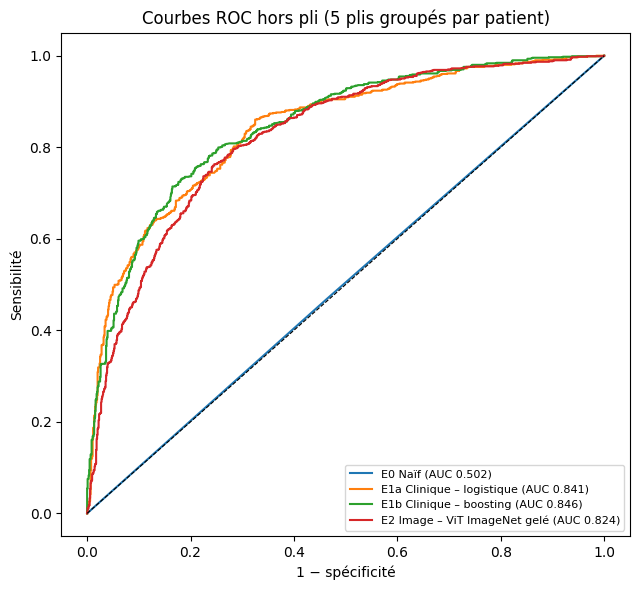

In [24]:
plt.figure(figsize=(6.5, 6))
for name, proba in oof_preds.items():
    fpr, tpr, _ = roc_curve(y_dev, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_dev, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("1 − spécificité")
plt.ylabel("Sensibilité")
plt.title("Courbes ROC hors pli (5 plis groupés par patient)")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_courbes_roc_baselines.png", dpi=150)
plt.show()

## 8. Sauvegarde des prédictions hors pli

In [25]:
oof = dev[["img_id", "patient_id", "diagnostic", "label", "fold"]].copy()
for name, proba in oof_preds.items():
    oof[name] = proba
oof.to_csv(PROCESSED_DIR / "oof_baselines.csv", index=False)
print("Enregistré :", PROCESSED_DIR / "oof_baselines.csv", oof.shape)

Enregistré : /kaggle/working/data/processed/oof_baselines.csv (1940, 9)


## Conclusion

- **E0 (plancher)** : AUC ≈ 0,50, comme attendu pour un modèle au hasard.
- **E1 (clinique seule)** : AUC ≈ 0,86 (logistique 0,863 ± 0,029 ; boosting 0,868 ± 0,030). Les symptômes, l'âge et la région portent déjà beaucoup d'information. Le boosting n'apporte presque rien face à la logistique : on garde la **logistique**, plus simple et directement interprétable.
- Variables les plus associées au cancer : `grew` (a grossi), `bleed` (saigne), région `NOSE`, `hurt`, `elevation`, `changed`, puis l'âge — cohérent avec la clinique.
- **E2 (image seule, ImageNet)** : *à compléter après exécution de la section 6.*
- Ces valeurs sont les références à battre par DermLIP (notebook 03) puis par le modèle multimodal (notebook 05). L'image devra prouver qu'elle apporte une information **en plus** de la clinique.
- Ces valeurs sont les références à battre par DermLIP (notebook 03) puis par le modèle multimodal (notebook 05).

**Étape suivante** : `03_dermlip.ipynb`.

---
# PARTIE 03 — DermLIP

# 03 — DermLIP : contrôle de chevauchement, zéro-exemple et sonde linéaire

**Question** : un encodeur préentraîné sur des images de peau (DermLIP, Derm1M) voit-il mieux les lésions qu'un encodeur générique (ImageNet) ?

| ID | Expérience | Entraînement sur PAD-UFES-20 |
|---|---|---|
| — | Contrôle de chevauchement Derm1M / PAD-UFES-20 | — |
| E4 | DermLIP **zéro-exemple** (comparaison image / phrases) | aucun |
| E3 | DermLIP gelé + régression logistique (**sonde linéaire**) | logistique seulement |
| E2* | ViT-B/16 ImageNet gelé + sonde linéaire, **même protocole** que E3 | logistique seulement |

**Protocole** : mêmes 5 plis groupés par patient que les notebooks 01–02 ; le coefficient de régularisation `C` des sondes est choisi **à l'intérieur** de chaque pli d'entraînement par une validation croisée groupée par patient (validation croisée imbriquée), pour E2* comme pour E3. La comparaison E3 / E2* est donc équitable : même architecture (ViT-B/16), même protocole, seul le préentraînement change.

> **Avant d'exécuter**
> 1. Installer la bibliothèque : `pip install open_clip_torch`
> 2. La section 2 **télécharge les poids DermLIP** depuis Hugging Face (`redlessone/DermLIP_ViT-B-16`, environ 600 Mo, licence CC BY-NC 4.0 : recherche non commerciale).
> 3. Pour le contrôle de chevauchement, placer les CSV de Derm1M dans `data/external/derm1m/` (voir section 1). Sans eux, le contrôle est marqué « non vérifié ».

## 0. Imports, données et fonctions communes

In [26]:
from pathlib import Path
import json
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_FOLDS = 5
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "zr7vgbcyr2-1" / "metadata.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
EXTERNAL_DIR = ROOT / "data" / "external" / "derm1m"
CONFIG_DIR = ROOT / "configs"
FIG_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
CKPT_DIR = ROOT / "outputs" / "checkpoints"
for d in (PROCESSED_DIR, FIG_DIR, REPORT_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# variables cliniques retenues (notebook 01) — le profil patient n'est utilisé que dans l'expérience E8
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS
PROFILE_NUM = ["fitspatrick", "diameter_1", "diameter_2"]
PROFILE_BOOL = ["smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history"]
PROFILE_CAT = ["gender"]
PROFILE_COLS = PROFILE_NUM + PROFILE_BOOL + PROFILE_CAT

CANCER_CLASSES = ["BCC", "SCC", "MEL"]
DERMLIP_ID = "hf-hub:redlessone/DermLIP_ViT-B-16"

In [27]:
splits = pd.read_csv(PROCESSED_DIR / "splits.csv")
meta = pd.read_csv(CSV_PATH, na_values=["UNK"])

df = splits.merge(meta[["img_id"] + FEATURES + PROFILE_COLS], on="img_id", how="left",
                  validate="one_to_one")
TO_FLOAT = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0}
for c in BOOL_COLS + PROFILE_BOOL:                     # True / False / NaN -> 1.0 / 0.0 / NaN
    df[c] = df[c].map(TO_FLOAT)

dev = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
y_dev, folds, groups_dev = dev["label"].to_numpy(), dev["fold"].to_numpy(), dev["patient_id"].to_numpy()
y_test, groups_test = test["label"].to_numpy(), test["patient_id"].to_numpy()

print(f"Développement : {len(dev)} images, {dev['patient_id'].nunique()} patients | "
      f"test : {len(test)} images (non utilisé avant l'évaluation finale)")
assert set(folds) == set(range(N_FOLDS))

Développement : 1940 images, 1176 patients | test : 358 images (non utilisé avant l'évaluation finale)


In [28]:
def metrics_at(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y_true, proba),
        "Exactitude équilibrée": balanced_accuracy_score(y_true, y_pred),
        "Sensibilité": recall_score(y_true, y_pred, pos_label=1),
        "Spécificité": recall_score(y_true, y_pred, pos_label=0),
        "F1": f1_score(y_true, y_pred),
    }


def take_rows(X, idx):
    return X.iloc[idx] if isinstance(X, pd.DataFrame) else X[idx]


def fit_model(model, X, y, groups=None):
    """Entraîne un modèle ; transmet `groups` aux modèles qui choisissent leurs hyperparamètres par patient."""
    needs_groups = isinstance(model, GridSearchCV) or getattr(model, "uses_groups", False)
    if needs_groups:
        assert groups is not None, "ce modèle a besoin des identifiants patients (groups)"
        return model.fit(X, y, groups=groups)
    return model.fit(X, y)


def cross_validate(make_model, X, y, folds, groups=None, return_models=False):
    """Validation croisée sur les 5 plis groupés par patient : métriques par pli + prédictions hors pli."""
    oof, rows, models = np.zeros(len(y)), [], []
    for k in range(N_FOLDS):
        tr, va = np.flatnonzero(folds != k), np.flatnonzero(folds == k)
        model = make_model()
        fit_model(model, take_rows(X, tr), y[tr], None if groups is None else groups[tr])
        oof[va] = model.predict_proba(take_rows(X, va))[:, 1]
        rows.append({"pli": k, **metrics_at(y[va], oof[va])})
        models.append(model)
    per_fold = pd.DataFrame(rows)
    return (per_fold, oof, models) if return_models else (per_fold, oof)


def summarize(name, per_fold):
    m = per_fold.drop(columns="pli")
    return {"Expérience": name, **{c: f"{m[c].mean():.3f} ± {m[c].std():.3f}" for c in m.columns},
            "AUC moyenne": m["AUC"].mean()}


def grouped_bootstrap(y, p, groups, p_ref=None, n_boot=2000, seed=SEED):
    """AUC et IC 95 % par bootstrap des patients ; avec `p_ref`, différence d'AUC appariée."""
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(inv == g) for g in range(len(uniq))]
    rng = np.random.default_rng(seed)
    aucs, diffs = [], []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].min() == y[idx].max():
            continue
        a = roc_auc_score(y[idx], p[idx])
        aucs.append(a)
        if p_ref is not None:
            diffs.append(a - roc_auc_score(y[idx], np.asarray(p_ref)[idx]))
    out = {"AUC": roc_auc_score(y, p), "IC95 bas": np.percentile(aucs, 2.5), "IC95 haut": np.percentile(aucs, 97.5)}
    if p_ref is not None:
        d = np.asarray(diffs)
        out.update({"ΔAUC": out["AUC"] - roc_auc_score(y, p_ref),
                    "ΔAUC IC95 bas": np.percentile(d, 2.5), "ΔAUC IC95 haut": np.percentile(d, 97.5),
                    "P(Δ ≤ 0)": float((d <= 0).mean())})
    return out


def make_clinical_preprocessor(num=NUM_COLS, bools=BOOL_COLS, cats=CAT_COLS):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("bool", SimpleImputer(strategy="most_frequent"), bools),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats),
    ])


C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]


def make_probe(c_grid=C_GRID):
    """Sonde linéaire : standardisation + logistique, C choisi par validation croisée groupée (patients)."""
    pipe = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
    return GridSearchCV(pipe, {"clf__C": c_grid}, cv=GroupKFold(n_splits=3), scoring="roc_auc", n_jobs=-1)


def load_features(name):
    """Charge un cache de caractéristiques et renvoie une fonction frame -> matrice alignée sur frame['img_id']."""
    feats = np.load(PROCESSED_DIR / f"features_{name}.npy")
    ids = pd.read_csv(PROCESSED_DIR / f"features_{name}_ids.csv")["img_id"]
    index = pd.Series(np.arange(len(ids)), index=ids.to_numpy())
    return lambda frame: feats[index.loc[frame["img_id"]].to_numpy()]


results, oof_preds = [], {}

## 1. Contrôle de chevauchement Derm1M / PAD-UFES-20

Derm1M contient des images issues de « datasets publics ». Si des images de PAD-UFES-20 ont servi au préentraînement de DermLIP, nos scores seraient optimistes. Deux contrôles :

1. **Texte et noms de fichiers** : recherche, dans tous les CSV de Derm1M, de mentions de PAD-UFES-20 et de noms au format PAD (`PAT_<patient>_<lésion>_<n>`).
2. **Hachage perceptuel** (optionnel, si les images de Derm1M sont téléchargées) : un « dHash » de 64 bits résume chaque image ; deux images presque identiques (même redimensionnées ou recompressées) ont des hachages proches (distance de Hamming ≤ 6).

Fichiers attendus dans `data/external/derm1m/` : `Derm1M_v2_pretrain.csv`, `Derm1M_v2_validation.csv` (et, pour le contrôle 2, les images dans `data/external/derm1m/images/`).

In [29]:
PAD_NAME = re.compile(r"PAT_\d+_\d+_\d+", re.IGNORECASE)
PAD_TEXT = re.compile(r"pad[-_ ]?ufes|ufes[-_ ]?20", re.IGNORECASE)
our_ids = {i.lower(): i for i in df["img_id"]}

overlap = {"statut": "non vérifié", "fichiers": [], "mentions_PAD_texte": 0, "noms_PAD_trouves": 0}
overlap_rows = []
csv_files = sorted(p for p in EXTERNAL_DIR.glob("*.csv") if "concept" not in p.name.lower())

if not csv_files:
    print("Aucun CSV Derm1M dans", EXTERNAL_DIR)
    print("→ Contrôle NON VÉRIFIÉ : à mentionner comme limite dans le rapport.")
else:
    found = set()
    for f in csv_files:
        n_rows = n_text = 0
        for chunk in pd.read_csv(f, chunksize=100_000, dtype=str, on_bad_lines="skip"):
            n_rows += len(chunk)
            text = chunk.fillna("").agg(" ".join, axis=1)
            n_text += int(text.str.contains(PAD_TEXT).sum())
            for name in text.str.findall(PAD_NAME).explode().dropna():
                found.add(name.lower() + ".png")
        overlap["fichiers"].append({"fichier": f.name, "lignes": n_rows, "mentions_PAD": n_text})
        overlap["mentions_PAD_texte"] += n_text
        print(f"{f.name} : {n_rows} lignes, {n_text} mentions de PAD-UFES-20")
    common = sorted(our_ids[n] for n in found if n in our_ids)
    overlap["noms_PAD_trouves"] = len(common)
    overlap_rows += [{"img_id": i, "methode": "nom de fichier", "distance": 0} for i in common]
    overlap["statut"] = "vérifié (texte et noms)"
    print("Images PAD-UFES-20 retrouvées par leur nom :", len(common))
    print("Colonnes du premier fichier :", list(pd.read_csv(csv_files[0], nrows=0).columns))

Aucun CSV Derm1M dans /kaggle/working/data/external/derm1m
→ Contrôle NON VÉRIFIÉ : à mentionner comme limite dans le rapport.


In [30]:
RUN_HASH_CHECK = False          # passer à True si les images de Derm1M sont dans data/external/derm1m/images/
DERM1M_IMG_DIR = EXTERNAL_DIR / "images"
MAX_DERM1M_IMAGES = 200_000     # limite de temps de calcul
HAMMING_MAX = 6
POPCOUNT = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)


def dhash(path, size=8):
    with Image.open(path) as im:
        g = np.asarray(im.convert("L").resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    return np.packbits((g[:, 1:] > g[:, :-1]).ravel()).view(">u8")[0].astype(np.uint64)


def nearest_hamming(a, b, chunk=2048):
    """Pour chaque hachage de `a`, distance de Hamming minimale vers `b` et indice correspondant."""
    best, arg = np.full(len(a), 65), np.full(len(a), -1)
    for s in range(0, len(b), chunk):
        x = np.bitwise_xor(a[:, None], b[None, s:s + chunk])
        d = POPCOUNT[x.view(np.uint8).reshape(len(a), -1, 8)].sum(axis=-1)
        j = d.argmin(axis=1)
        dj = d[np.arange(len(a)), j]
        better = dj < best
        best[better], arg[better] = dj[better], j[better] + s
    return best, arg


if RUN_HASH_CHECK and DERM1M_IMG_DIR.exists():
    derm_paths = [p for p in DERM1M_IMG_DIR.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    derm_paths = derm_paths[:MAX_DERM1M_IMAGES]
    t0 = time.time()
    pad_hash = np.array([dhash(ROOT / p) for p in df["img_path"]], dtype=np.uint64)
    derm_hash = np.array([dhash(p) for p in derm_paths], dtype=np.uint64)
    dist, arg = nearest_hamming(pad_hash, derm_hash)
    hits = np.flatnonzero(dist <= HAMMING_MAX)
    overlap_rows += [{"img_id": df["img_id"].iloc[i], "methode": "hachage perceptuel",
                      "distance": int(dist[i]), "image_derm1m": str(derm_paths[arg[i]])} for i in hits]
    overlap["hachage"] = {"images_derm1m_comparees": len(derm_paths), "doublons_probables": int(len(hits)),
                          "seuil_hamming": HAMMING_MAX, "duree_s": round(time.time() - t0)}
    print(overlap["hachage"])
else:
    overlap["hachage"] = "non exécuté"
    print("Contrôle par hachage non exécuté (RUN_HASH_CHECK = False ou images absentes).")

overlap_df = pd.DataFrame(overlap_rows, columns=["img_id", "methode", "distance"]).drop_duplicates("img_id")
overlap_df.to_csv(PROCESSED_DIR / "derm1m_overlap_ids.csv", index=False)
overlap["images_concernees"] = int(len(overlap_df))
overlap["dont_test"] = int(overlap_df["img_id"].isin(test["img_id"]).sum())
(REPORT_DIR / "03_controle_chevauchement.json").write_text(json.dumps(overlap, indent=2, ensure_ascii=False), encoding="utf8")
print(json.dumps(overlap, indent=2, ensure_ascii=False))

Contrôle par hachage non exécuté (RUN_HASH_CHECK = False ou images absentes).
{
  "statut": "non vérifié",
  "fichiers": [],
  "mentions_PAD_texte": 0,
  "noms_PAD_trouves": 0,
  "hachage": "non exécuté",
  "images_concernees": 0,
  "dont_test": 0
}


**Règle de décision** (fixée à l'avance) : les images retrouvées sont listées dans `data/processed/derm1m_overlap_ids.csv`. Le notebook 05 rapportera les résultats du test **avec et sans** ces images ; si elles sont nombreuses, les résultats DermLIP doivent être présentés comme potentiellement optimistes.

## 2. Chargement de DermLIP

> Cette cellule télécharge les poids au premier lancement (≈ 600 Mo, mis en cache par Hugging Face ensuite).

In [31]:
try:
    import open_clip
    import torch
except ImportError as e:
    raise ImportError("Installez open_clip :  pip install open_clip_torch") from e

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
model, _, preprocess = open_clip.create_model_and_transforms(DERMLIP_ID)
tokenizer = open_clip.get_tokenizer(DERMLIP_ID)
model = model.to(device).eval()
LOGIT_SCALE = float(model.logit_scale.exp().item())
print("DermLIP chargé sur", device, "| échelle des logits :", round(LOGIT_SCALE, 1))


@torch.no_grad()
def encode_texts(texts):
    emb = model.encode_text(tokenizer(texts).to(device)).float()
    return torch.nn.functional.normalize(emb, dim=-1).cpu().numpy()


def prompt_embedding(prompts):
    """Moyenne des plongements de plusieurs formulations, renormalisée (« ensemble de prompts »)."""
    e = encode_texts(prompts).mean(axis=0)
    return e / np.linalg.norm(e)


@torch.no_grad()
def encode_tensors(x):
    emb = model.encode_image(x.to(device)).float()
    return torch.nn.functional.normalize(emb, dim=-1).cpu().numpy()


def load_tensor(path):
    with Image.open(path) as im:
        return preprocess(im.convert("RGB"))

open_clip_config.json:   0%|          | 0.00/532 [00:00<?, ?B/s]

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  599MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

DermLIP chargé sur cuda | échelle des logits : 100.0


## 3. Extraction des plongements d'images (cache)

Chaque image est convertie en RGB, redimensionnée et recadrée à 224 × 224 par le prétraitement officiel de DermLIP, puis encodée en un vecteur de 512 valeurs normalisé (norme 1). Le résultat est mis en cache : l'extraction n'est faite qu'une fois.

In [32]:
FEAT_PATH = PROCESSED_DIR / "features_dermlip_vitb16.npy"
IDS_PATH = PROCESSED_DIR / "features_dermlip_vitb16_ids.csv"
BATCH = 64 if device == "cuda" else 32

if FEAT_PATH.exists() and IDS_PATH.exists():
    print("Cache trouvé :", np.load(FEAT_PATH).shape)
else:
    paths, feats, t0 = (ROOT / df["img_path"]).tolist(), [], time.time()
    for start in range(0, len(paths), BATCH):
        feats.append(encode_tensors(torch.stack([load_tensor(p) for p in paths[start:start + BATCH]])))
        if (start // BATCH) % 10 == 0:
            print(f"{min(start + BATCH, len(paths))}/{len(paths)} images — {time.time() - t0:.0f} s")
    np.save(FEAT_PATH, np.concatenate(feats).astype(np.float32))
    df[["img_id"]].to_csv(IDS_PATH, index=False)
    print("Plongements enregistrés en", round(time.time() - t0), "s")

take_dermlip = load_features("dermlip_vitb16")
X_dermlip_dev = take_dermlip(dev)
print("Matrice de développement :", X_dermlip_dev.shape,
      "| normes ≈ 1 :", np.allclose(np.linalg.norm(X_dermlip_dev, axis=1), 1, atol=1e-3))

64/2298 images — 5 s
704/2298 images — 39 s
1344/2298 images — 76 s
1984/2298 images — 111 s
Plongements enregistrés en 128 s
Matrice de développement : (1940, 512) | normes ≈ 1 : True


## 4. E4 — Zéro-exemple

Aucun entraînement : on compare chaque image à des phrases décrivant les 6 diagnostics. Chaque diagnostic est décrit par plusieurs formulations dont on moyenne les plongements (« ensemble de prompts »). La probabilité de cancer est la somme des probabilités de BCC, SCC et MEL.

In [33]:
CLASS_TEXT = {
    "BCC": "basal cell carcinoma",
    "SCC": "squamous cell carcinoma",
    "MEL": "melanoma",
    "ACK": "actinic keratosis",
    "NEV": "melanocytic nevus",
    "SEK": "seborrheic keratosis",
}
TEMPLATES = [
    "a clinical photo of {}.",
    "a close-up clinical photo of {} on the skin.",
    "a smartphone photo of a skin lesion: {}.",
    "{}.",
]
classes = list(CLASS_TEXT)
class_emb = np.stack([prompt_embedding([t.format(CLASS_TEXT[c]) for t in TEMPLATES]) for c in classes])


def zero_shot_proba(emb):
    logits = LOGIT_SCALE * emb @ class_emb.T
    logits -= logits.max(axis=1, keepdims=True)
    p = np.exp(logits)
    return p / p.sum(axis=1, keepdims=True)


P6 = zero_shot_proba(X_dermlip_dev)
p_zs = P6[:, [classes.index(c) for c in CANCER_CLASSES]].sum(axis=1)
oof_preds["E4 DermLIP zéro-exemple"] = p_zs

rows = [{"pli": k, **metrics_at(y_dev[folds == k], p_zs[folds == k])} for k in range(N_FOLDS)]
results.append(summarize("E4 DermLIP zéro-exemple", pd.DataFrame(rows)))

pred6 = np.array(classes)[P6.argmax(axis=1)]
print("Exactitude équilibrée (6 classes) :", round(balanced_accuracy_score(dev["diagnostic"], pred6), 3))
pd.crosstab(dev["diagnostic"], pred6, rownames=["vrai"], colnames=["prédit (zéro-exemple)"])

Exactitude équilibrée (6 classes) : 0.518


prédit (zéro-exemple),ACK,BCC,MEL,NEV,SCC,SEK
vrai,,,,,,
ACK,544,68,2,0,14,2
BCC,230,416,15,4,31,5
MEL,12,0,24,5,0,4
NEV,7,5,67,98,0,28
SCC,82,44,1,0,29,1
SEK,85,1,11,12,1,92


## 5. E3 et E2* — Sondes linéaires (validation croisée imbriquée)

Pour chaque pli : `C` est choisi parmi 6 valeurs par une validation croisée à 3 plis **groupée par patient** sur les seules données d'entraînement du pli, puis le modèle est évalué sur le pli de validation. E2* reprend les caractéristiques ImageNet du notebook 02 si elles existent.

In [34]:
experiments = {"E3 DermLIP sonde linéaire": X_dermlip_dev}
if (PROCESSED_DIR / "features_imagenet_vitb16.npy").exists():
    experiments["E2* ImageNet sonde linéaire"] = load_features("imagenet_vitb16")(dev)
else:
    print("Caractéristiques ImageNet absentes : exécutez la section 6 du notebook 02 pour obtenir E2*.")

best_c = {}
for name, X in experiments.items():
    t0 = time.time()
    per_fold, oof_preds[name], models = cross_validate(make_probe, X, y_dev, folds, groups=groups_dev,
                                                       return_models=True)
    results.append(summarize(name, per_fold))
    best_c[name] = [m.best_params_["clf__C"] for m in models]
    print(f"{name} — {time.time() - t0:.0f} s — C choisi par pli : {best_c[name]}")
    print(per_fold.round(3).to_string(index=False), "\n")

E3 DermLIP sonde linéaire — 6 s — C choisi par pli : [0.01, 0.01, 0.01, 0.01, 0.01]
 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.931                  0.875        0.881        0.868 0.869
   1 0.903                  0.808        0.801        0.815 0.784
   2 0.938                  0.875        0.859        0.891 0.870
   3 0.915                  0.815        0.889        0.741 0.822
   4 0.915                  0.847        0.835        0.858 0.831 

E2* ImageNet sonde linéaire — 5 s — C choisi par pli : [0.003, 0.01, 0.003, 0.003, 0.01]
 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.866                  0.788        0.746        0.829 0.771
   1 0.852                  0.772        0.776        0.768 0.746
   2 0.877                  0.785        0.770        0.801 0.778
   3 0.843                  0.752        0.758        0.746 0.748
   4 0.874                  0.799        0.812        0.785 0.781 



## 6. Référence clinique (E1a, identique au notebook 02)

In [35]:
def make_clinical_logreg():
    return Pipeline([("prep", make_clinical_preprocessor()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])


per_fold, oof_preds["E1a Clinique – logistique"] = cross_validate(make_clinical_logreg, dev[FEATURES], y_dev, folds)
results.append(summarize("E1a Clinique – logistique", per_fold))

## 7. Comparaison et tests statistiques

In [36]:
table = pd.DataFrame(results).set_index("Expérience").sort_values("AUC moyenne", ascending=False)
table.drop(columns="AUC moyenne").to_csv(REPORT_DIR / "03_dermlip_resultats.csv")
table.drop(columns="AUC moyenne")

,AUC,Exactitude équilibrée,Sensibilité,Spécificité,F1
Expérience,,,,,
E3 DermLIP sonde linéaire,0.920 ± 0.014,0.844 ± 0.032,0.853 ± 0.036,0.835 ± 0.059,0.835 ± 0.036
E2* ImageNet sonde linéaire,0.862 ± 0.015,0.779 ± 0.018,0.772 ± 0.025,0.786 ± 0.032,0.765 ± 0.017
E1a Clinique – logistique,0.842 ± 0.022,0.753 ± 0.023,0.723 ± 0.031,0.783 ± 0.025,0.733 ± 0.027
E4 DermLIP zéro-exemple,0.840 ± 0.023,0.754 ± 0.022,0.654 ± 0.054,0.855 ± 0.026,0.717 ± 0.030


In [37]:
comparisons = [("E3 DermLIP sonde linéaire", "E2* ImageNet sonde linéaire"),
               ("E3 DermLIP sonde linéaire", "E4 DermLIP zéro-exemple"),
               ("E3 DermLIP sonde linéaire", "E1a Clinique – logistique")]
rows = []
for a, b in comparisons:
    if a in oof_preds and b in oof_preds:
        r = grouped_bootstrap(y_dev, oof_preds[a], groups_dev, p_ref=oof_preds[b])
        rows.append({"comparaison": f"{a}  vs  {b}", **{k: round(v, 3) for k, v in r.items()}})
stats = pd.DataFrame(rows)
stats.to_csv(REPORT_DIR / "03_comparaisons_bootstrap.csv", index=False)
stats

,comparaison,AUC,IC95 bas,IC95 haut,ΔAUC,ΔAUC IC95 bas,ΔAUC IC95 haut,P(Δ ≤ 0)
0,E3 DermLIP sonde linéaire vs E2* ImageNet so...,0.919,0.905,0.933,0.058,0.044,0.072,0.0
1,E3 DermLIP sonde linéaire vs E4 DermLIP zéro...,0.919,0.905,0.933,0.081,0.064,0.097,0.0
2,E3 DermLIP sonde linéaire vs E1a Clinique – ...,0.919,0.905,0.933,0.079,0.059,0.101,0.0


*Lecture* : `ΔAUC` est la différence d'AUC (hors pli) entre les deux modèles ; l'intervalle `IC95` vient de 2 000 tirages bootstrap **des patients** (un patient et toutes ses images sont tirés ensemble). Si l'intervalle ne contient pas 0, la différence est considérée comme réelle.

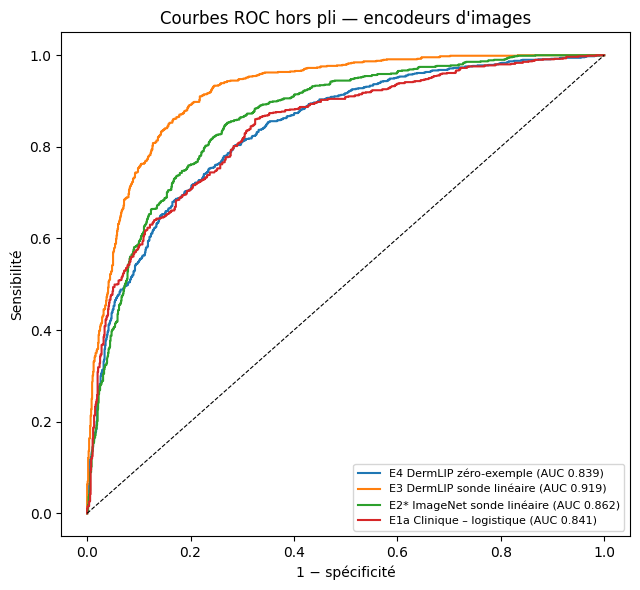

In [38]:
plt.figure(figsize=(6.5, 6))
for name, proba in oof_preds.items():
    fpr, tpr, _ = roc_curve(y_dev, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_dev, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("1 − spécificité")
plt.ylabel("Sensibilité")
plt.title("Courbes ROC hors pli — encodeurs d'images")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_courbes_roc_dermlip.png", dpi=150)
plt.show()

## 8. Sauvegarde

In [39]:
oof = dev[["img_id", "patient_id", "diagnostic", "label", "fold"]].copy()
for name, proba in oof_preds.items():
    oof[name] = proba
oof.to_csv(PROCESSED_DIR / "oof_dermlip.csv", index=False)
(REPORT_DIR / "03_C_choisis.json").write_text(json.dumps(best_c, indent=2, ensure_ascii=False), encoding="utf8")
print("Enregistré :", PROCESSED_DIR / "oof_dermlip.csv")

Enregistré : /kaggle/working/data/processed/oof_dermlip.csv


## Conclusion (à compléter après exécution)

Grille de lecture fixée à l'avance :

- **E3 vs E2*** : si l'IC 95 % de ΔAUC est entièrement > 0, le préentraînement dermatologique (Derm1M) apporte un gain réel → DermLIP est retenu comme encodeur d'images. Sinon, on le conserve pour les concepts (notebook 04) mais le gain de vision n'est pas démontré.
- **E4** : un zéro-exemple nettement au-dessus de 0,5 confirme que DermLIP « comprend » les diagnostics sans entraînement ; l'écart E3 − E4 mesure l'apport de l'apprentissage sur PAD-UFES-20.
- **E3 vs E1a** : indique si l'image seule rivalise avec les symptômes ; la fusion (notebook 05) doit faire mieux que les deux.
- **Chevauchement** : reporter le statut et le nombre d'images concernées (fichier `03_controle_chevauchement.json`).

**Étape suivante** : `04_concepts.ipynb`.

---
# PARTIE 04 — Concepts cliniques

# 04 — Concepts cliniques : construction, validation, sélection

**Objectif** : donner au modèle un vocabulaire **compréhensible par un médecin**. DermLIP place images et textes dans le même espace ; on mesure, pour chaque image, sa proximité avec des descriptions de concepts cliniques (ulcération, bords irréguliers, pigmentation…).

**Méthode**
1. Vocabulaire défini dans `configs/concepts.yaml` (≈ 20 concepts, 3 formulations chacun, inspirés de l'ontologie de Derm1M).
2. Score d'un concept = similarité image / concept − similarité image / phrase neutre (on retire ce qui est commun à toutes les photos de peau).
3. **Sélection sans utiliser le diagnostic** (pas de fuite) : on garde les concepts **stables** (les formulations donnent des scores concordants) et **non redondants**.
4. Contrôles de validité : cohérence avec les diagnostics attendus, lien avec les symptômes déclarés, concept « artefact » (encre) surveillé.
5. **E5** : classifieur sur les seuls concepts — le modèle le plus interprétable.

**Prérequis** : notebook 03 exécuté (cache `features_dermlip_vitb16.npy`). DermLIP est rechargé pour encoder les textes (pas de nouveau téléchargement si le cache Hugging Face existe).

## 0. Imports, données et fonctions communes

In [40]:
from pathlib import Path
import json
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_FOLDS = 5
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "zr7vgbcyr2-1" / "metadata.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
EXTERNAL_DIR = ROOT / "data" / "external" / "derm1m"
CONFIG_DIR = ROOT / "configs"
FIG_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
CKPT_DIR = ROOT / "outputs" / "checkpoints"
for d in (PROCESSED_DIR, FIG_DIR, REPORT_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# variables cliniques retenues (notebook 01) — le profil patient n'est utilisé que dans l'expérience E8
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS
PROFILE_NUM = ["fitspatrick", "diameter_1", "diameter_2"]
PROFILE_BOOL = ["smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history"]
PROFILE_CAT = ["gender"]
PROFILE_COLS = PROFILE_NUM + PROFILE_BOOL + PROFILE_CAT

CANCER_CLASSES = ["BCC", "SCC", "MEL"]
DERMLIP_ID = "hf-hub:redlessone/DermLIP_ViT-B-16"

In [41]:
splits = pd.read_csv(PROCESSED_DIR / "splits.csv")
meta = pd.read_csv(CSV_PATH, na_values=["UNK"])

df = splits.merge(meta[["img_id"] + FEATURES + PROFILE_COLS], on="img_id", how="left",
                  validate="one_to_one")
TO_FLOAT = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0}
for c in BOOL_COLS + PROFILE_BOOL:                     # True / False / NaN -> 1.0 / 0.0 / NaN
    df[c] = df[c].map(TO_FLOAT)

dev = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
y_dev, folds, groups_dev = dev["label"].to_numpy(), dev["fold"].to_numpy(), dev["patient_id"].to_numpy()
y_test, groups_test = test["label"].to_numpy(), test["patient_id"].to_numpy()

print(f"Développement : {len(dev)} images, {dev['patient_id'].nunique()} patients | "
      f"test : {len(test)} images (non utilisé avant l'évaluation finale)")
assert set(folds) == set(range(N_FOLDS))

Développement : 1940 images, 1176 patients | test : 358 images (non utilisé avant l'évaluation finale)


In [42]:
def metrics_at(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y_true, proba),
        "Exactitude équilibrée": balanced_accuracy_score(y_true, y_pred),
        "Sensibilité": recall_score(y_true, y_pred, pos_label=1),
        "Spécificité": recall_score(y_true, y_pred, pos_label=0),
        "F1": f1_score(y_true, y_pred),
    }


def take_rows(X, idx):
    return X.iloc[idx] if isinstance(X, pd.DataFrame) else X[idx]


def fit_model(model, X, y, groups=None):
    """Entraîne un modèle ; transmet `groups` aux modèles qui choisissent leurs hyperparamètres par patient."""
    needs_groups = isinstance(model, GridSearchCV) or getattr(model, "uses_groups", False)
    if needs_groups:
        assert groups is not None, "ce modèle a besoin des identifiants patients (groups)"
        return model.fit(X, y, groups=groups)
    return model.fit(X, y)


def cross_validate(make_model, X, y, folds, groups=None, return_models=False):
    """Validation croisée sur les 5 plis groupés par patient : métriques par pli + prédictions hors pli."""
    oof, rows, models = np.zeros(len(y)), [], []
    for k in range(N_FOLDS):
        tr, va = np.flatnonzero(folds != k), np.flatnonzero(folds == k)
        model = make_model()
        fit_model(model, take_rows(X, tr), y[tr], None if groups is None else groups[tr])
        oof[va] = model.predict_proba(take_rows(X, va))[:, 1]
        rows.append({"pli": k, **metrics_at(y[va], oof[va])})
        models.append(model)
    per_fold = pd.DataFrame(rows)
    return (per_fold, oof, models) if return_models else (per_fold, oof)


def summarize(name, per_fold):
    m = per_fold.drop(columns="pli")
    return {"Expérience": name, **{c: f"{m[c].mean():.3f} ± {m[c].std():.3f}" for c in m.columns},
            "AUC moyenne": m["AUC"].mean()}


def grouped_bootstrap(y, p, groups, p_ref=None, n_boot=2000, seed=SEED):
    """AUC et IC 95 % par bootstrap des patients ; avec `p_ref`, différence d'AUC appariée."""
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(inv == g) for g in range(len(uniq))]
    rng = np.random.default_rng(seed)
    aucs, diffs = [], []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].min() == y[idx].max():
            continue
        a = roc_auc_score(y[idx], p[idx])
        aucs.append(a)
        if p_ref is not None:
            diffs.append(a - roc_auc_score(y[idx], np.asarray(p_ref)[idx]))
    out = {"AUC": roc_auc_score(y, p), "IC95 bas": np.percentile(aucs, 2.5), "IC95 haut": np.percentile(aucs, 97.5)}
    if p_ref is not None:
        d = np.asarray(diffs)
        out.update({"ΔAUC": out["AUC"] - roc_auc_score(y, p_ref),
                    "ΔAUC IC95 bas": np.percentile(d, 2.5), "ΔAUC IC95 haut": np.percentile(d, 97.5),
                    "P(Δ ≤ 0)": float((d <= 0).mean())})
    return out


def make_clinical_preprocessor(num=NUM_COLS, bools=BOOL_COLS, cats=CAT_COLS):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("bool", SimpleImputer(strategy="most_frequent"), bools),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats),
    ])


C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]


def make_probe(c_grid=C_GRID):
    """Sonde linéaire : standardisation + logistique, C choisi par validation croisée groupée (patients)."""
    pipe = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
    return GridSearchCV(pipe, {"clf__C": c_grid}, cv=GroupKFold(n_splits=3), scoring="roc_auc", n_jobs=-1)


def load_features(name):
    """Charge un cache de caractéristiques et renvoie une fonction frame -> matrice alignée sur frame['img_id']."""
    feats = np.load(PROCESSED_DIR / f"features_{name}.npy")
    ids = pd.read_csv(PROCESSED_DIR / f"features_{name}_ids.csv")["img_id"]
    index = pd.Series(np.arange(len(ids)), index=ids.to_numpy())
    return lambda frame: feats[index.loc[frame["img_id"]].to_numpy()]


results, oof_preds = [], {}

## 1. Vocabulaire de concepts

In [43]:
import yaml

cfg = yaml.safe_load((CONFIG_DIR / "concepts.yaml").read_text(encoding="utf8"))
concepts = cfg["concepts"]
REF_PROMPTS = cfg["reference_prompts"]
vocab = pd.DataFrame([{
    "concept": c["name"], "libellé": c["label_fr"], "famille": c["group"],
    "attendu dans": ", ".join(c.get("expected") or []) or "—",
    "symptôme lié": c.get("related_symptom") or "—",
    "artefact": bool(c.get("artefact", False)), "formulations": len(c["prompts"]),
} for c in concepts])
assert vocab["concept"].is_unique, "noms de concepts dupliqués dans concepts.yaml"
vocab

,concept,libellé,famille,attendu dans,symptôme lié,artefact,formulations
0,pearly_translucent,aspect perlé ou translucide,surface,BCC,—,False,3
1,telangiectasia,petits vaisseaux visibles (télangiectasies),vaisseaux,BCC,—,False,3
2,ulceration,ulcération,surface,"BCC, SCC",bleed,False,3
3,crust,croûte,surface,"SCC, BCC",bleed,False,3
4,bleeding,saignement,surface,"BCC, SCC",bleed,False,3
5,scale,squames (surface rugueuse),surface,"ACK, SCC",—,False,3
6,hyperkeratosis,hyperkératose (corne cutanée),surface,SCC,—,False,3
7,erythema,rougeur (érythème),couleur,"ACK, SCC, BCC",—,False,3
8,nodule,nodule surélevé,forme,"BCC, SCC",elevation,False,3
9,flat_patch,tache plane,forme,"ACK, NEV",elevation,False,3


In [44]:
# Facultatif : aperçu des concepts annotés dans Derm1M (aide à aligner le vocabulaire)
concept_csv = EXTERNAL_DIR / "concept.csv"
if concept_csv.exists():
    peek = pd.read_csv(concept_csv, nrows=5)
    print("Colonnes de concept.csv :", list(peek.columns)[:60])
    display(peek.head())
else:
    print("concept.csv de Derm1M absent : le vocabulaire de configs/concepts.yaml est utilisé tel quel.")

concept.csv de Derm1M absent : le vocabulaire de configs/concepts.yaml est utilisé tel quel.


## 2. Chargement de DermLIP (encodeur de texte)

In [45]:
try:
    import open_clip
    import torch
except ImportError as e:
    raise ImportError("Installez open_clip :  pip install open_clip_torch") from e

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
model, _, preprocess = open_clip.create_model_and_transforms(DERMLIP_ID)
tokenizer = open_clip.get_tokenizer(DERMLIP_ID)
model = model.to(device).eval()
LOGIT_SCALE = float(model.logit_scale.exp().item())
print("DermLIP chargé sur", device, "| échelle des logits :", round(LOGIT_SCALE, 1))


@torch.no_grad()
def encode_texts(texts):
    emb = model.encode_text(tokenizer(texts).to(device)).float()
    return torch.nn.functional.normalize(emb, dim=-1).cpu().numpy()


def prompt_embedding(prompts):
    """Moyenne des plongements de plusieurs formulations, renormalisée (« ensemble de prompts »)."""
    e = encode_texts(prompts).mean(axis=0)
    return e / np.linalg.norm(e)


@torch.no_grad()
def encode_tensors(x):
    emb = model.encode_image(x.to(device)).float()
    return torch.nn.functional.normalize(emb, dim=-1).cpu().numpy()


def load_tensor(path):
    with Image.open(path) as im:
        return preprocess(im.convert("RGB"))

DermLIP chargé sur cuda | échelle des logits : 100.0


## 3. Plongements des concepts et scores des images

In [46]:
take_dermlip = load_features("dermlip_vitb16")
X_all = take_dermlip(df)                       # toutes les images (dev + test) : scores nécessaires au notebook 05
X_dev_img = take_dermlip(dev)

ref_emb = prompt_embedding(REF_PROMPTS)
prompt_embs = {c["name"]: encode_texts(c["prompts"]) for c in concepts}
concept_emb = np.stack([prompt_embedding(c["prompts"]) for c in concepts])
names = [c["name"] for c in concepts]

np.savez(PROCESSED_DIR / "concept_text_embeddings.npz", names=np.array(names),
         labels_fr=np.array([c["label_fr"] for c in concepts]), concept_emb=concept_emb, ref_emb=ref_emb)

scores_all = pd.DataFrame(X_all @ concept_emb.T - (X_all @ ref_emb)[:, None], columns=names)
scores_all.insert(0, "img_id", df["img_id"].to_numpy())
scores_dev = scores_all.set_index("img_id").loc[dev["img_id"]].reset_index(drop=True)
print("Scores calculés :", scores_all.shape)

Scores calculés : (2298, 20)


## 4. Sélection des concepts (sans utiliser le diagnostic)

- **Stabilité** : corrélation moyenne entre les scores des différentes formulations d'un même concept (sur les images de développement). Un concept instable dépend de la façon dont il est formulé : il est écarté (seuil fixé à l'avance : 0,5).
- **Redondance** : si deux concepts stables sont corrélés à plus de 0,9, on garde le plus stable.
- Les concepts **artefact** sont calculés mais jamais utilisés par le modèle.

In [47]:
STAB_MIN, REDUND_MAX, MIN_CONCEPTS = 0.5, 0.9, 6

stability = {}
for c in concepts:
    sims = X_dev_img @ prompt_embs[c["name"]].T - (X_dev_img @ ref_emb)[:, None]
    corr = np.corrcoef(sims.T)
    stability[c["name"]] = float(corr[np.triu_indices_from(corr, k=1)].mean())

table = vocab[["concept", "libellé", "famille", "artefact"]].copy()
table["stabilité"] = table["concept"].map(stability).round(3)
table["retenu"], table["raison"] = False, ""
table.loc[table["artefact"], "raison"] = "artefact : surveillance uniquement"

candidates = table[~table["artefact"]].sort_values("stabilité", ascending=False)
stable = candidates[candidates["stabilité"] >= STAB_MIN]["concept"].tolist()
if len(stable) < MIN_CONCEPTS:
    warnings.warn(f"Seulement {len(stable)} concepts stables : on garde les {MIN_CONCEPTS} plus stables.")
    stable = candidates["concept"].head(MIN_CONCEPTS).tolist()
table.loc[table["concept"].isin(candidates["concept"]) & ~table["concept"].isin(stable), "raison"] = \
    f"instable (< {STAB_MIN})"

corr_dev = scores_dev[stable].corr()
kept = []
for c in stable:
    twin = next((k for k in kept if abs(corr_dev.loc[c, k]) > REDUND_MAX), None)
    if twin:
        table.loc[table["concept"] == c, "raison"] = f"redondant avec {twin}"
    else:
        kept.append(c)
table.loc[table["concept"].isin(kept), ["retenu", "raison"]] = [True, "stable et non redondant"]
print("Concepts retenus :", len(kept), "/", (~table["artefact"]).sum())
table.sort_values(["retenu", "stabilité"], ascending=False)

Concepts retenus : 16 / 18


,concept,libellé,famille,artefact,stabilité,retenu,raison
2,ulceration,ulcération,surface,False,0.929,True,stable et non redondant
3,crust,croûte,surface,False,0.809,True,stable et non redondant
0,pearly_translucent,aspect perlé ou translucide,surface,False,0.806,True,stable et non redondant
1,telangiectasia,petits vaisseaux visibles (télangiectasies),vaisseaux,False,0.759,True,stable et non redondant
11,dark_pigmentation,pigmentation très foncée,couleur,False,0.743,True,stable et non redondant
8,nodule,nodule surélevé,forme,False,0.739,True,stable et non redondant
5,scale,squames (surface rugueuse),surface,False,0.736,True,stable et non redondant
4,bleeding,saignement,surface,False,0.733,True,stable et non redondant
17,sun_damage,peau abîmée par le soleil,contexte,False,0.698,True,stable et non redondant
7,erythema,rougeur (érythème),couleur,False,0.696,True,stable et non redondant


## 5. Contrôles de validité

Ces contrôles **décrivent** les concepts ; ils ne servent pas à les sélectionner (le diagnostic n'est pas utilisé pour choisir).

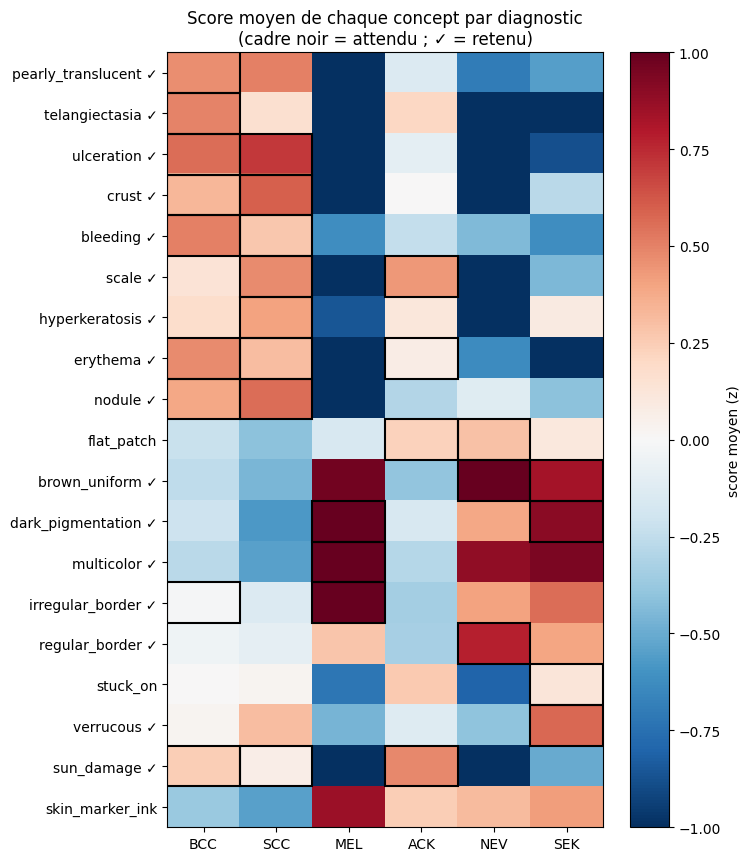

Concepts cohérents avec les diagnostics attendus : 18 / 18


In [48]:
z_dev = (scores_dev - scores_dev.mean()) / scores_dev.std()
by_diag = z_dev.groupby(dev["diagnostic"].to_numpy()).mean().T
order = ["BCC", "SCC", "MEL", "ACK", "NEV", "SEK"]
by_diag = by_diag[order]

fig, ax = plt.subplots(figsize=(7.5, 0.38 * len(by_diag) + 1.5))
im = ax.imshow(by_diag.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(len(order)), order)
ax.set_yticks(range(len(by_diag)), [f"{n}{' ✓' if n in kept else ''}" for n in by_diag.index])
for i, c in enumerate(concepts):
    for diag in c.get("expected") or []:
        ax.add_patch(plt.Rectangle((order.index(diag) - 0.5, i - 0.5), 1, 1, fill=False, lw=1.5, ec="black"))
plt.colorbar(im, label="score moyen (z)")
ax.set_title("Score moyen de chaque concept par diagnostic\n(cadre noir = attendu ; ✓ = retenu)")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_concepts_par_diagnostic.png", dpi=150)
plt.show()

expected_ok = {}
for c in concepts:
    exp = c.get("expected") or []
    if exp:
        expected_ok[c["name"]] = bool(by_diag.loc[c["name"], exp].mean() > by_diag.loc[c["name"]].drop(exp).mean())
table["cohérent avec l'attendu"] = table["concept"].map(expected_ok)
print("Concepts cohérents avec les diagnostics attendus :", sum(expected_ok.values()), "/", len(expected_ok))

In [49]:
rows = []
for c in concepts:
    s = c.get("related_symptom")
    if s:
        mask = dev[s].notna().to_numpy()
        rows.append({"concept": c["name"], "symptôme": s,
                     "AUC (score → symptôme)": round(roc_auc_score(dev.loc[mask, s], scores_dev.loc[mask, c["name"]]), 3)})
symptom_check = pd.DataFrame(rows)
table["AUC symptôme"] = table["concept"].map(symptom_check.set_index("concept")["AUC (score → symptôme)"])
symptom_check

,concept,symptôme,AUC (score → symptôme)
0,ulceration,bleed,0.796
1,crust,bleed,0.728
2,bleeding,bleed,0.742
3,nodule,elevation,0.764
4,flat_patch,elevation,0.415
5,multicolor,changed,0.547
6,irregular_border,changed,0.581


*Lecture* : une AUC > 0,5 signifie que le concept est plus élevé quand le patient déclare le symptôme (ex. « ulcération » ↔ saignement). Pour `flat_patch` (tache plane), une AUC **< 0,5** est attendue face à `elevation` : c'est aussi un signe de validité.

In [50]:
artefacts = table.loc[table["artefact"], "concept"].tolist()
for a in artefacts:
    auc_a = roc_auc_score(y_dev, scores_dev[a])
    print(f"Concept artefact « {a} » : AUC pour prédire le cancer = {auc_a:.3f}")
    if abs(auc_a - 0.5) > 0.1:
        print("  ⚠ Lien marqué avec le diagnostic : risque de raccourci (encre). À vérifier dans le notebook 06.")

Concept artefact « skin_marker_ink » : AUC pour prédire le cancer = 0.311
  ⚠ Lien marqué avec le diagnostic : risque de raccourci (encre). À vérifier dans le notebook 06.


## 6. E5 — Classifieur sur les seuls concepts (validation croisée imbriquée)

 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.835                  0.756        0.751        0.761 0.745
   1 0.867                  0.799        0.820        0.777 0.776
   2 0.871                  0.786        0.796        0.776 0.784
   3 0.822                  0.741        0.795        0.687 0.748
   4 0.828                  0.779        0.750        0.808 0.754


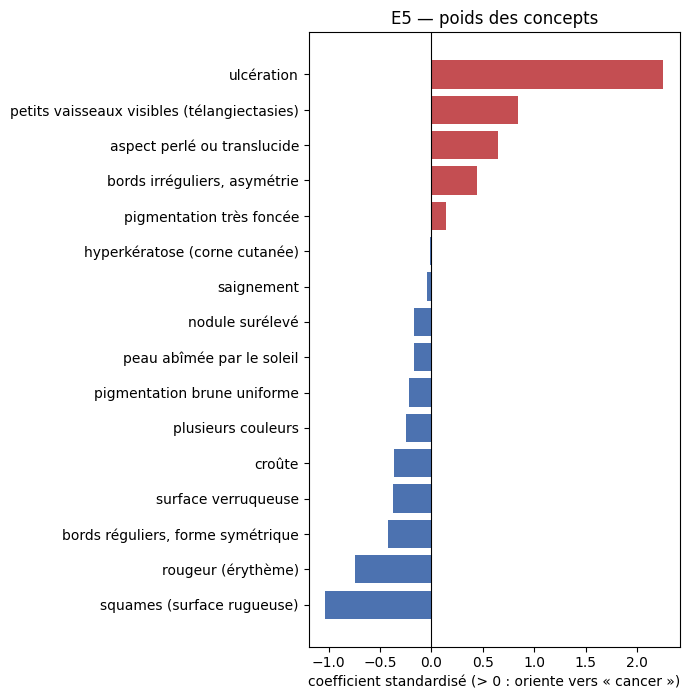

In [51]:
X_cpt_dev = scores_dev[kept]
per_fold, oof_preds["E5 Concepts seuls"] = cross_validate(make_probe, X_cpt_dev, y_dev, folds, groups=groups_dev)
results.append(summarize("E5 Concepts seuls", per_fold))
print(per_fold.round(3).to_string(index=False))

final = fit_model(make_probe(), X_cpt_dev, y_dev, groups_dev).best_estimator_
coef = pd.Series(final.named_steps["clf"].coef_[0], index=kept).sort_values()
labels = table.set_index("concept")["libellé"]
plt.figure(figsize=(7, 0.35 * len(coef) + 1.5))
plt.barh([labels[c] for c in coef.index], coef, color=np.where(coef > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("coefficient standardisé (> 0 : oriente vers « cancer »)")
plt.title("E5 — poids des concepts")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_poids_concepts.png", dpi=150)
plt.show()

In [52]:
ref_path = PROCESSED_DIR / "oof_dermlip.csv"
if ref_path.exists():
    ref = pd.read_csv(ref_path).set_index("img_id").loc[dev["img_id"]]
    rows = []
    for other in ["E3 DermLIP sonde linéaire", "E1a Clinique – logistique"]:
        if other in ref:
            r = grouped_bootstrap(y_dev, oof_preds["E5 Concepts seuls"], groups_dev, p_ref=ref[other].to_numpy())
            rows.append({"comparaison": f"E5 vs {other}", **{k: round(v, 3) for k, v in r.items()}})
    display(pd.DataFrame(rows))
pd.DataFrame(results).set_index("Expérience").drop(columns="AUC moyenne")

,comparaison,AUC,IC95 bas,IC95 haut,ΔAUC,ΔAUC IC95 bas,ΔAUC IC95 haut,P(Δ ≤ 0)
0,E5 vs E3 DermLIP sonde linéaire,0.844,0.824,0.863,-0.075,-0.09,-0.061,1.000
1,E5 vs E1a Clinique – logistique,0.844,0.824,0.863,0.004,-0.02,0.027,0.373


,AUC,Exactitude équilibrée,Sensibilité,Spécificité,F1
Expérience,,,,,
E5 Concepts seuls,0.845 ± 0.023,0.772 ± 0.023,0.782 ± 0.031,0.762 ± 0.045,0.761 ± 0.017


## 7. Sauvegarde

In [53]:
scores_all.to_csv(PROCESSED_DIR / "concept_scores.csv", index=False)
prompts = {c["name"]: " | ".join(c["prompts"]) for c in concepts}
table["formulations"] = table["concept"].map(prompts)
table.to_csv(PROCESSED_DIR / "concepts_selected.csv", index=False)
pd.DataFrame(results).set_index("Expérience").drop(columns="AUC moyenne").to_csv(REPORT_DIR / "04_concepts_resultats.csv")
oof = dev[["img_id", "patient_id", "diagnostic", "label", "fold"]].assign(**{"E5 Concepts seuls": oof_preds["E5 Concepts seuls"]})
oof.to_csv(PROCESSED_DIR / "oof_concepts.csv", index=False)
print("Enregistrés : concept_scores.csv, concepts_selected.csv, concept_text_embeddings.npz, oof_concepts.csv")

Enregistrés : concept_scores.csv, concepts_selected.csv, concept_text_embeddings.npz, oof_concepts.csv


## Conclusion (à compléter après exécution)

- Nombre de concepts retenus et raisons des exclusions (tableau de la section 4).
- Validité : part des concepts cohérents avec les diagnostics attendus ; liens concept ↔ symptôme.
- **E5** : performance d'un modèle qui ne « voit » l'image qu'à travers des concepts nommés. Si E5 est proche de E3, les concepts résument bien l'image ; s'il est nettement plus bas, ils servent surtout à **expliquer** (notebook 06) plutôt qu'à prédire.
- Artefact : AUC du concept « marque de stylo » — un lien fort avec le cancer confirme le risque de raccourci.

**Étape suivante** : `05_fusion.ipynb`.

---
# PARTIE 05 — Fusion multimodale et évaluation finale

# 05 — Fusion multimodale et évaluation finale

**Objectif** : combiner clinique, image (DermLIP) et concepts, choisir **un** modèle par une règle fixée à l'avance, puis l'évaluer **une seule fois** sur l'ensemble de test.

| ID | Modèle | Entrées |
|---|---|---|
| E1a | Logistique | clinique |
| E3 | Logistique | image (plongement DermLIP, réduit par ACP) |
| E5 | Logistique | concepts |
| E6a | Fusion **précoce** (logistique) | image + clinique |
| E6b | Fusion **tardive** (stacking) | image + clinique |
| E7a | Fusion précoce | image + concepts + clinique |
| E7c | Fusion précoce, **sans plongement brut** | concepts + clinique (100 % nommé) |
| E7b | Fusion **à porte** (petit réseau) | image + concepts + clinique |
| E8 | Expérience secondaire : profil patient complet | sous-ensemble de 1 494 lignes |
| E9 | Optionnel (GPU) : ajustement fin de DermLIP | image + clinique |

**Protocole** : mêmes 5 plis groupés par patient ; tous les hyperparamètres (C, dimension de l'ACP) choisis à l'intérieur des plis (validation croisée imbriquée, groupée par patient).

**Règle de choix (fixée avant de voir les résultats)** : parmi les modèles de fusion, on prend la meilleure AUC moyenne ; si un modèle **plus simple** est à moins de 0,005 d'AUC, on prend le plus simple. Ordre de simplicité : E7c < E6a < E7a < E6b < E7b.

**Prérequis** : notebooks 03 et 04 exécutés (caches DermLIP et concepts). Aucun téléchargement dans ce notebook, sauf la section optionnelle E9.

## 0. Imports, données, fonctions et modèles communs

In [54]:
from pathlib import Path
import json
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_FOLDS = 5
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "zr7vgbcyr2-1" / "metadata.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
EXTERNAL_DIR = ROOT / "data" / "external" / "derm1m"
CONFIG_DIR = ROOT / "configs"
FIG_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
CKPT_DIR = ROOT / "outputs" / "checkpoints"
for d in (PROCESSED_DIR, FIG_DIR, REPORT_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# variables cliniques retenues (notebook 01) — le profil patient n'est utilisé que dans l'expérience E8
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS
PROFILE_NUM = ["fitspatrick", "diameter_1", "diameter_2"]
PROFILE_BOOL = ["smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history"]
PROFILE_CAT = ["gender"]
PROFILE_COLS = PROFILE_NUM + PROFILE_BOOL + PROFILE_CAT

CANCER_CLASSES = ["BCC", "SCC", "MEL"]
DERMLIP_ID = "hf-hub:redlessone/DermLIP_ViT-B-16"

In [55]:
splits = pd.read_csv(PROCESSED_DIR / "splits.csv")
meta = pd.read_csv(CSV_PATH, na_values=["UNK"])

df = splits.merge(meta[["img_id"] + FEATURES + PROFILE_COLS], on="img_id", how="left",
                  validate="one_to_one")
TO_FLOAT = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0}
for c in BOOL_COLS + PROFILE_BOOL:                     # True / False / NaN -> 1.0 / 0.0 / NaN
    df[c] = df[c].map(TO_FLOAT)

dev = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
y_dev, folds, groups_dev = dev["label"].to_numpy(), dev["fold"].to_numpy(), dev["patient_id"].to_numpy()
y_test, groups_test = test["label"].to_numpy(), test["patient_id"].to_numpy()

print(f"Développement : {len(dev)} images, {dev['patient_id'].nunique()} patients | "
      f"test : {len(test)} images (non utilisé avant l'évaluation finale)")
assert set(folds) == set(range(N_FOLDS))

Développement : 1940 images, 1176 patients | test : 358 images (non utilisé avant l'évaluation finale)


In [56]:
def metrics_at(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y_true, proba),
        "Exactitude équilibrée": balanced_accuracy_score(y_true, y_pred),
        "Sensibilité": recall_score(y_true, y_pred, pos_label=1),
        "Spécificité": recall_score(y_true, y_pred, pos_label=0),
        "F1": f1_score(y_true, y_pred),
    }


def take_rows(X, idx):
    return X.iloc[idx] if isinstance(X, pd.DataFrame) else X[idx]


def fit_model(model, X, y, groups=None):
    """Entraîne un modèle ; transmet `groups` aux modèles qui choisissent leurs hyperparamètres par patient."""
    needs_groups = isinstance(model, GridSearchCV) or getattr(model, "uses_groups", False)
    if needs_groups:
        assert groups is not None, "ce modèle a besoin des identifiants patients (groups)"
        return model.fit(X, y, groups=groups)
    return model.fit(X, y)


def cross_validate(make_model, X, y, folds, groups=None, return_models=False):
    """Validation croisée sur les 5 plis groupés par patient : métriques par pli + prédictions hors pli."""
    oof, rows, models = np.zeros(len(y)), [], []
    for k in range(N_FOLDS):
        tr, va = np.flatnonzero(folds != k), np.flatnonzero(folds == k)
        model = make_model()
        fit_model(model, take_rows(X, tr), y[tr], None if groups is None else groups[tr])
        oof[va] = model.predict_proba(take_rows(X, va))[:, 1]
        rows.append({"pli": k, **metrics_at(y[va], oof[va])})
        models.append(model)
    per_fold = pd.DataFrame(rows)
    return (per_fold, oof, models) if return_models else (per_fold, oof)


def summarize(name, per_fold):
    m = per_fold.drop(columns="pli")
    return {"Expérience": name, **{c: f"{m[c].mean():.3f} ± {m[c].std():.3f}" for c in m.columns},
            "AUC moyenne": m["AUC"].mean()}


def grouped_bootstrap(y, p, groups, p_ref=None, n_boot=2000, seed=SEED):
    """AUC et IC 95 % par bootstrap des patients ; avec `p_ref`, différence d'AUC appariée."""
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(inv == g) for g in range(len(uniq))]
    rng = np.random.default_rng(seed)
    aucs, diffs = [], []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].min() == y[idx].max():
            continue
        a = roc_auc_score(y[idx], p[idx])
        aucs.append(a)
        if p_ref is not None:
            diffs.append(a - roc_auc_score(y[idx], np.asarray(p_ref)[idx]))
    out = {"AUC": roc_auc_score(y, p), "IC95 bas": np.percentile(aucs, 2.5), "IC95 haut": np.percentile(aucs, 97.5)}
    if p_ref is not None:
        d = np.asarray(diffs)
        out.update({"ΔAUC": out["AUC"] - roc_auc_score(y, p_ref),
                    "ΔAUC IC95 bas": np.percentile(d, 2.5), "ΔAUC IC95 haut": np.percentile(d, 97.5),
                    "P(Δ ≤ 0)": float((d <= 0).mean())})
    return out


def make_clinical_preprocessor(num=NUM_COLS, bools=BOOL_COLS, cats=CAT_COLS):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("bool", SimpleImputer(strategy="most_frequent"), bools),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats),
    ])


C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]


def make_probe(c_grid=C_GRID):
    """Sonde linéaire : standardisation + logistique, C choisi par validation croisée groupée (patients)."""
    pipe = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
    return GridSearchCV(pipe, {"clf__C": c_grid}, cv=GroupKFold(n_splits=3), scoring="roc_auc", n_jobs=-1)


def load_features(name):
    """Charge un cache de caractéristiques et renvoie une fonction frame -> matrice alignée sur frame['img_id']."""
    feats = np.load(PROCESSED_DIR / f"features_{name}.npy")
    ids = pd.read_csv(PROCESSED_DIR / f"features_{name}_ids.csv")["img_id"]
    index = pd.Series(np.arange(len(ids)), index=ids.to_numpy())
    return lambda frame: feats[index.loc[frame["img_id"]].to_numpy()]


results, oof_preds = [], {}

In [57]:
from functools import partial

import joblib
import torch
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit


def make_linear_fusion(clin=True, img=False, cpt=False, profile=False):
    """Fusion précoce : blocs (clinique / image / concepts) prétraités puis une régression logistique.
    C (et la réduction PCA de l'image) sont choisis par validation croisée groupée par patient."""
    blocks = []
    if clin:
        num, bools, cats = ((NUM_COLS + PROFILE_NUM, BOOL_COLS + PROFILE_BOOL, CAT_COLS + PROFILE_CAT)
                            if profile else (NUM_COLS, BOOL_COLS, CAT_COLS))
        blocks.append(("clin", make_clinical_preprocessor(num, bools, cats), num + bools + cats))
    if img:
        blocks.append(("img", Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=SEED))]), IMG_COLS))
    if cpt:
        blocks.append(("cpt", StandardScaler(), CONCEPT_COLS))
    pipe = Pipeline([("prep", ColumnTransformer(blocks)), ("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
    grid = {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}
    if img:
        grid["prep__img__pca__n_components"] = [16, 64, 128]
    return GridSearchCV(pipe, grid, cv=GroupKFold(n_splits=3), scoring="roc_auc", n_jobs=-1)


def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


class LateFusion(BaseEstimator, ClassifierMixin):
    """Fusion tardive (stacking) : un modèle par modalité, combinés par une logistique apprise
    sur leurs prédictions hors pli internes (groupées par patient)."""
    uses_groups = True

    def __init__(self, base_factories=(), n_inner=3):
        self.base_factories = base_factories
        self.n_inner = n_inner

    def fit(self, X, y, groups):
        y, groups = np.asarray(y), np.asarray(groups)
        Z = np.zeros((len(y), len(self.base_factories)))
        for tr, va in GroupKFold(n_splits=self.n_inner).split(X, y, groups):
            for j, (_, factory) in enumerate(self.base_factories):
                m = fit_model(factory(), take_rows(X, tr), y[tr], groups[tr])
                Z[va, j] = _logit(m.predict_proba(take_rows(X, va))[:, 1])
        self.meta_ = LogisticRegression(class_weight="balanced").fit(Z, y)
        self.bases_ = [fit_model(f(), X, y, groups) for _, f in self.base_factories]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        Z = np.column_stack([_logit(m.predict_proba(X)[:, 1]) for m in self.bases_])
        return self.meta_.predict_proba(Z)


class _GatedNet(torch.nn.Module):
    def __init__(self, dims, hidden, dropout):
        super().__init__()
        self.encoders = torch.nn.ModuleList([
            torch.nn.Sequential(torch.nn.Linear(d, hidden), torch.nn.GELU(), torch.nn.Dropout(dropout)) for d in dims])
        self.gate = torch.nn.Linear(hidden * len(dims), len(dims))
        self.head = torch.nn.Sequential(torch.nn.LayerNorm(hidden), torch.nn.Linear(hidden, 1))

    def forward(self, xs):
        hs = [enc(x) for enc, x in zip(self.encoders, xs)]
        w = torch.softmax(self.gate(torch.cat(hs, dim=1)), dim=1)        # poids de chaque modalité
        fused = sum(w[:, i:i + 1] * h for i, h in enumerate(hs))
        return self.head(fused).squeeze(1), w


class GatedFusion(BaseEstimator, ClassifierMixin):
    """Fusion à porte : un petit réseau par modalité, une porte apprend le poids de chaque modalité
    pour chaque patient. Arrêt anticipé sur 15 % des patients du pli ; moyenne de plusieurs graines."""
    uses_groups = True
    MODALITIES = ("clinique", "image", "concepts")

    def __init__(self, hidden=32, dropout=0.3, lr=1e-3, weight_decay=1e-2, max_epochs=400,
                 patience=30, n_seeds=5, val_size=0.15, img_pca=64):
        self.hidden, self.dropout, self.lr, self.weight_decay = hidden, dropout, lr, weight_decay
        self.max_epochs, self.patience, self.n_seeds = max_epochs, patience, n_seeds
        self.val_size, self.img_pca = val_size, img_pca

    def _blocks(self):
        return [("clin", make_clinical_preprocessor(), FEATURES),
                ("img", Pipeline([("scale", StandardScaler()),
                                  ("pca", PCA(n_components=self.img_pca, random_state=SEED))]), IMG_COLS),
                ("cpt", StandardScaler(), CONCEPT_COLS)]

    def _transform(self, X):
        return [torch.tensor(np.asarray(p.transform(X[cols]), dtype=np.float32))
                for (_, _, cols), p in zip(self._blocks(), self.preps_)]

    def fit(self, X, y, groups):
        y = np.asarray(y, dtype=np.float32)
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=self.val_size, random_state=SEED)
                      .split(X, y, groups))
        Xtr, Xva = take_rows(X, tr), take_rows(X, va)
        self.preps_ = [p.fit(Xtr[cols]) for _, p, cols in self._blocks()]
        xtr, xva = self._transform(Xtr), self._transform(Xva)
        ytr, yva = torch.tensor(y[tr]), torch.tensor(y[va])
        loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - y[tr]).sum() / max(y[tr].sum(), 1.0)))
        self.nets_ = []
        for s in range(self.n_seeds):
            torch.manual_seed(SEED + s)
            net = _GatedNet([x.shape[1] for x in xtr], self.hidden, self.dropout)
            opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
            best, best_state, wait = np.inf, None, 0
            for _ in range(self.max_epochs):
                net.train()
                opt.zero_grad()
                loss_fn(net(xtr)[0], ytr).backward()
                opt.step()
                net.eval()
                with torch.no_grad():
                    v = loss_fn(net(xva)[0], yva).item()
                if v < best - 1e-4:
                    best, wait = v, 0
                    best_state = {k: t.detach().clone() for k, t in net.state_dict().items()}
                else:
                    wait += 1
                    if wait >= self.patience:
                        break
            net.load_state_dict(best_state)
            net.eval()
            self.nets_.append(net)
        self.classes_ = np.array([0, 1])
        return self

    def _forward(self, X):
        xs = self._transform(X)
        with torch.no_grad():
            outs = [net(xs) for net in self.nets_]
        p = np.mean([torch.sigmoid(o[0]).numpy() for o in outs], axis=0)
        w = np.mean([o[1].numpy() for o in outs], axis=0)
        return p, w

    def predict_proba(self, X):
        p, _ = self._forward(X)
        return np.column_stack([1 - p, p])

    def modality_weights(self, X):
        return pd.DataFrame(self._forward(X)[1], columns=list(self.MODALITIES))


def expected_calibration_error(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    idx = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    rows, ece = [], 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
            rows.append({"confiance moyenne": p[m].mean(), "fréquence observée": y[m].mean(), "n": int(m.sum())})
    return ece, pd.DataFrame(rows)

In [58]:
take_img = load_features("dermlip_vitb16")
emb_bank = np.load(PROCESSED_DIR / "concept_text_embeddings.npz", allow_pickle=True)
selected = pd.read_csv(PROCESSED_DIR / "concepts_selected.csv")
CONCEPT_NAMES = selected.loc[selected["retenu"], "concept"].tolist()
_name_to_row = {n: i for i, n in enumerate(emb_bank["names"])}
CPT_EMB = emb_bank["concept_emb"][[_name_to_row[n] for n in CONCEPT_NAMES]]
REF_EMB = emb_bank["ref_emb"]

N_IMG = take_img(dev.head(1)).shape[1]
IMG_COLS = [f"img_{i}" for i in range(N_IMG)]
CONCEPT_COLS = [f"c_{n}" for n in CONCEPT_NAMES]


def concept_scores(emb):
    """Score de concept = similarité image/concept moins similarité image/référence neutre."""
    return emb @ CPT_EMB.T - (emb @ REF_EMB)[:, None]


def build_frame(frame, emb=None):
    """Table complète : variables cliniques + plongement image DermLIP + scores de concepts."""
    emb = take_img(frame) if emb is None else emb
    clin = frame[FEATURES + PROFILE_COLS].reset_index(drop=True)
    img = pd.DataFrame(emb, columns=IMG_COLS)
    cpt = pd.DataFrame(concept_scores(emb), columns=CONCEPT_COLS)
    return pd.concat([clin, img, cpt], axis=1)


print("Concepts retenus :", len(CONCEPT_NAMES), "| dimension image :", N_IMG)

Concepts retenus : 16 | dimension image : 512


## 1. Tables d'entrée

In [59]:
X_dev = build_frame(dev)
X_test = build_frame(test)
print("Développement :", X_dev.shape, "| test :", X_test.shape)

overlap_path = PROCESSED_DIR / "derm1m_overlap_ids.csv"
overlap_ids = set(pd.read_csv(overlap_path)["img_id"]) if overlap_path.exists() else set()
print("Images signalées par le contrôle de chevauchement Derm1M :", len(overlap_ids))

Développement : (1940, 545) | test : (358, 545)
Images signalées par le contrôle de chevauchement Derm1M : 0


## 2. Validation croisée de tous les modèles

In [60]:
EXPERIMENTS = {
    "E1a Clinique": lambda: make_linear_fusion(clin=True),
    "E3 Image DermLIP": lambda: make_linear_fusion(clin=False, img=True),
    "E5 Concepts": lambda: make_linear_fusion(clin=False, cpt=True),
    "E6a Précoce image+clinique": lambda: make_linear_fusion(clin=True, img=True),
    "E6b Tardive image+clinique": lambda: LateFusion((          # partial (et non lambda) : modèle enregistrable
        ("clinique", partial(make_linear_fusion, clin=True)),
        ("image", partial(make_linear_fusion, clin=False, img=True)))),
    "E7a Précoce image+concepts+clinique": lambda: make_linear_fusion(clin=True, img=True, cpt=True),
    "E7c Concepts+clinique": lambda: make_linear_fusion(clin=True, cpt=True),
    "E7b À porte (réseau)": lambda: GatedFusion(),
}
SIMPLICITY = ["E7c Concepts+clinique", "E6a Précoce image+clinique", "E7a Précoce image+concepts+clinique",
              "E6b Tardive image+clinique", "E7b À porte (réseau)"]

per_fold_all = {}
for name, factory in EXPERIMENTS.items():
    t0 = time.time()
    per_fold, oof_preds[name] = cross_validate(factory, X_dev, y_dev, folds, groups=groups_dev)
    per_fold_all[name] = per_fold
    results.append(summarize(name, per_fold))
    print(f"{name:42s} AUC {per_fold['AUC'].mean():.3f} ± {per_fold['AUC'].std():.3f}   ({time.time() - t0:.0f} s)")

E1a Clinique                               AUC 0.841 ± 0.022   (2 s)
E3 Image DermLIP                           AUC 0.914 ± 0.014   (10 s)
E5 Concepts                                AUC 0.845 ± 0.023   (2 s)
E6a Précoce image+clinique                 AUC 0.927 ± 0.013   (13 s)
E6b Tardive image+clinique                 AUC 0.931 ± 0.008   (47 s)
E7a Précoce image+concepts+clinique        AUC 0.930 ± 0.013   (14 s)
E7c Concepts+clinique                      AUC 0.895 ± 0.006   (3 s)
E7b À porte (réseau)                       AUC 0.936 ± 0.013   (26 s)


In [61]:
table = pd.DataFrame(results).set_index("Expérience")
auc_mean = table["AUC moyenne"]
table.drop(columns="AUC moyenne").to_csv(REPORT_DIR / "05_validation_croisee.csv")
table.drop(columns="AUC moyenne").sort_values("AUC", ascending=False)

,AUC,Exactitude équilibrée,Sensibilité,Spécificité,F1
Expérience,,,,,
E7b À porte (réseau),0.936 ± 0.013,0.870 ± 0.016,0.877 ± 0.030,0.863 ± 0.035,0.862 ± 0.022
E6b Tardive image+clinique,0.931 ± 0.008,0.855 ± 0.018,0.850 ± 0.034,0.859 ± 0.053,0.845 ± 0.020
E7a Précoce image+concepts+clinique,0.930 ± 0.013,0.856 ± 0.021,0.845 ± 0.043,0.868 ± 0.030,0.846 ± 0.030
E6a Précoce image+clinique,0.927 ± 0.013,0.855 ± 0.020,0.836 ± 0.044,0.873 ± 0.025,0.843 ± 0.029
E3 Image DermLIP,0.914 ± 0.014,0.836 ± 0.023,0.843 ± 0.029,0.828 ± 0.052,0.826 ± 0.029
E7c Concepts+clinique,0.895 ± 0.006,0.831 ± 0.013,0.818 ± 0.037,0.845 ± 0.032,0.819 ± 0.019
E5 Concepts,0.845 ± 0.023,0.772 ± 0.023,0.782 ± 0.031,0.762 ± 0.045,0.761 ± 0.017
E1a Clinique,0.841 ± 0.022,0.758 ± 0.023,0.717 ± 0.030,0.799 ± 0.055,0.736 ± 0.022


## 3. Choix du modèle (règle fixée à l'avance)

In [62]:
best = max(SIMPLICITY, key=lambda n: auc_mean[n])
CHOSEN = next(n for n in SIMPLICITY if auc_mean[n] >= auc_mean[best] - 0.005)
print(f"Meilleure AUC : {best} ({auc_mean[best]:.3f})")
print(f"Modèle retenu : {CHOSEN} ({auc_mean[CHOSEN]:.3f})")

rows = []
for ref in ["E1a Clinique", "E3 Image DermLIP", "E5 Concepts", best]:
    if ref != CHOSEN:
        r = grouped_bootstrap(y_dev, oof_preds[CHOSEN], groups_dev, p_ref=oof_preds[ref])
        rows.append({"comparaison": f"{CHOSEN}  vs  {ref}", **{k: round(v, 3) for k, v in r.items()}})
comparisons = pd.DataFrame(rows)
comparisons.to_csv(REPORT_DIR / "05_comparaisons_bootstrap.csv", index=False)
comparisons

Meilleure AUC : E7b À porte (réseau) (0.936)
Modèle retenu : E6b Tardive image+clinique (0.931)


,comparaison,AUC,IC95 bas,IC95 haut,ΔAUC,ΔAUC IC95 bas,ΔAUC IC95 haut,P(Δ ≤ 0)
0,E6b Tardive image+clinique vs E1a Clinique,0.925,0.911,0.938,0.086,0.070,0.104,0.000
1,E6b Tardive image+clinique vs E3 Image DermLIP,0.925,0.911,0.938,0.019,0.012,0.025,0.000
2,E6b Tardive image+clinique vs E5 Concepts,0.925,0.911,0.938,0.081,0.066,0.097,0.000
3,E6b Tardive image+clinique vs E7b À porte (r...,0.925,0.911,0.938,-0.008,-0.016,-0.001,0.988


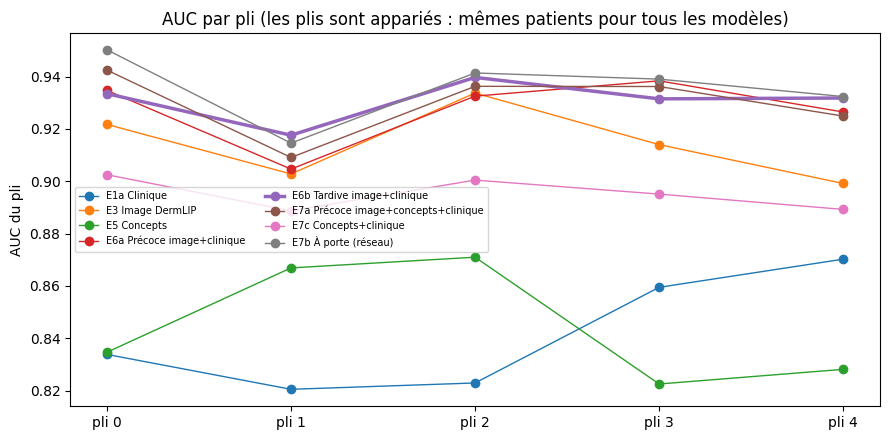

In [63]:
fold_table = pd.DataFrame({n: per_fold_all[n]["AUC"].to_numpy() for n in EXPERIMENTS}, index=[f"pli {k}" for k in range(N_FOLDS)])
plt.figure(figsize=(9, 4.5))
for n in fold_table:
    plt.plot(fold_table.index, fold_table[n], marker="o", lw=2.5 if n == CHOSEN else 1, label=n)
plt.ylabel("AUC du pli")
plt.title("AUC par pli (les plis sont appariés : mêmes patients pour tous les modèles)")
plt.legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_auc_par_pli.png", dpi=150)
plt.show()

### Poids des modalités (modèle à porte)

La porte du modèle E7b attribue à chaque patient un poids par modalité : c'est une première mesure de **ce sur quoi le modèle s'appuie**.

In [64]:
gated = fit_model(GatedFusion(), X_dev, y_dev, groups_dev)
w = gated.modality_weights(X_dev)
print("Poids moyens des modalités :", w.mean().round(3).to_dict())
w.groupby(dev["diagnostic"].to_numpy()).mean().round(3)

Poids moyens des modalités : {'clinique': 0.5680000185966492, 'image': 0.210999995470047, 'concepts': 0.22100000083446503}


,clinique,image,concepts
ACK,0.537,0.223,0.240
BCC,0.644,0.176,0.180
MEL,0.661,0.225,0.114
NEV,0.502,0.240,0.258
SCC,0.601,0.199,0.200
SEK,0.425,0.271,0.304


## 4. E8 — Expérience secondaire : profil patient complet

Sur les seules lignes où le profil patient est renseigné (pas de raccourci possible : il n'y a plus de valeurs manquantes à exploiter), on mesure ce qu'apportent le diamètre, le phototype, les antécédents… **Ces chiffres ne sont pas comparables aux précédents** : ce sous-ensemble contient environ 73 % de cancers.

In [65]:
complete = ~dev[PROFILE_COLS].isna().any(axis=1).to_numpy()
Xs, ys, fs, gs = X_dev[complete].reset_index(drop=True), y_dev[complete], folds[complete], groups_dev[complete]
print(f"Sous-ensemble : {complete.sum()} images, {len(set(gs))} patients, {ys.mean() * 100:.1f} % de cancers")

E8 = {"E8a Clinique (sous-ensemble)": lambda: make_linear_fusion(clin=True),
      "E8b Clinique + profil": lambda: make_linear_fusion(clin=True, profile=True),
      "E8c Image+concepts+clinique + profil": lambda: make_linear_fusion(clin=True, img=True, cpt=True, profile=True)}
e8_rows, e8_oof = [], {}
for name, factory in E8.items():
    per_fold, e8_oof[name] = cross_validate(factory, Xs, ys, fs, groups=gs)
    e8_rows.append(summarize(name, per_fold))
e8 = pd.DataFrame(e8_rows).set_index("Expérience").drop(columns="AUC moyenne")
e8.to_csv(REPORT_DIR / "05_E8_profil_complet.csv")
r = grouped_bootstrap(ys, e8_oof["E8b Clinique + profil"], gs, p_ref=e8_oof["E8a Clinique (sous-ensemble)"])
print("Apport du profil (E8b − E8a) :", {k: round(v, 3) for k, v in r.items()})
e8

Sous-ensemble : 1245 images, 676 patients, 72.5 % de cancers
Apport du profil (E8b − E8a) : {'AUC': np.float64(0.808), 'IC95 bas': np.float64(0.773), 'IC95 haut': np.float64(0.841), 'ΔAUC': np.float64(-0.008), 'ΔAUC IC95 bas': np.float64(-0.023), 'ΔAUC IC95 haut': np.float64(0.007), 'P(Δ ≤ 0)': 0.869}


,AUC,Exactitude équilibrée,Sensibilité,Spécificité,F1
Expérience,,,,,
E8a Clinique (sous-ensemble),0.814 ± 0.044,0.743 ± 0.038,0.761 ± 0.027,0.726 ± 0.051,0.816 ± 0.020
E8b Clinique + profil,0.817 ± 0.052,0.724 ± 0.053,0.754 ± 0.039,0.693 ± 0.077,0.807 ± 0.031
E8c Image+concepts+clinique + profil,0.875 ± 0.035,0.816 ± 0.034,0.839 ± 0.035,0.794 ± 0.068,0.875 ± 0.022


## 5. E9 — Optionnel : ajustement fin de DermLIP (GPU)

Exécutée **seulement si un GPU est disponible** (par exemple sur Colab ou Kaggle). Les images sont d'abord **redimensionnées une seule fois** (256 px, en parallèle sur tous les cœurs) et mises en cache : sans ce cache, le décodage des grandes images PNG à chaque époque sature le processeur et le GPU reste inactif (≈ 5 h au lieu de quelques minutes). Les 2 derniers blocs du ViT et la projection sont dégelés, une petite tête combine le plongement image et les variables cliniques. Nombre d'époques fixé à l'avance (pas de réglage sur la validation). Résultat **exploratoire** : il n'entre pas dans la règle de choix, mais indique le potentiel d'un entraînement complet.

In [66]:
RUN_FINETUNE = torch.cuda.is_available()
FT_EPOCHS, FT_BATCH, FT_UNFREEZE = 12, 32, 2

if not RUN_FINETUNE:
    print("Pas de GPU : section E9 ignorée.")
else:
    import open_clip
    from torch.utils.data import DataLoader, Dataset
    from torchvision import transforms as T

    import os
    import multiprocessing as mp

    # « fork » : les processus héritent des fonctions définies dans le notebook (Linux : Kaggle, Colab)
    MP_CTX = mp.get_context("fork") if "fork" in mp.get_all_start_methods() else None

    device = "cuda"
    CACHE_DIR = ROOT / "data" / "cache_256"
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    CACHE_SIDE = 256

    def cache_path(img_id):
        return CACHE_DIR / (Path(img_id).stem + ".jpg")

    def resize_one(job):
        src, dst = job
        if not dst.exists():
            with Image.open(src) as im:
                im = im.convert("RGB")
                w, h = im.size
                s = CACHE_SIDE / min(w, h)
                im.resize((max(CACHE_SIDE, round(w * s)), max(CACHE_SIDE, round(h * s))),
                          Image.Resampling.BICUBIC).save(dst, quality=95)
        return 1

    t0 = time.time()
    jobs = [(ROOT / p, cache_path(i)) for i, p in zip(dev["img_id"], dev["img_path"])]
    with (MP_CTX or mp).Pool(os.cpu_count()) as pool:
        done = sum(pool.imap_unordered(resize_one, jobs, chunksize=16))
    print(f"Cache d'images prêt : {done} images en {time.time() - t0:.0f} s ({CACHE_DIR})")

    _, _, eval_tf = open_clip.create_model_and_transforms(DERMLIP_ID)
    normalize = next(t for t in eval_tf.transforms if isinstance(t, T.Normalize))
    train_tf = T.Compose([
        T.RandomResizedCrop(224, scale=(0.7, 1.0), interpolation=T.InterpolationMode.BICUBIC),
        T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(20),
        T.ColorJitter(0.1, 0.1, 0.1, 0.02), T.ToTensor(), normalize])

    class LesionDataset(Dataset):
        def __init__(self, frame, clin, tf):
            self.paths = [cache_path(i) for i in frame["img_id"]]     # images redimensionnées (cache)
            self.clin = torch.tensor(np.asarray(clin, dtype=np.float32))
            self.y = torch.tensor(frame["label"].to_numpy(), dtype=torch.float32)
            self.tf = tf

        def __len__(self):
            return len(self.paths)

        def __getitem__(self, i):
            with Image.open(self.paths[i]) as im:
                return self.tf(im.convert("RGB")), self.clin[i], self.y[i]

    class FineTuneNet(torch.nn.Module):
        def __init__(self, clip_model, n_clin):
            super().__init__()
            self.visual = clip_model.visual
            self.head = torch.nn.Sequential(torch.nn.Linear(self.visual.output_dim + n_clin, 64), torch.nn.GELU(),
                                            torch.nn.Dropout(0.3), torch.nn.Linear(64, 1))

        def forward(self, x, clin):
            emb = torch.nn.functional.normalize(self.visual(x), dim=-1)
            return self.head(torch.cat([emb, clin], dim=1)).squeeze(1)

    ft_oof, ft_rows = np.zeros(len(dev)), []
    for k in range(N_FOLDS):
        t0 = time.time()
        tr, va = folds != k, folds == k
        prep = make_clinical_preprocessor().fit(dev.loc[tr, FEATURES])
        clip_k, _, _ = open_clip.create_model_and_transforms(DERMLIP_ID)
        net = FineTuneNet(clip_k, prep.transform(dev.loc[tr, FEATURES]).shape[1]).to(device)
        for p in net.visual.parameters():
            p.requires_grad = False
        trainable = list(net.visual.transformer.resblocks[-FT_UNFREEZE:].parameters()) + list(net.visual.ln_post.parameters())
        if isinstance(net.visual.proj, torch.nn.Parameter):
            trainable.append(net.visual.proj)
        for p in trainable:
            p.requires_grad = True
        opt = torch.optim.AdamW([{"params": trainable, "lr": 1e-5}, {"params": net.head.parameters(), "lr": 1e-3}],
                                weight_decay=0.05)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=FT_EPOCHS)
        ytr = dev.loc[tr, "label"].to_numpy()
        loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - ytr).sum() / ytr.sum(), device=device))
        scaler = torch.amp.GradScaler("cuda")
        train_dl = DataLoader(LesionDataset(dev[tr], prep.transform(dev.loc[tr, FEATURES]), train_tf),
                              batch_size=FT_BATCH, shuffle=True, num_workers=os.cpu_count(), pin_memory=True,
                              drop_last=True, persistent_workers=True, multiprocessing_context=MP_CTX)
        val_dl = DataLoader(LesionDataset(dev[va], prep.transform(dev.loc[va, FEATURES]), eval_tf),
                            batch_size=64, shuffle=False, num_workers=os.cpu_count(), pin_memory=True,
                            multiprocessing_context=MP_CTX)
        for epoch in range(FT_EPOCHS):
            net.train()
            for x, c, y in train_dl:
                opt.zero_grad()
                with torch.autocast("cuda", dtype=torch.float16):
                    loss = loss_fn(net(x.to(device), c.to(device)), y.to(device))
                scaler.scale(loss).backward()
                scaler.step(opt)
                scaler.update()
            sched.step()
            if k == 0 and epoch == 0:
                print(f"  pli 0, 1re époque : {time.time() - t0:.0f} s (estimation du temps total ≈ {(time.time() - t0) * FT_EPOCHS * N_FOLDS / 60:.0f} min)")
        net.eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            ft_oof[va] = np.concatenate([torch.sigmoid(net(x.to(device), c.to(device))).float().cpu().numpy()
                                         for x, c, _ in val_dl])
        ft_rows.append({"pli": k, **metrics_at(y_dev[va], ft_oof[va])})
        print(f"pli {k} : AUC {ft_rows[-1]['AUC']:.3f} ({time.time() - t0:.0f} s)")
        del net, clip_k
        torch.cuda.empty_cache()

    oof_preds["E9 Ajustement fin (GPU)"] = ft_oof
    results.append(summarize("E9 Ajustement fin (GPU)", pd.DataFrame(ft_rows)))
    r = grouped_bootstrap(y_dev, ft_oof, groups_dev, p_ref=oof_preds[CHOSEN])
    print("E9 vs modèle retenu :", {k: round(v, 3) for k, v in r.items()})

Cache d'images prêt : 1940 images en 35 s (/kaggle/working/data/cache_256)
  pli 0, 1re époque : 10 s (estimation du temps total ≈ 10 min)
pli 0 : AUC 0.952 (93 s)
pli 1 : AUC 0.925 (94 s)
pli 2 : AUC 0.942 (92 s)
pli 3 : AUC 0.946 (92 s)
pli 4 : AUC 0.936 (93 s)
E9 vs modèle retenu : {'AUC': np.float64(0.937), 'IC95 bas': np.float64(0.923), 'IC95 haut': np.float64(0.949), 'ΔAUC': np.float64(0.012), 'ΔAUC IC95 bas': np.float64(0.004), 'ΔAUC IC95 haut': np.float64(0.019), 'P(Δ ≤ 0)': 0.001}


## 6. Évaluation finale sur le test

> ⚠ **Le test n'est utilisé qu'ici, une seule fois**, avec le modèle choisi à la section 3. Ne pas revenir modifier le modèle après avoir vu ces résultats : sinon le test devient un jeu de validation et les chiffres sont optimistes.

Les seuils de décision sont fixés **sur les prédictions hors pli du développement** :
- **Youden** : maximise sensibilité + spécificité ;
- **Triage** : premier seuil atteignant une sensibilité ≥ 90 % (manquer un cancer coûte plus cher qu'une consultation de plus) — **point de fonctionnement principal**.

In [67]:
final_model = fit_model(EXPERIMENTS[CHOSEN](), X_dev, y_dev, groups_dev)
clinical_model = fit_model(EXPERIMENTS["E1a Clinique"](), X_dev, y_dev, groups_dev)

fpr, tpr, thr = roc_curve(y_dev, oof_preds[CHOSEN])
THRESHOLDS = {"0,5": 0.5,
              "Youden (dev)": float(thr[np.argmax(tpr - fpr)]),
              "Triage sensibilité ≥ 90 % (dev)": float(thr[np.argmax(tpr >= 0.90)])}
print("Seuils fixés sur le développement :", {k: round(v, 3) for k, v in THRESHOLDS.items()})

p_test = final_model.predict_proba(X_test)[:, 1]
p_test_clin = clinical_model.predict_proba(X_test)[:, 1]
boot = grouped_bootstrap(y_test, p_test, groups_test, p_ref=p_test_clin)
print(f"\nTEST — {CHOSEN} : AUC {boot['AUC']:.3f} [IC95 {boot['IC95 bas']:.3f} – {boot['IC95 haut']:.3f}]")
print(f"Gain sur la clinique seule : ΔAUC {boot['ΔAUC']:+.3f} [IC95 {boot['ΔAUC IC95 bas']:+.3f} – {boot['ΔAUC IC95 haut']:+.3f}]")

operating = pd.DataFrame({k: metrics_at(y_test, p_test, t) for k, t in THRESHOLDS.items()}).T.round(3)
ece, reliability = expected_calibration_error(y_test, p_test)
print(f"Erreur de calibration attendue (ECE) : {ece:.3f}")
operating

Seuils fixés sur le développement : {'0,5': 0.5, 'Youden (dev)': 0.477, 'Triage sensibilité ≥ 90 % (dev)': 0.375}

TEST — E6b Tardive image+clinique : AUC 0.947 [IC95 0.918 – 0.971]
Gain sur la clinique seule : ΔAUC +0.051 [IC95 +0.012 – +0.091]
Erreur de calibration attendue (ECE) : 0.059


,AUC,Exactitude équilibrée,Sensibilité,Spécificité,F1
"0,5",0.947,0.870,0.903,0.837,0.880
Youden (dev),0.947,0.873,0.914,0.831,0.883
Triage sensibilité ≥ 90 % (dev),0.947,0.876,0.968,0.785,0.893


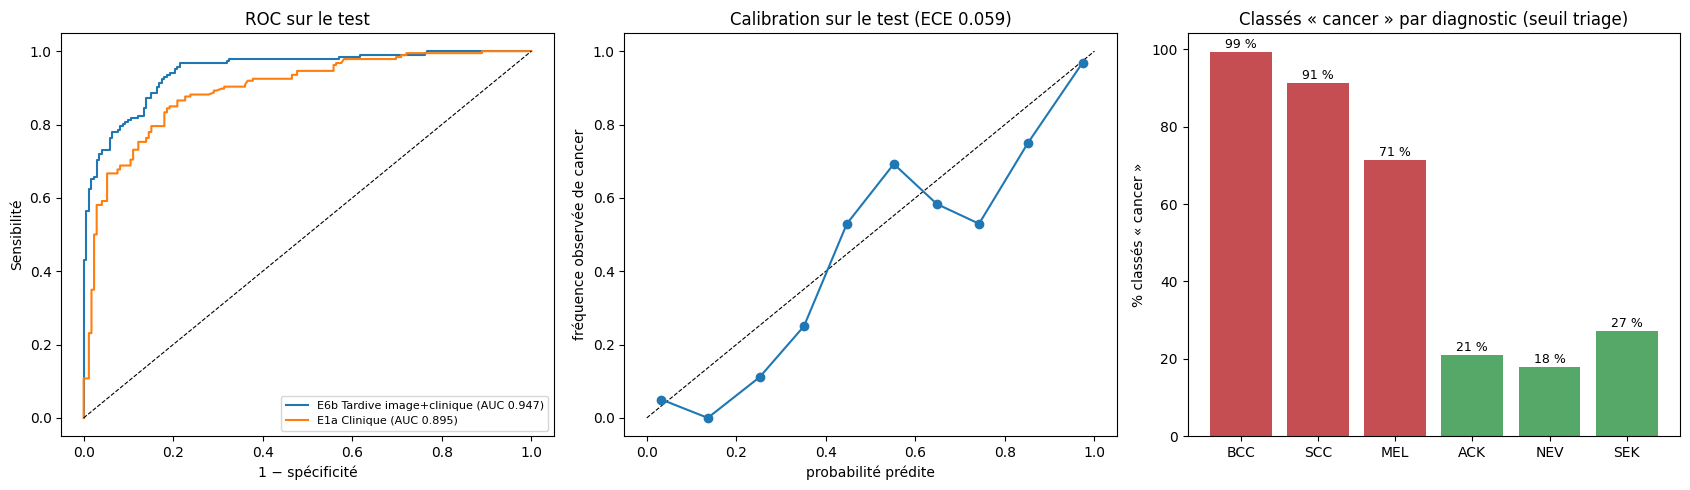

prédit (triage),0,1
vrai,,
0,135,37
1,6,180


In [68]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for name, p in [(CHOSEN, p_test), ("E1a Clinique", p_test_clin)]:
    f, t, _ = roc_curve(y_test, p)
    axes[0].plot(f, t, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set(xlabel="1 − spécificité", ylabel="Sensibilité", title="ROC sur le test")
axes[0].legend(fontsize=8)

axes[1].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[1].plot(reliability["confiance moyenne"], reliability["fréquence observée"], marker="o")
axes[1].set(xlabel="probabilité prédite", ylabel="fréquence observée de cancer",
            title=f"Calibration sur le test (ECE {ece:.3f})")

t_main = THRESHOLDS["Triage sensibilité ≥ 90 % (dev)"]
detect = test.assign(pred=(p_test >= t_main).astype(int)).groupby("diagnostic")["pred"].mean().reindex(
    ["BCC", "SCC", "MEL", "ACK", "NEV", "SEK"])
axes[2].bar(detect.index, detect * 100, color=["#C44E52"] * 3 + ["#55A868"] * 3)
axes[2].set(ylabel="% classés « cancer »", title="Classés « cancer » par diagnostic (seuil triage)")
for i, v in enumerate(detect * 100):
    axes[2].text(i, v + 1, f"{v:.0f} %", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_evaluation_test.png", dpi=150)
plt.show()

pd.crosstab(pd.Series(y_test, name="vrai"), pd.Series((p_test >= t_main).astype(int), name="prédit (triage)"))

In [69]:
if overlap_ids:
    keep = ~test["img_id"].isin(overlap_ids).to_numpy()
    r = grouped_bootstrap(y_test[keep], p_test[keep], groups_test[keep])
    print(f"Test sans les {(~keep).sum()} images signalées par le contrôle Derm1M : "
          f"AUC {r['AUC']:.3f} [IC95 {r['IC95 bas']:.3f} – {r['IC95 haut']:.3f}]")
else:
    print("Aucune image signalée par le contrôle de chevauchement (ou contrôle non vérifié : voir notebook 03).")

Aucune image signalée par le contrôle de chevauchement (ou contrôle non vérifié : voir notebook 03).


## 7. Sauvegarde du modèle final

In [70]:
reference = {c: float(X_dev[c].median()) for c in NUM_COLS}                       # valeur « typique »
reference.update({c: X_dev[c].mode().iloc[0] for c in BOOL_COLS + CAT_COLS})        # utilisée par les explications
bundle = {
    "nom": CHOSEN,
    "modele": final_model,
    "modele_clinique": clinical_model,
    "seuils": THRESHOLDS,
    "seuil_principal": "Triage sensibilité ≥ 90 % (dev)",
    "dermlip_id": DERMLIP_ID,
    "concepts": CONCEPT_NAMES,
    "reference_clinique": reference,
    "reference_concepts": X_dev[CONCEPT_COLS].mean().to_dict(),
    "reference_image": X_dev[IMG_COLS].mean().to_numpy(),
    "date": time.strftime("%Y-%m-%d %H:%M"),
}
joblib.dump(bundle, CKPT_DIR / "final_model.joblib")

test_out = test[["img_id", "patient_id", "diagnostic", "label"]].assign(proba=p_test, proba_clinique=p_test_clin)
test_out.to_csv(REPORT_DIR / "05_predictions_test.csv", index=False)
summary = {"modele_retenu": CHOSEN, "auc_validation_croisee": round(float(auc_mean[CHOSEN]), 4),
           "test": {k: round(float(v), 4) for k, v in boot.items()}, "ece_test": round(float(ece), 4),
           "seuils": {k: round(v, 4) for k, v in THRESHOLDS.items()},
           "points_de_fonctionnement_test": operating.to_dict(orient="index")}
(REPORT_DIR / "05_synthese.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf8")
print("Enregistrés : final_model.joblib, 05_predictions_test.csv, 05_synthese.json")

Enregistrés : final_model.joblib, 05_predictions_test.csv, 05_synthese.json


## Conclusion (à compléter après exécution)

- **Modèle retenu** et justification par la règle fixée à l'avance.
- **Apport de la fusion** : ΔAUC du modèle retenu face à la clinique seule et à l'image seule (validation croisée et test, avec IC 95 %).
- **Test** : AUC [IC 95 %], sensibilité et spécificité au seuil de triage, calibration (ECE), taux de détection par diagnostic — en particulier le **mélanome** (peu de cas : interpréter avec prudence).
- **E8** : apport du profil patient quand il est disponible.
- **E9** (si GPU) : potentiel de l'ajustement fin.

**Étape suivante** : `06_xai_evaluation.ipynb`.

---
# PARTIE 06 — Explicabilité et biais

# 06 — Explicabilité, fidélité des explications et analyse des biais

**Principe** : la décision vient du modèle entraîné et évalué (notebook 05). Ce notebook **explique** cette décision et **vérifie** que les explications sont fidèles ; il ne modifie jamais la probabilité.

| Section | Question | Méthode |
|---|---|---|
| 1 | Sur quelle modalité le modèle s'appuie-t-il ? | importance par permutation (par modalité et par variable) |
| 2 | Pourquoi ce patient ? | contribution par remplacement (équivalente à SHAP pour un modèle linéaire) |
| 3 | Où regarde le modèle dans l'image ? | **carte d'occlusion** : on masque chaque zone et on mesure la baisse de probabilité |
| 4 | Les cartes sont-elles fidèles ? | test de suppression : masquer les zones désignées doit faire baisser la probabilité plus que masquer des zones au hasard |
| 5 | Le modèle utilise-t-il l'encre chirurgicale ? | détection des marques d'encre + performance et attention sur ces images |
| 6 | Que dire au médecin ? | rapport texte par **gabarit** à partir des sorties calculées |
| 7–8 | Où se trompe-t-il ? Pour qui ? | analyse d'erreurs, analyse par phototype |

*Pourquoi l'occlusion plutôt que Grad-CAM ?* Elle traverse **tout** le modèle final (image → concepts → fusion → probabilité) sans hypothèse sur son architecture et mesure un effet réel sur la décision : elle est fidèle par construction.

**Prérequis** : notebook 05 exécuté (`outputs/checkpoints/final_model.joblib`). DermLIP est rechargé (cache Hugging Face) pour les cartes d'occlusion. Sur CPU, les sections 3 à 5 prennent de l'ordre de 10 à 20 minutes.

## 0. Imports, données, fonctions et modèles communs

In [71]:
from pathlib import Path
import json
import re
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_FOLDS = 5
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "zr7vgbcyr2-1" / "metadata.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
EXTERNAL_DIR = ROOT / "data" / "external" / "derm1m"
CONFIG_DIR = ROOT / "configs"
FIG_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
CKPT_DIR = ROOT / "outputs" / "checkpoints"
for d in (PROCESSED_DIR, FIG_DIR, REPORT_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

# variables cliniques retenues (notebook 01) — le profil patient n'est utilisé que dans l'expérience E8
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS
PROFILE_NUM = ["fitspatrick", "diameter_1", "diameter_2"]
PROFILE_BOOL = ["smoke", "drink", "pesticide", "skin_cancer_history", "cancer_history"]
PROFILE_CAT = ["gender"]
PROFILE_COLS = PROFILE_NUM + PROFILE_BOOL + PROFILE_CAT

CANCER_CLASSES = ["BCC", "SCC", "MEL"]
DERMLIP_ID = "hf-hub:redlessone/DermLIP_ViT-B-16"

In [72]:
splits = pd.read_csv(PROCESSED_DIR / "splits.csv")
meta = pd.read_csv(CSV_PATH, na_values=["UNK"])

df = splits.merge(meta[["img_id"] + FEATURES + PROFILE_COLS], on="img_id", how="left",
                  validate="one_to_one")
TO_FLOAT = {True: 1.0, False: 0.0, "True": 1.0, "False": 0.0}
for c in BOOL_COLS + PROFILE_BOOL:                     # True / False / NaN -> 1.0 / 0.0 / NaN
    df[c] = df[c].map(TO_FLOAT)

dev = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
y_dev, folds, groups_dev = dev["label"].to_numpy(), dev["fold"].to_numpy(), dev["patient_id"].to_numpy()
y_test, groups_test = test["label"].to_numpy(), test["patient_id"].to_numpy()

print(f"Développement : {len(dev)} images, {dev['patient_id'].nunique()} patients | "
      f"test : {len(test)} images (non utilisé avant l'évaluation finale)")
assert set(folds) == set(range(N_FOLDS))

Développement : 1940 images, 1176 patients | test : 358 images (non utilisé avant l'évaluation finale)


In [73]:
def metrics_at(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y_true, proba),
        "Exactitude équilibrée": balanced_accuracy_score(y_true, y_pred),
        "Sensibilité": recall_score(y_true, y_pred, pos_label=1),
        "Spécificité": recall_score(y_true, y_pred, pos_label=0),
        "F1": f1_score(y_true, y_pred),
    }


def take_rows(X, idx):
    return X.iloc[idx] if isinstance(X, pd.DataFrame) else X[idx]


def fit_model(model, X, y, groups=None):
    """Entraîne un modèle ; transmet `groups` aux modèles qui choisissent leurs hyperparamètres par patient."""
    needs_groups = isinstance(model, GridSearchCV) or getattr(model, "uses_groups", False)
    if needs_groups:
        assert groups is not None, "ce modèle a besoin des identifiants patients (groups)"
        return model.fit(X, y, groups=groups)
    return model.fit(X, y)


def cross_validate(make_model, X, y, folds, groups=None, return_models=False):
    """Validation croisée sur les 5 plis groupés par patient : métriques par pli + prédictions hors pli."""
    oof, rows, models = np.zeros(len(y)), [], []
    for k in range(N_FOLDS):
        tr, va = np.flatnonzero(folds != k), np.flatnonzero(folds == k)
        model = make_model()
        fit_model(model, take_rows(X, tr), y[tr], None if groups is None else groups[tr])
        oof[va] = model.predict_proba(take_rows(X, va))[:, 1]
        rows.append({"pli": k, **metrics_at(y[va], oof[va])})
        models.append(model)
    per_fold = pd.DataFrame(rows)
    return (per_fold, oof, models) if return_models else (per_fold, oof)


def summarize(name, per_fold):
    m = per_fold.drop(columns="pli")
    return {"Expérience": name, **{c: f"{m[c].mean():.3f} ± {m[c].std():.3f}" for c in m.columns},
            "AUC moyenne": m["AUC"].mean()}


def grouped_bootstrap(y, p, groups, p_ref=None, n_boot=2000, seed=SEED):
    """AUC et IC 95 % par bootstrap des patients ; avec `p_ref`, différence d'AUC appariée."""
    y, p, groups = np.asarray(y), np.asarray(p), np.asarray(groups)
    uniq, inv = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(inv == g) for g in range(len(uniq))]
    rng = np.random.default_rng(seed)
    aucs, diffs = [], []
    for _ in range(n_boot):
        idx = np.concatenate([members[g] for g in rng.integers(0, len(uniq), len(uniq))])
        if y[idx].min() == y[idx].max():
            continue
        a = roc_auc_score(y[idx], p[idx])
        aucs.append(a)
        if p_ref is not None:
            diffs.append(a - roc_auc_score(y[idx], np.asarray(p_ref)[idx]))
    out = {"AUC": roc_auc_score(y, p), "IC95 bas": np.percentile(aucs, 2.5), "IC95 haut": np.percentile(aucs, 97.5)}
    if p_ref is not None:
        d = np.asarray(diffs)
        out.update({"ΔAUC": out["AUC"] - roc_auc_score(y, p_ref),
                    "ΔAUC IC95 bas": np.percentile(d, 2.5), "ΔAUC IC95 haut": np.percentile(d, 97.5),
                    "P(Δ ≤ 0)": float((d <= 0).mean())})
    return out


def make_clinical_preprocessor(num=NUM_COLS, bools=BOOL_COLS, cats=CAT_COLS):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("bool", SimpleImputer(strategy="most_frequent"), bools),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cats),
    ])


C_GRID = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]


def make_probe(c_grid=C_GRID):
    """Sonde linéaire : standardisation + logistique, C choisi par validation croisée groupée (patients)."""
    pipe = Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
    return GridSearchCV(pipe, {"clf__C": c_grid}, cv=GroupKFold(n_splits=3), scoring="roc_auc", n_jobs=-1)


def load_features(name):
    """Charge un cache de caractéristiques et renvoie une fonction frame -> matrice alignée sur frame['img_id']."""
    feats = np.load(PROCESSED_DIR / f"features_{name}.npy")
    ids = pd.read_csv(PROCESSED_DIR / f"features_{name}_ids.csv")["img_id"]
    index = pd.Series(np.arange(len(ids)), index=ids.to_numpy())
    return lambda frame: feats[index.loc[frame["img_id"]].to_numpy()]


results, oof_preds = [], {}

In [74]:
from functools import partial

import joblib
import torch
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit


def make_linear_fusion(clin=True, img=False, cpt=False, profile=False):
    """Fusion précoce : blocs (clinique / image / concepts) prétraités puis une régression logistique.
    C (et la réduction PCA de l'image) sont choisis par validation croisée groupée par patient."""
    blocks = []
    if clin:
        num, bools, cats = ((NUM_COLS + PROFILE_NUM, BOOL_COLS + PROFILE_BOOL, CAT_COLS + PROFILE_CAT)
                            if profile else (NUM_COLS, BOOL_COLS, CAT_COLS))
        blocks.append(("clin", make_clinical_preprocessor(num, bools, cats), num + bools + cats))
    if img:
        blocks.append(("img", Pipeline([("scale", StandardScaler()), ("pca", PCA(random_state=SEED))]), IMG_COLS))
    if cpt:
        blocks.append(("cpt", StandardScaler(), CONCEPT_COLS))
    pipe = Pipeline([("prep", ColumnTransformer(blocks)), ("scale", StandardScaler()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])
    grid = {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}
    if img:
        grid["prep__img__pca__n_components"] = [16, 64, 128]
    return GridSearchCV(pipe, grid, cv=GroupKFold(n_splits=3), scoring="roc_auc", n_jobs=-1)


def _logit(p, eps=1e-6):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


class LateFusion(BaseEstimator, ClassifierMixin):
    """Fusion tardive (stacking) : un modèle par modalité, combinés par une logistique apprise
    sur leurs prédictions hors pli internes (groupées par patient)."""
    uses_groups = True

    def __init__(self, base_factories=(), n_inner=3):
        self.base_factories = base_factories
        self.n_inner = n_inner

    def fit(self, X, y, groups):
        y, groups = np.asarray(y), np.asarray(groups)
        Z = np.zeros((len(y), len(self.base_factories)))
        for tr, va in GroupKFold(n_splits=self.n_inner).split(X, y, groups):
            for j, (_, factory) in enumerate(self.base_factories):
                m = fit_model(factory(), take_rows(X, tr), y[tr], groups[tr])
                Z[va, j] = _logit(m.predict_proba(take_rows(X, va))[:, 1])
        self.meta_ = LogisticRegression(class_weight="balanced").fit(Z, y)
        self.bases_ = [fit_model(f(), X, y, groups) for _, f in self.base_factories]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        Z = np.column_stack([_logit(m.predict_proba(X)[:, 1]) for m in self.bases_])
        return self.meta_.predict_proba(Z)


class _GatedNet(torch.nn.Module):
    def __init__(self, dims, hidden, dropout):
        super().__init__()
        self.encoders = torch.nn.ModuleList([
            torch.nn.Sequential(torch.nn.Linear(d, hidden), torch.nn.GELU(), torch.nn.Dropout(dropout)) for d in dims])
        self.gate = torch.nn.Linear(hidden * len(dims), len(dims))
        self.head = torch.nn.Sequential(torch.nn.LayerNorm(hidden), torch.nn.Linear(hidden, 1))

    def forward(self, xs):
        hs = [enc(x) for enc, x in zip(self.encoders, xs)]
        w = torch.softmax(self.gate(torch.cat(hs, dim=1)), dim=1)        # poids de chaque modalité
        fused = sum(w[:, i:i + 1] * h for i, h in enumerate(hs))
        return self.head(fused).squeeze(1), w


class GatedFusion(BaseEstimator, ClassifierMixin):
    """Fusion à porte : un petit réseau par modalité, une porte apprend le poids de chaque modalité
    pour chaque patient. Arrêt anticipé sur 15 % des patients du pli ; moyenne de plusieurs graines."""
    uses_groups = True
    MODALITIES = ("clinique", "image", "concepts")

    def __init__(self, hidden=32, dropout=0.3, lr=1e-3, weight_decay=1e-2, max_epochs=400,
                 patience=30, n_seeds=5, val_size=0.15, img_pca=64):
        self.hidden, self.dropout, self.lr, self.weight_decay = hidden, dropout, lr, weight_decay
        self.max_epochs, self.patience, self.n_seeds = max_epochs, patience, n_seeds
        self.val_size, self.img_pca = val_size, img_pca

    def _blocks(self):
        return [("clin", make_clinical_preprocessor(), FEATURES),
                ("img", Pipeline([("scale", StandardScaler()),
                                  ("pca", PCA(n_components=self.img_pca, random_state=SEED))]), IMG_COLS),
                ("cpt", StandardScaler(), CONCEPT_COLS)]

    def _transform(self, X):
        return [torch.tensor(np.asarray(p.transform(X[cols]), dtype=np.float32))
                for (_, _, cols), p in zip(self._blocks(), self.preps_)]

    def fit(self, X, y, groups):
        y = np.asarray(y, dtype=np.float32)
        tr, va = next(GroupShuffleSplit(n_splits=1, test_size=self.val_size, random_state=SEED)
                      .split(X, y, groups))
        Xtr, Xva = take_rows(X, tr), take_rows(X, va)
        self.preps_ = [p.fit(Xtr[cols]) for _, p, cols in self._blocks()]
        xtr, xva = self._transform(Xtr), self._transform(Xva)
        ytr, yva = torch.tensor(y[tr]), torch.tensor(y[va])
        loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - y[tr]).sum() / max(y[tr].sum(), 1.0)))
        self.nets_ = []
        for s in range(self.n_seeds):
            torch.manual_seed(SEED + s)
            net = _GatedNet([x.shape[1] for x in xtr], self.hidden, self.dropout)
            opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.weight_decay)
            best, best_state, wait = np.inf, None, 0
            for _ in range(self.max_epochs):
                net.train()
                opt.zero_grad()
                loss_fn(net(xtr)[0], ytr).backward()
                opt.step()
                net.eval()
                with torch.no_grad():
                    v = loss_fn(net(xva)[0], yva).item()
                if v < best - 1e-4:
                    best, wait = v, 0
                    best_state = {k: t.detach().clone() for k, t in net.state_dict().items()}
                else:
                    wait += 1
                    if wait >= self.patience:
                        break
            net.load_state_dict(best_state)
            net.eval()
            self.nets_.append(net)
        self.classes_ = np.array([0, 1])
        return self

    def _forward(self, X):
        xs = self._transform(X)
        with torch.no_grad():
            outs = [net(xs) for net in self.nets_]
        p = np.mean([torch.sigmoid(o[0]).numpy() for o in outs], axis=0)
        w = np.mean([o[1].numpy() for o in outs], axis=0)
        return p, w

    def predict_proba(self, X):
        p, _ = self._forward(X)
        return np.column_stack([1 - p, p])

    def modality_weights(self, X):
        return pd.DataFrame(self._forward(X)[1], columns=list(self.MODALITIES))


def expected_calibration_error(y, p, n_bins=10):
    y, p = np.asarray(y), np.asarray(p)
    idx = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    rows, ece = [], 0.0
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(y[m].mean() - p[m].mean())
            rows.append({"confiance moyenne": p[m].mean(), "fréquence observée": y[m].mean(), "n": int(m.sum())})
    return ece, pd.DataFrame(rows)

In [75]:
take_img = load_features("dermlip_vitb16")
emb_bank = np.load(PROCESSED_DIR / "concept_text_embeddings.npz", allow_pickle=True)
selected = pd.read_csv(PROCESSED_DIR / "concepts_selected.csv")
CONCEPT_NAMES = selected.loc[selected["retenu"], "concept"].tolist()
_name_to_row = {n: i for i, n in enumerate(emb_bank["names"])}
CPT_EMB = emb_bank["concept_emb"][[_name_to_row[n] for n in CONCEPT_NAMES]]
REF_EMB = emb_bank["ref_emb"]

N_IMG = take_img(dev.head(1)).shape[1]
IMG_COLS = [f"img_{i}" for i in range(N_IMG)]
CONCEPT_COLS = [f"c_{n}" for n in CONCEPT_NAMES]


def concept_scores(emb):
    """Score de concept = similarité image/concept moins similarité image/référence neutre."""
    return emb @ CPT_EMB.T - (emb @ REF_EMB)[:, None]


def build_frame(frame, emb=None):
    """Table complète : variables cliniques + plongement image DermLIP + scores de concepts."""
    emb = take_img(frame) if emb is None else emb
    clin = frame[FEATURES + PROFILE_COLS].reset_index(drop=True)
    img = pd.DataFrame(emb, columns=IMG_COLS)
    cpt = pd.DataFrame(concept_scores(emb), columns=CONCEPT_COLS)
    return pd.concat([clin, img, cpt], axis=1)


print("Concepts retenus :", len(CONCEPT_NAMES), "| dimension image :", N_IMG)

Concepts retenus : 16 | dimension image : 512


## Chargement du modèle final et contrôle de reproductibilité

In [76]:
bundle = joblib.load(CKPT_DIR / "final_model.joblib")
final_model = bundle["modele"]
assert bundle["concepts"] == CONCEPT_NAMES, "concepts différents de ceux du notebook 05"
T_MAIN = bundle["seuils"][bundle["seuil_principal"]]

X_test = build_frame(test)
p_test = final_model.predict_proba(X_test)[:, 1]
saved = pd.read_csv(REPORT_DIR / "05_predictions_test.csv").set_index("img_id").loc[test["img_id"], "proba"]
assert np.allclose(p_test, saved.to_numpy(), atol=1e-6), "les prédictions ne correspondent pas au notebook 05"
print(f"Modèle : {bundle['nom']} | seuil de triage : {T_MAIN:.3f} | AUC test : {roc_auc_score(y_test, p_test):.3f}")

LABELS_FR = dict(zip(emb_bank["names"], emb_bank["labels_fr"]))
CLIN_FR = {"age": "âge", "itch": "démangeaison", "grew": "a grossi", "hurt": "douleur",
           "changed": "a changé", "bleed": "saignement", "elevation": "relief", "region": "localisation"}

Modèle : E6b Tardive image+clinique | seuil de triage : 0.375 | AUC test : 0.947


## 1. Importance globale par permutation (sur le test)

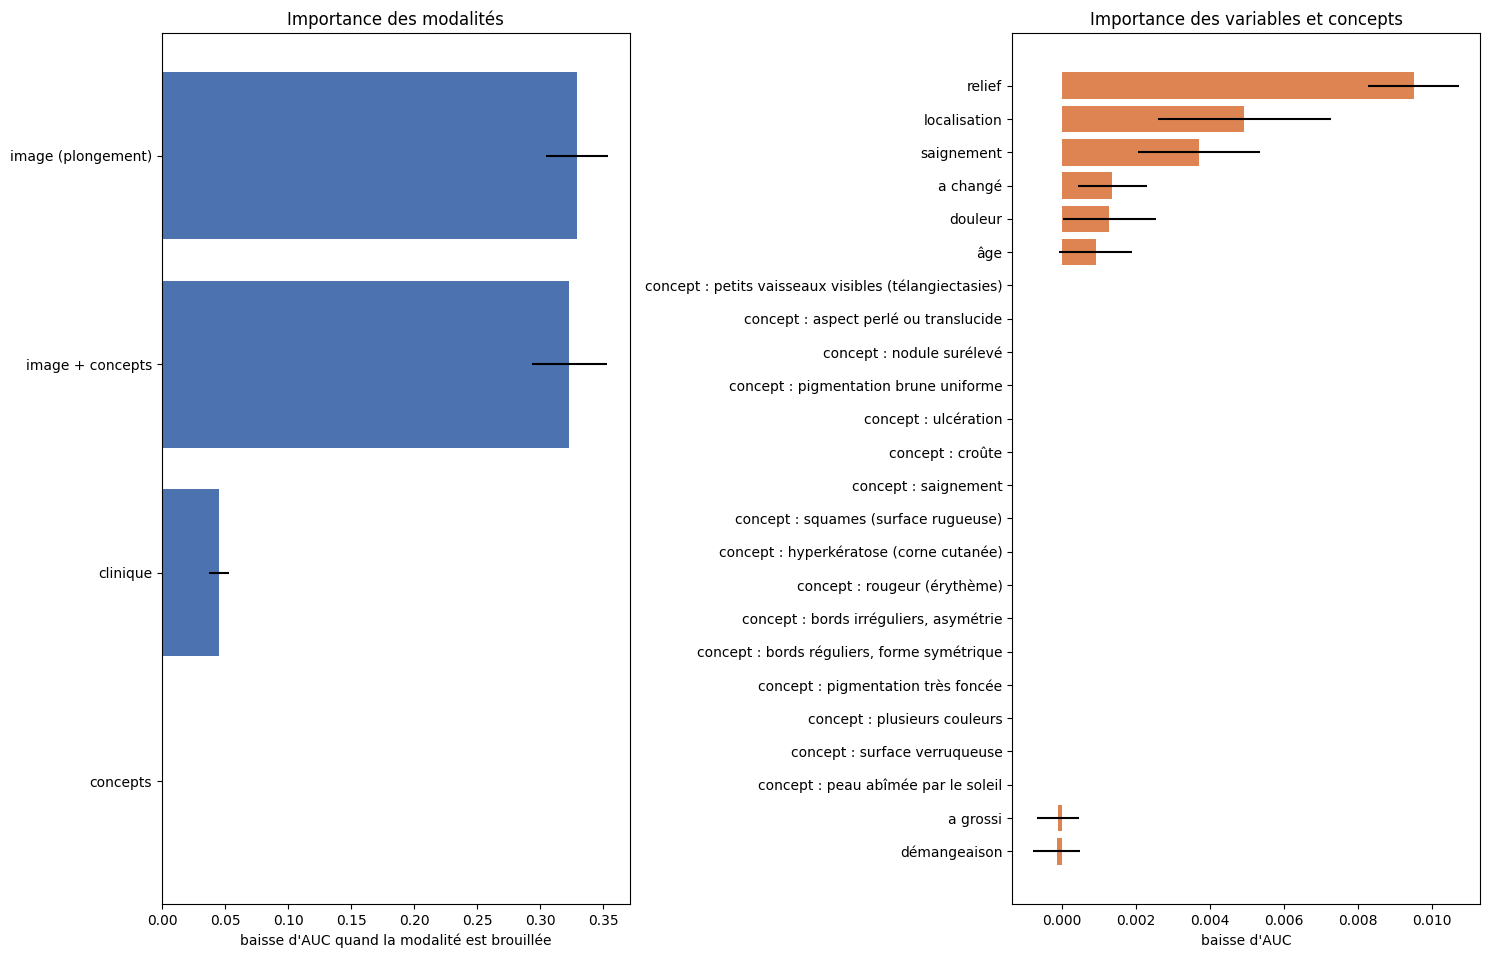

,élément,baisse d'AUC,écart-type
1,image (plongement),0.3291,0.0243
3,image + concepts,0.3232,0.0294
0,clinique,0.0453,0.0079
2,concepts,0.0000,0.0000


In [77]:
def permutation_drop(model, X, y, col_groups, n_repeats=20, seed=SEED):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(y, model.predict_proba(X)[:, 1])
    rows = []
    for name, cols in col_groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].to_numpy()[rng.permutation(len(X))]
            drops.append(base - roc_auc_score(y, model.predict_proba(Xp)[:, 1]))
        rows.append({"élément": name, "baisse d'AUC": np.mean(drops), "écart-type": np.std(drops)})
    return pd.DataFrame(rows).sort_values("baisse d'AUC", ascending=False)


modalities = permutation_drop(final_model, X_test, y_test, {
    "clinique": FEATURES, "image (plongement)": IMG_COLS, "concepts": CONCEPT_COLS,
    "image + concepts": IMG_COLS + CONCEPT_COLS})
variables = permutation_drop(final_model, X_test, y_test,
                             {**{CLIN_FR[c]: [c] for c in FEATURES},
                              **{f"concept : {LABELS_FR[n]}": [c] for n, c in zip(CONCEPT_NAMES, CONCEPT_COLS)}},
                             n_repeats=10)

fig, axes = plt.subplots(1, 2, figsize=(15, 0.32 * len(variables) + 2))
axes[0].barh(modalities["élément"], modalities["baisse d'AUC"], xerr=modalities["écart-type"], color="#4C72B0")
axes[0].invert_yaxis()
axes[0].set(title="Importance des modalités", xlabel="baisse d'AUC quand la modalité est brouillée")
axes[1].barh(variables["élément"], variables["baisse d'AUC"], xerr=variables["écart-type"], color="#DD8452")
axes[1].invert_yaxis()
axes[1].set(title="Importance des variables et concepts", xlabel="baisse d'AUC")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_importance_permutation.png", dpi=150)
plt.show()
modalities.round(4)

## 2. Explication locale : contribution par remplacement

Pour un patient, on remplace **un seul** élément par une valeur de référence (médiane ou valeur la plus fréquente du développement) et on mesure la variation du logit de la probabilité. Pour un modèle linéaire, c'est exactement la décomposition de SHAP ; pour un autre modèle, c'est une approximation locale honnête et facile à expliquer.

In [78]:
REF_CLIN, REF_CPT, REF_IMG = bundle["reference_clinique"], bundle["reference_concepts"], bundle["reference_image"]


def logit_of(X):
    return _logit(final_model.predict_proba(X)[:, 1])


def local_contributions(xrow):
    """xrow : DataFrame d'une ligne (issu de build_frame). Contribution > 0 : pousse vers « cancer »."""
    variants, meta_rows = [], []
    for c in FEATURES:
        v = xrow.copy()
        v[c] = REF_CLIN[c]
        variants.append(v)
        meta_rows.append(("clinique", c, CLIN_FR[c]))
    for n, c in zip(CONCEPT_NAMES, CONCEPT_COLS):
        v = xrow.copy()
        v[c] = REF_CPT[c]
        variants.append(v)
        meta_rows.append(("concept", n, f"concept « {LABELS_FR[n]} »"))
    v = xrow.copy()
    v.loc[:, IMG_COLS] = REF_IMG.reshape(1, -1)
    variants.append(v)
    meta_rows.append(("image", "image", "aspect global de l'image"))
    delta = logit_of(xrow)[0] - logit_of(pd.concat(variants, ignore_index=True))
    out = pd.DataFrame(meta_rows, columns=["type", "clé", "élément"]).assign(contribution=delta)
    return out.reindex(out["contribution"].abs().sort_values(ascending=False).index).reset_index(drop=True)


pos = test.index[(y_test == 1) & (p_test >= T_MAIN)]
example = int(pos[np.argmax(p_test[pos])]) if len(pos) else int(np.argmax(p_test))
print(f"Exemple : {test.loc[example, 'img_id']} ({test.loc[example, 'diagnostic']}), probabilité {p_test[example]:.3f}")
local_contributions(X_test.iloc[[example]]).head(10).round(3)

Exemple : PAT_460_893_307.png (BCC), probabilité 1.000


,type,clé,élément,contribution
0,image,image,aspect global de l'image,5.922
1,clinique,bleed,saignement,0.763
2,clinique,region,localisation,0.646
3,clinique,hurt,douleur,0.620
4,clinique,grew,a grossi,0.169
5,clinique,age,âge,0.136
6,clinique,changed,a changé,-0.000
7,clinique,elevation,relief,-0.000
8,clinique,itch,démangeaison,-0.000
9,concept,pearly_translucent,concept « aspect perlé ou translucide »,-0.000


## 3. Cartes d'occlusion

L'image prétraitée (224 × 224) est découpée en 8 × 8 zones. Chaque zone est remplacée à son tour par la couleur moyenne (0 après normalisation), l'image est ré-encodée par DermLIP, les concepts sont recalculés et le modèle final redonne une probabilité. **Rouge** : la zone pousse vers « cancer » ; **bleu** : vers « non-cancer ».

> La cellule suivante charge DermLIP (cache Hugging Face, téléchargé au notebook 03).

In [79]:
try:
    import open_clip
    import torch
except ImportError as e:
    raise ImportError("Installez open_clip :  pip install open_clip_torch") from e

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
model, _, preprocess = open_clip.create_model_and_transforms(DERMLIP_ID)
tokenizer = open_clip.get_tokenizer(DERMLIP_ID)
model = model.to(device).eval()
LOGIT_SCALE = float(model.logit_scale.exp().item())
print("DermLIP chargé sur", device, "| échelle des logits :", round(LOGIT_SCALE, 1))


@torch.no_grad()
def encode_texts(texts):
    emb = model.encode_text(tokenizer(texts).to(device)).float()
    return torch.nn.functional.normalize(emb, dim=-1).cpu().numpy()


def prompt_embedding(prompts):
    """Moyenne des plongements de plusieurs formulations, renormalisée (« ensemble de prompts »)."""
    e = encode_texts(prompts).mean(axis=0)
    return e / np.linalg.norm(e)


@torch.no_grad()
def encode_tensors(x):
    emb = model.encode_image(x.to(device)).float()
    return torch.nn.functional.normalize(emb, dim=-1).cpu().numpy()


def load_tensor(path):
    with Image.open(path) as im:
        return preprocess(im.convert("RGB"))

DermLIP chargé sur cuda | échelle des logits : 100.0


In [80]:
from matplotlib.colors import rgb_to_hsv
from torchvision import transforms as T

GRID = 8
NORM = next(t for t in preprocess.transforms if isinstance(t, T.Normalize))
MEAN, STD = torch.tensor(NORM.mean).view(3, 1, 1), torch.tensor(NORM.std).view(3, 1, 1)


def to_rgb(x):
    return (x * STD + MEAN).clamp(0, 1).permute(1, 2, 0).numpy()


def cell_slices(i, j, size):
    step = size // GRID
    return slice(i * step, (i + 1) * step), slice(j * step, (j + 1) * step)


def proba_of_tensors(i_test, tensors, batch=16):
    embs = np.concatenate([encode_tensors(torch.stack(tensors[s:s + batch])) for s in range(0, len(tensors), batch)])
    rows = pd.concat([test.iloc[[i_test]]] * len(embs), ignore_index=True)
    return final_model.predict_proba(build_frame(rows, emb=embs))[:, 1]


heat_cache = {}


def occlusion_map(i_test):
    if i_test in heat_cache:
        return heat_cache[i_test]
    x = load_tensor(ROOT / test.loc[i_test, "img_path"])
    variants = [x]
    for i in range(GRID):
        for j in range(GRID):
            v = x.clone()
            si, sj = cell_slices(i, j, x.shape[1])
            v[:, si, sj] = 0.0
            variants.append(v)
    p = proba_of_tensors(i_test, variants)
    heat_cache[i_test] = (x, p[0], (p[0] - p[1:]).reshape(GRID, GRID))
    return heat_cache[i_test]


def show_occlusion(ax_img, ax_heat, i_test, title=""):
    x, p0, heat = occlusion_map(i_test)
    rgb = to_rgb(x)
    ax_img.imshow(rgb)
    ax_img.set_title(title, fontsize=9)
    vmax = max(np.abs(heat).max(), 1e-6)
    ax_heat.imshow(rgb)
    ax_heat.imshow(np.kron(heat, np.ones((x.shape[1] // GRID, x.shape[2] // GRID))), cmap="RdBu_r",
                   vmin=-vmax, vmax=vmax, alpha=0.5)
    ax_heat.set_title(f"occlusion (p = {p0:.2f})", fontsize=9)
    for a in (ax_img, ax_heat):
        a.axis("off")


x0, p0, _ = occlusion_map(example)
print(f"Contrôle : probabilité recalculée {p0:.4f} vs notebook 05 {p_test[example]:.4f}")

Contrôle : probabilité recalculée 0.9997 vs notebook 05 0.9997


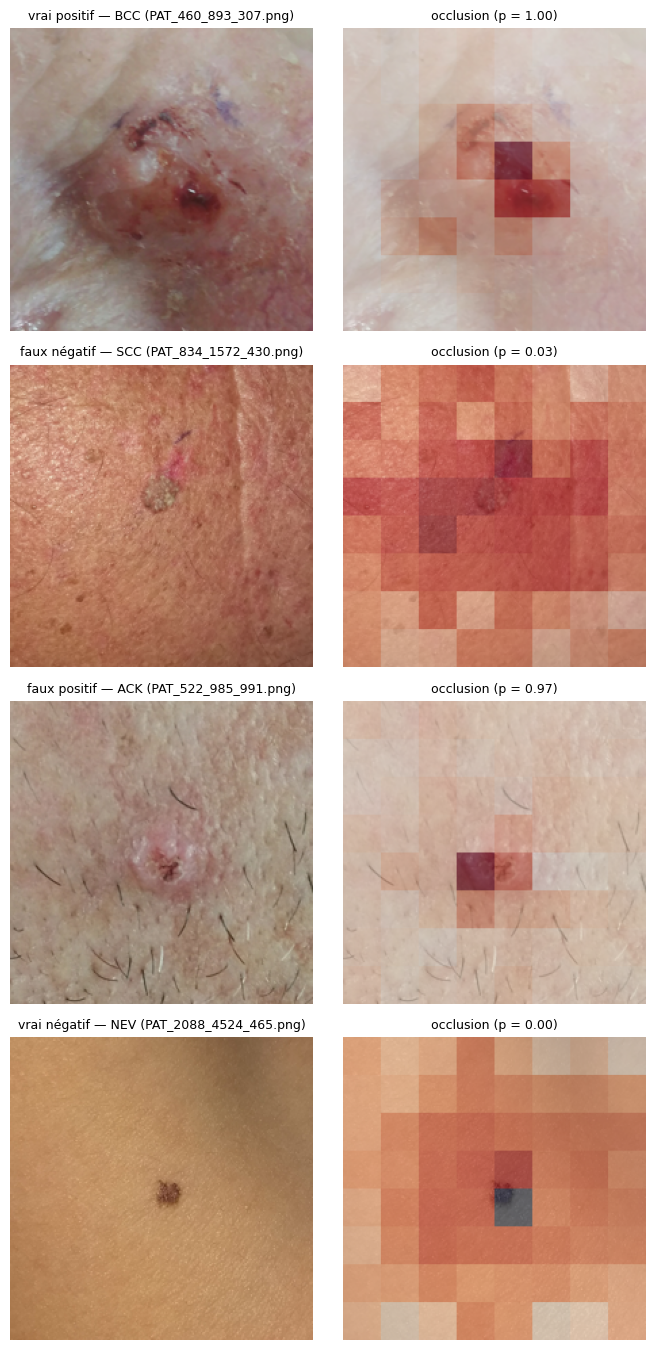

In [81]:
cases = {}
cancer_idx, benign_idx = np.flatnonzero(y_test == 1), np.flatnonzero(y_test == 0)
tp = cancer_idx[p_test[cancer_idx] >= T_MAIN]
fn = cancer_idx[p_test[cancer_idx] < T_MAIN]
fp = benign_idx[p_test[benign_idx] >= T_MAIN]
tn = benign_idx[p_test[benign_idx] < T_MAIN]
if len(tp): cases["vrai positif"] = int(tp[np.argmax(p_test[tp])])
if len(fn): cases["faux négatif"] = int(fn[np.argmin(p_test[fn])])
if len(fp): cases["faux positif"] = int(fp[np.argmax(p_test[fp])])
if len(tn): cases["vrai négatif"] = int(tn[np.argmin(p_test[tn])])

fig, axes = plt.subplots(len(cases), 2, figsize=(7, 3.4 * len(cases)), squeeze=False)
for r, (kind, i) in enumerate(cases.items()):
    show_occlusion(axes[r, 0], axes[r, 1], i, f"{kind} — {test.loc[i, 'diagnostic']} ({test.loc[i, 'img_id']})")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_cartes_occlusion.png", dpi=130)
plt.show()

## 4. Fidélité des cartes : test de suppression

Pour les cancers du test les mieux reconnus, on masque les 25 % de zones jugées les plus importantes par la carte, puis 25 % de zones tirées au hasard (3 tirages). Si la carte est fidèle, la probabilité doit baisser **nettement plus** dans le premier cas (test de Wilcoxon apparié, unilatéral).

In [82]:
from scipy.stats import wilcoxon

N_FIDELITY, K_TOP, N_RANDOM = 40, GRID * GRID // 4, 3
rng = np.random.default_rng(SEED)


def masked(x, cells):
    v = x.clone()
    for c in cells:
        si, sj = cell_slices(c // GRID, c % GRID, x.shape[1])
        v[:, si, sj] = 0.0
    return v


fidelity_cases = cancer_idx[np.argsort(-p_test[cancer_idx])][:N_FIDELITY]
rows, t0 = [], time.time()
for n, i in enumerate(fidelity_cases):
    x, p0, heat = occlusion_map(int(i))
    top = np.argsort(-heat.ravel())[:K_TOP]
    rand = [rng.choice(GRID * GRID, K_TOP, replace=False) for _ in range(N_RANDOM)]
    p = proba_of_tensors(int(i), [masked(x, top)] + [masked(x, r) for r in rand])
    rows.append({"img_id": test.loc[i, "img_id"], "p": p0, "baisse (zones désignées)": p0 - p[0],
                 "baisse (zones au hasard)": p0 - p[1:].mean()})
    if n % 10 == 0:
        print(f"{n + 1}/{len(fidelity_cases)} — {time.time() - t0:.0f} s")
fidelity = pd.DataFrame(rows)
stat = wilcoxon(fidelity["baisse (zones désignées)"], fidelity["baisse (zones au hasard)"], alternative="greater")
print(f"Baisse moyenne : zones désignées {fidelity['baisse (zones désignées)'].mean():.3f} | "
      f"hasard {fidelity['baisse (zones au hasard)'].mean():.3f} | Wilcoxon p = {stat.pvalue:.2g}")
fidelity.to_csv(REPORT_DIR / "06_fidelite_occlusion.csv", index=False)

1/40 — 0 s
11/40 — 9 s
21/40 — 19 s
31/40 — 29 s
Baisse moyenne : zones désignées 0.291 | hasard 0.012 | Wilcoxon p = 1.8e-12


## 5. Raccourci possible : marques d'encre chirurgicale

1. **Détection automatique** : pixels bleus à violets saturés (teinte 200–300°, saturation ≥ 0,35). Une image est marquée si plus de 0,2 % de ses pixels sont de l'encre. *Heuristique* : vérifiez la galerie ; vous pouvez corriger à la main en créant `data/processed/ink_manual.csv` (colonnes `img_id`, `ink` = 0/1), qui est alors prioritaire.
2. **Lien avec le diagnostic** : si l'encre est bien plus fréquente sur les cancers, c'est un raccourci disponible.
3. **Performance** avec et sans encre, et **attention** : part de l'importance des cartes d'occlusion tombant sur les zones d'encre, comparée à la part de surface qu'elles occupent (rapport > 1,5 : le modèle regarde l'encre).

In [83]:
INK_MIN_FRACTION = 0.002


def ink_mask(rgb):
    hsv = rgb_to_hsv(np.clip(rgb, 0, 1))
    h, s, v = hsv[..., 0] * 360, hsv[..., 1], hsv[..., 2]
    return (h >= 200) & (h <= 300) & (s >= 0.35) & (v >= 0.15) & (v <= 0.95)


def ink_fraction(path, max_side=256):
    with Image.open(path) as im:
        im = im.convert("RGB")
        im.thumbnail((max_side, max_side))
        return float(ink_mask(np.asarray(im, dtype=np.float32) / 255).mean())


t0 = time.time()
ink = pd.DataFrame({"img_id": df["img_id"], "fraction_encre": [ink_fraction(ROOT / p) for p in df["img_path"]]})
ink["encre"] = (ink["fraction_encre"] > INK_MIN_FRACTION).astype(int)
manual_path = PROCESSED_DIR / "ink_manual.csv"
if manual_path.exists():
    manual = pd.read_csv(manual_path).set_index("img_id")["ink"]
    ink.loc[ink["img_id"].isin(manual.index), "encre"] = ink["img_id"].map(manual).dropna().astype(int)
    print("Corrections manuelles appliquées :", len(manual))
ink = ink.merge(df[["img_id", "diagnostic", "label", "split"]], on="img_id")
print(f"Détection terminée en {time.time() - t0:.0f} s — images marquées : {ink['encre'].sum()} / {len(ink)}")
ink.groupby("diagnostic")["encre"].mean().mul(100).round(1).rename("% d'images avec encre")

Détection terminée en 119 s — images marquées : 97 / 2298


diagnostic
ACK     4.2
BCC     5.0
MEL    15.4
NEV     2.9
SCC     4.2
SEK     0.4
Name: % d'images avec encre, dtype: float64

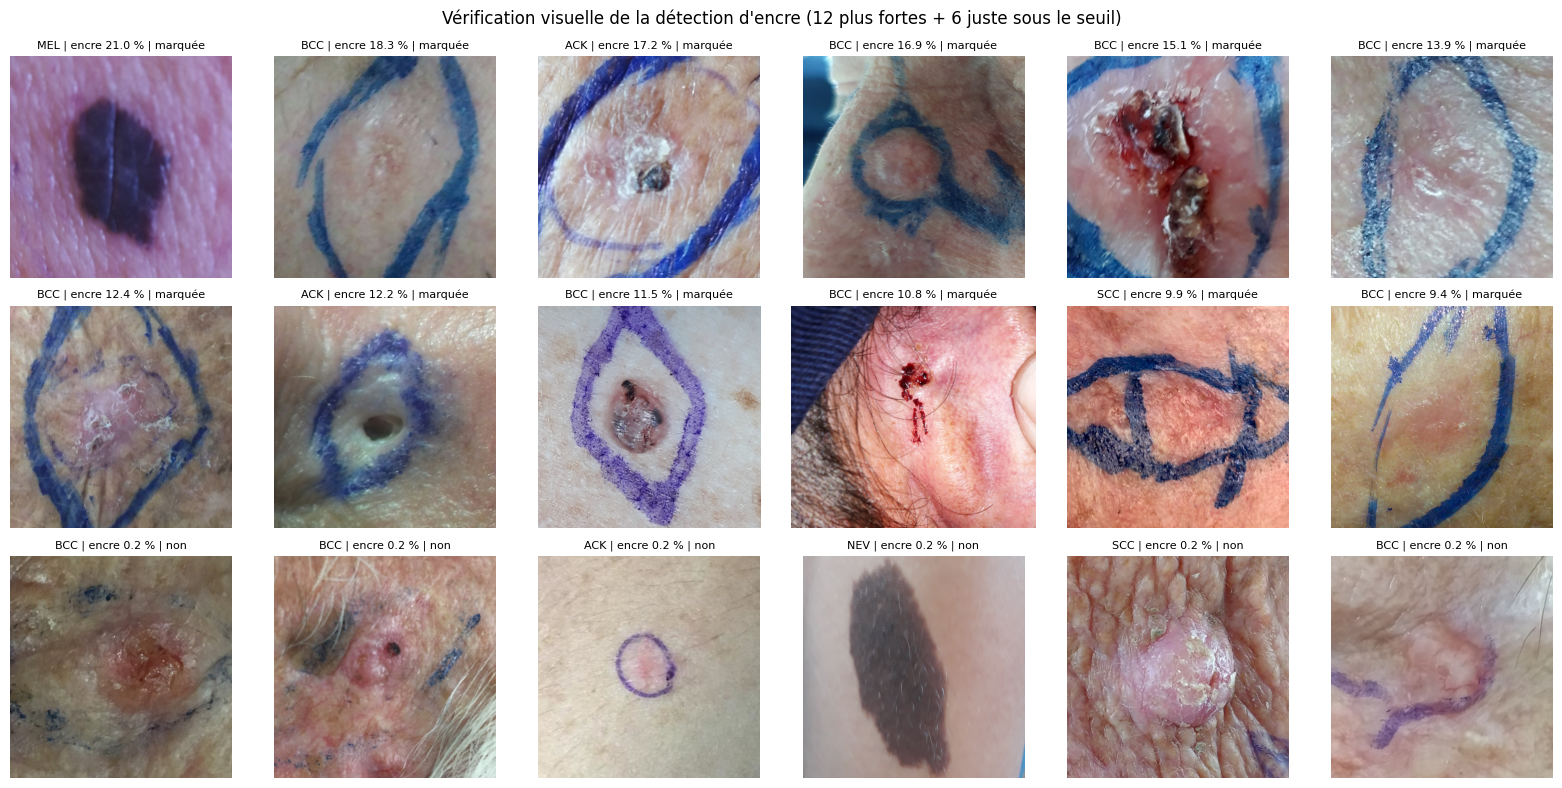

Concordance concept DermLIP « encre » / détection couleur : AUC 0.746


In [84]:
top_ink = ink.sort_values("fraction_encre", ascending=False)
gallery = pd.concat([top_ink.head(12), top_ink[top_ink["encre"] == 0].head(6)])
fig, axes = plt.subplots(3, 6, figsize=(16, 8))
for ax, (_, r) in zip(axes.ravel(), gallery.iterrows()):
    with Image.open(ROOT / df.set_index("img_id").loc[r["img_id"], "img_path"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"{r['diagnostic']} | encre {r['fraction_encre'] * 100:.1f} % | {'marquée' if r['encre'] else 'non'}", fontsize=8)
    ax.axis("off")
plt.suptitle("Vérification visuelle de la détection d'encre (12 plus fortes + 6 juste sous le seuil)")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_galerie_encre.png", dpi=110)
plt.show()

if "skin_marker_ink" in LABELS_FR:
    scores = pd.read_csv(PROCESSED_DIR / "concept_scores.csv").set_index("img_id").loc[ink["img_id"], "skin_marker_ink"]
    if ink["encre"].nunique() == 2:
        print(f"Concordance concept DermLIP « encre » / détection couleur : AUC {roc_auc_score(ink['encre'], scores):.3f}")

In [85]:
ink_test = ink.set_index("img_id").loc[test["img_id"], "encre"].to_numpy()
rows = []
for name, m in [("avec encre", ink_test == 1), ("sans encre", ink_test == 0)]:
    if m.sum() and len(set(y_test[m])) == 2:
        r = grouped_bootstrap(y_test[m], p_test[m], groups_test[m])
        rows.append({"groupe": name, "images": int(m.sum()), "% cancer": round(y_test[m].mean() * 100, 1),
                     "AUC": round(r["AUC"], 3), "IC95": f"{r['IC95 bas']:.3f} – {r['IC95 haut']:.3f}"})
    else:
        rows.append({"groupe": name, "images": int(m.sum()), "% cancer": None, "AUC": None, "IC95": "trop peu d'images"})
display(pd.DataFrame(rows))

N_INK_MAPS = 20
attention = []
for i in np.flatnonzero(ink_test == 1)[:N_INK_MAPS]:
    x, p0, heat = occlusion_map(int(i))
    mask = ink_mask(to_rgb(x))
    step = x.shape[1] // GRID
    cover = mask[:step * GRID, :step * GRID].reshape(GRID, step, GRID, step).mean(axis=(1, 3))
    positive = np.clip(heat, 0, None)
    if positive.sum() > 0 and cover.sum() > 0:
        attention.append({"img_id": test.loc[i, "img_id"],
                          "part de surface encre": cover.mean(),
                          "part d'importance sur l'encre": float((positive * cover).sum() / positive.sum())})
attention = pd.DataFrame(attention)
if len(attention):
    ratio = attention["part d'importance sur l'encre"].mean() / attention["part de surface encre"].mean()
    print(f"Rapport importance / surface sur l'encre : {ratio:.2f} "
          f"({'⚠ le modèle semble regarder l encre' if ratio > 1.5 else 'pas de sur-attention marquée'})")
else:
    ratio = None
    print("Pas d'image de test avec encre exploitable pour l'analyse d'attention.")

,groupe,images,% cancer,AUC,IC95
0,avec encre,11,54.5,1.000,1.000 – 1.000
1,sans encre,347,51.9,0.944,0.916 – 0.968


Rapport importance / surface sur l'encre : 1.53 (⚠ le modèle semble regarder l encre)


## 6. Rapport texte par gabarit

Le texte est **construit à partir des sorties déjà calculées** (probabilité, seuil, contributions, carte d'occlusion). Un modèle de langage pourrait le reformuler, mais ne reçoit jamais l'image et ne peut pas modifier la décision.

In [86]:
def value_fr(col, value):
    if pd.isna(value):
        return "non renseigné"
    if col == "age":
        return f"{value:.0f} ans"
    if col == "region":
        return str(value).lower()
    return "oui" if value >= 0.5 else "non"


def location_fr(heat):
    i, j = np.unravel_index(np.argmax(heat), heat.shape)
    vert = ["en haut", "au centre", "en bas"][min(2, i * 3 // GRID)]
    horiz = ["à gauche", "au centre", "à droite"][min(2, j * 3 // GRID)]
    return "au centre de l'image" if vert == horiz == "au centre" else f"{vert} {horiz} de l'image"


def generate_report(i_test):
    row, p = test.loc[i_test], p_test[i_test]
    contrib = local_contributions(X_test.iloc[[i_test]])

    def phrase(r):
        if r["type"] == "clinique":
            return f"{r['élément']} : {value_fr(r['clé'], row[r['clé']])} ({r['contribution']:+.2f})"
        return f"{r['élément']} ({r['contribution']:+.2f})"

    plus = [phrase(r) for _, r in contrib[contrib["contribution"] > 0.05].head(3).iterrows()]
    minus = [phrase(r) for _, r in contrib[contrib["contribution"] < -0.05].head(2).iterrows()]
    decision = ("suspicion de cancer : avis dermatologique recommandé" if p >= T_MAIN
                else "pas de signe fort de cancer selon le modèle : surveillance selon avis médical")
    _, _, heat = occlusion_map(i_test)
    lines = [
        f"Image {row['img_id']} — probabilité estimée de cancer : {p:.2f} (seuil de triage {T_MAIN:.2f}).",
        f"Conclusion du modèle : {decision}.",
        "Éléments en faveur : " + ("; ".join(plus) if plus else "aucun élément marquant") + ".",
        "Éléments en défaveur : " + ("; ".join(minus) if minus else "aucun élément marquant") + ".",
        f"Zone de l'image la plus déterminante : {location_fr(heat)}.",
        "Avertissement : outil d'aide à la décision, il ne remplace ni l'examen clinique ni la biopsie.",
    ]
    return "\n".join(lines)


reports = []
for kind, i in cases.items():
    text = generate_report(i)
    reports.append(f"### {kind.capitalize()} (diagnostic réel : {test.loc[i, 'diagnostic']})\n\n{text}\n")
    print(f"--- {kind} ---\n{text}\n")
(REPORT_DIR / "06_rapports_exemples.md").write_text("\n".join(reports), encoding="utf8")

--- vrai positif ---
Image PAT_460_893_307.png — probabilité estimée de cancer : 1.00 (seuil de triage 0.38).
Conclusion du modèle : suspicion de cancer : avis dermatologique recommandé.
Éléments en faveur : aspect global de l'image (+5.92); saignement : oui (+0.76); localisation : nose (+0.65).
Éléments en défaveur : aucun élément marquant.
Zone de l'image la plus déterminante : au centre de l'image.
Avertissement : outil d'aide à la décision, il ne remplace ni l'examen clinique ni la biopsie.

--- faux négatif ---
Image PAT_834_1572_430.png — probabilité estimée de cancer : 0.03 (seuil de triage 0.38).
Conclusion du modèle : pas de signe fort de cancer selon le modèle : surveillance selon avis médical.
Éléments en faveur : âge : 81 ans (+0.23).
Éléments en défaveur : aspect global de l'image (-3.43); démangeaison : non (-0.24).
Zone de l'image la plus déterminante : en haut au centre de l'image.
Avertissement : outil d'aide à la décision, il ne remplace ni l'examen clinique ni la bio

2084

## 7. Analyse des erreurs (seuil de triage)

,images,classés cancer (%),type d'erreur,erreurs (%)
diagnostic,,,,
ACK,100,21.0,faux positifs,21.0
BCC,144,99.3,faux négatifs,0.7
MEL,7,71.4,faux négatifs,28.6
NEV,39,17.9,faux positifs,17.9
SCC,35,91.4,faux négatifs,8.6
SEK,33,27.3,faux positifs,27.3


,images,erreurs (%)
region,,
SCALP,3.0,33.3
THIGH,4.0,25.0
ABDOMEN,5.0,20.0
BACK,46.0,17.4
ARM,36.0,16.7
HAND,20.0,15.0
NOSE,28.0,14.3
LIP,8.0,12.5


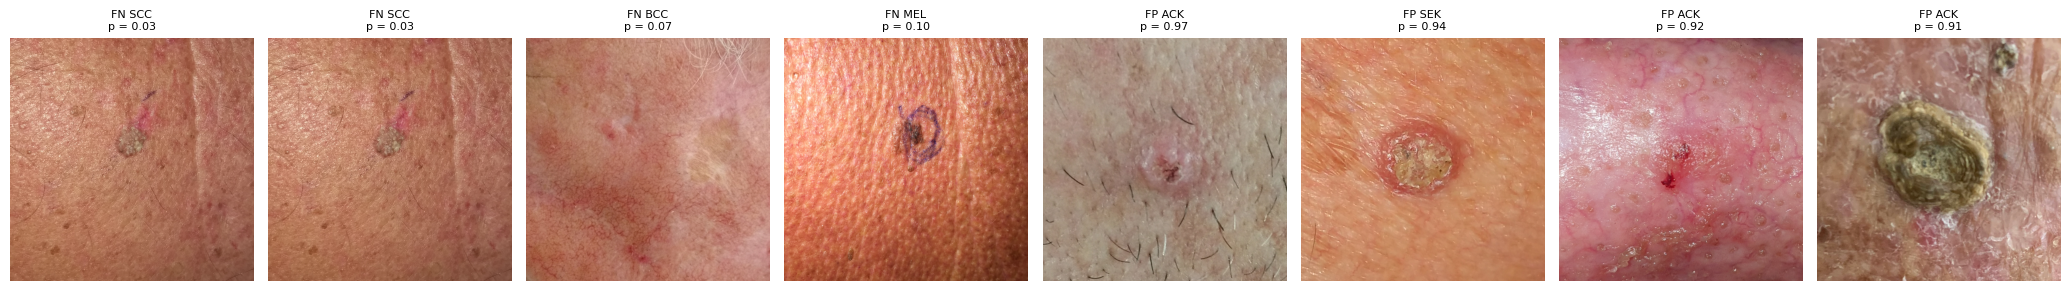

In [87]:
pred = (p_test >= T_MAIN).astype(int)
err = test.assign(proba=p_test, pred=pred, encre=ink_test)
by_diag = err.groupby("diagnostic").apply(lambda g: pd.Series({
    "images": len(g),
    "classés cancer (%)": round(g["pred"].mean() * 100, 1),
    "type d'erreur": "faux négatifs" if g["label"].iloc[0] == 1 else "faux positifs",
    "erreurs (%)": round(((g["pred"] != g["label"]).mean()) * 100, 1)}), include_groups=False)
display(by_diag)
by_region = err.groupby("region").apply(lambda g: pd.Series({
    "images": len(g), "erreurs (%)": round(((g["pred"] != g["label"]).mean()) * 100, 1)}), include_groups=False)
display(by_region.sort_values("erreurs (%)", ascending=False).head(8))

worst = pd.concat([err[(err["label"] == 1) & (err["pred"] == 0)].nsmallest(4, "proba"),
                   err[(err["label"] == 0) & (err["pred"] == 1)].nlargest(4, "proba")])
if len(worst):
    fig, axes = plt.subplots(1, len(worst), figsize=(2.6 * len(worst), 3.2), squeeze=False)
    for ax, (_, r) in zip(axes[0], worst.iterrows()):
        with Image.open(ROOT / r["img_path"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"{'FN' if r['label'] else 'FP'} {r['diagnostic']}\np = {r['proba']:.2f}", fontsize=8)
        ax.axis("off")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "06_erreurs.png", dpi=120)
    plt.show()

## 8. Analyse par phototype (Fitzpatrick)

Le phototype n'est renseigné que pour une partie des patients et les peaux foncées (IV–VI) sont très rares dans PAD-UFES-20 : ces chiffres sont **indicatifs** et constituent surtout une limite à signaler.

In [88]:
fitz = test["fitspatrick"]
rows = []
for name, m in [("I–II (claire)", fitz.isin([1, 2]).to_numpy()), ("III–VI", (fitz >= 3).to_numpy()),
                ("non renseigné", fitz.isna().to_numpy())]:
    row = {"phototype": name, "images": int(m.sum()), "% cancer": round(y_test[m].mean() * 100, 1) if m.sum() else None}
    if m.sum() >= 20 and len(set(y_test[m])) == 2:
        r = grouped_bootstrap(y_test[m], p_test[m], groups_test[m])
        row.update({"AUC": round(r["AUC"], 3), "IC95": f"{r['IC95 bas']:.3f} – {r['IC95 haut']:.3f}"})
    rows.append(row)
pd.DataFrame(rows)

,phototype,images,% cancer,AUC,IC95
0,I–II (claire),181,77.3,0.903,0.844 – 0.952
1,III–VI,68,67.6,0.953,0.889 – 0.993
2,non renseigné,109,0.0,NaN,NaN


## 9. Synthèse

In [89]:
synthesis = {
    "modele": bundle["nom"],
    "importance_modalites": modalities.set_index("élément")["baisse d'AUC"].round(4).to_dict(),
    "fidelite_occlusion": {"baisse_zones_designees": round(float(fidelity["baisse (zones désignées)"].mean()), 4),
                           "baisse_zones_hasard": round(float(fidelity["baisse (zones au hasard)"].mean()), 4),
                           "wilcoxon_p": float(stat.pvalue)},
    "encre": {"images_marquees": int(ink["encre"].sum()),
              "pourcentage_par_diagnostic": ink.groupby("diagnostic")["encre"].mean().mul(100).round(1).to_dict(),
              "rapport_importance_surface": None if ratio is None else round(float(ratio), 3)},
}
(REPORT_DIR / "06_synthese_xai.json").write_text(json.dumps(synthesis, indent=2, ensure_ascii=False), encoding="utf8")
print(json.dumps(synthesis, indent=2, ensure_ascii=False))

{
  "modele": "E6b Tardive image+clinique",
  "importance_modalites": {
    "image (plongement)": 0.3291,
    "image + concepts": 0.3232,
    "clinique": 0.0453,
    "concepts": 0.0
  },
  "fidelite_occlusion": {
    "baisse_zones_designees": 0.2914,
    "baisse_zones_hasard": 0.0118,
    "wilcoxon_p": 1.8189894035458565e-12
  },
  "encre": {
    "images_marquees": 97,
    "pourcentage_par_diagnostic": {
      "ACK": 4.2,
      "BCC": 5.0,
      "MEL": 15.4,
      "NEV": 2.9,
      "SCC": 4.2,
      "SEK": 0.4
    },
    "rapport_importance_surface": 1.535
  }
}


## Conclusion (à compléter après exécution)

- **Modalités** : laquelle porte la décision (section 1) — cohérent avec les poids de la porte (notebook 05) si le modèle à porte est retenu.
- **Fidélité** : la baisse « zones désignées » doit être nettement supérieure à la baisse « hasard » (p < 0,05) ; sinon les cartes ne doivent pas être présentées comme des explications fiables.
- **Encre** : fréquence par diagnostic, performance avec / sans encre, rapport d'attention. Un rapport > 1,5 ou une AUC très supérieure sur les images avec encre signale un raccourci à corriger (par exemple masquer l'encre ou exclure ces images à l'entraînement).
- **Erreurs** : diagnostics les plus manqués (mélanome ?) et faux positifs typiques (kératoses ?).
- **Limites** : phototypes foncés presque absents, mélanomes peu nombreux, explications locales approximatives pour un modèle non linéaire.